In [1]:
from IPython.core.display import display, HTML
display(HTML("<style>.container { width:100% !important; }</style>"))

C:\Users\tsusnjak\AppData\Local\Temp\ipykernel_276\3777615979.py:1: DeprecationWarning: Importing display from IPython.core.display is deprecated since IPython 7.14, please import from IPython display
  from IPython.core.display import display, HTML


# Introduction to Natural Language Processing

---

### Learning Outcomes

At the end of this lecture, you should be able to:

* describe the basic components of conducting NLP
* perform basic operations using the NLTK
* apply algorithms to documents in order to extract features, conduct sentiment analyses, topic discoveries and text similarities
* perform introductory level text analysis
* explain where NLP as a field is with respect to Language Model and Large Language Model advancements

Content in this notebook is based on material in :
>Russell, M. A. (2013). Mining the Social Web: Data Mining Facebook, Twitter, LinkedIn, Google+, GitHub, and More. " O'Reilly Media, Inc.". Chicago

> Bird, S., Klein, E., & Loper, E. (2009). Natural language processing with Python. " O'Reilly Media, Inc.".

---

# NLP Basics

### What is NLP?

- Using computers to process (analyze, understand, generate) natural human languages

### Why is NLP useful?

- Most knowledge created by humans is unstructured text
 - Need some way to make sense of it
 - Enables quantitative analysis of text data

### What are some of the higher level task areas?

 - **Speech recognition and generation**: Apple Siri
     - Speech to text
     - Text to speech
 - **Question answering**: IBM Watson
     - Match query with knowledge base
     - Reasoning about intent of question
 - **Machine translation**: Google Translate
     - One language to another to another
 - **Information retrieval**: Google
     - Finding relevant results
     - Finding similar results
 - **Information extraction**: Gmail
     - Structured information from unstructured documents
 - **Assistive technologies**: Google autocompletion
     - Predictive text input
     - Text simplification
 - **Natural Language Generation**: computer-generated articles
     - Generating text from data
 - **Automatic summarization**: Google News
     - Extractive summarization
     - Abstractive summarization
 - **Sentiment analysis**: Twitter analysis
     - Attitude of speaker

### What are some of the lower level components?

 - **Preprocessing**: text cleaning
 - **Tokenization**: breaking text into tokens (words, sentences, n-grams)
 - **Stopword removal**: a/an/the
 - **Stemming and lemmatization**: root word
 - **TF-IDF**: word importance
 - **Part-of-speech tagging**: noun/verb/adjective
 - **Named entity recognition**: person/organization/location
 - **Spelling correction**: "New Yrok City"
 - **Word sense disambiguation**: "buy a mouse"
 - **Segmentation**: "New York City subway"
 - **Language detection**: "translate this page"
 - **Machine learning**

### Why is NLP hard?

- **Ambiguity**:
     - Teacher Strikes Idle Kids
     - Red Tape Holds Up New Bridges
     - Hospitals are Sued by 7 Foot Doctors
     - Juvenile Court to Try Shooting Defendant
     - Local High School Dropouts Cut in Half
 - **Non-standard English**: tweets/text messages
 - **Idioms**: "throw in the towel"
 - **Newly coined words**: "retweet"
 - **Tricky entity names**: "Where is A Bug's Life playing?"
 - **World knowledge**: "Mary and Sue are sisters", "Mary and Sue are mothers"

### How does NLP work?

 - Build probabilistic model using data about a language
 - Requires an understanding of the language
 - Requires an understanding of the world (or a particular domain)

### What areas of NLP have we mostly solved?

 - ~~spam detection~~
 - ~~POS detection~~
 - ~~NER~~

### What areas of NLP are we making progress in?

 - ~~sentiment analysis~~
 - ~~parsing~~
 - ~~machine translation~~
 - ~~information extraction~~
 - ~~word sense disambiguation~~

### What areas of NLP are we still struggling with?

 - ~~Q&A~~
 - ~~paraphrasing~~
 - ~~summarisation~~
 - ~~unrestrained dialogue~~

Technologies based on NLP are becoming increasingly widespread. For example,phones and handheld computers support predictive text and handwriting recognition; web search engines give access to information locked up in unstructured text and machine
translation. On top of this, with the explosion in social media, text mining, text analytics and semantic analysis have become big areas or research.

NLP is important for scientific, economic, social, and cultural reasons. 

NLP is experiencing rapid growth as its theories and methods are deployed in a variety of new language
technologies. For this reason it is important for a wide range of people to have a
working knowledge of NLP. 

Within industry, this includes people in human-computer
interaction, business information analysis, and web software development. Within
academia, it includes people in areas from humanities computing and corpus linguistics
through to computer science and artificial intelligence. In academia, NLP is known by the name of “Computational Linguistics.”

> Bird, S., Klein, E., & Loper, E. (2009). Natural language processing with Python. " O'Reilly Media, Inc.".

<div style="background-color: lightblue; padding: 10px;">
    
# The Gamechanger - Generative AI

Generative AI and large language models (LLMs) have revolutionised Natural Language Processing (NLP) by enabling models to excel at a wide range of tasks that were previously either too complex or too domain-specific to solve efficiently. The introduction of transformer-based architectures like BERT and GPT has fundamentally altered how we approach NLP. These models leverage vast datasets and attention mechanisms to capture both local and global relationships within language, providing a deeper understanding of context, syntax, and semantics. The self-supervised pretraining followed by fine-tuning has made it possible for these models to generalise across a diverse array of tasks without task-specific architectures, including machine translation, summarisation, question answering, and conversational agents. This paradigm shift towards pre-trained language models has enabled performance that rivals, and in some cases surpasses, human-level capabilities in many linguistic tasks.

LLMs have also introduced new frontiers and challenges in the field:

### Unsolved Challenges in NLP

- **Factual Consistency and Coherence:** One of the major issues with current LLMs is maintaining long-term coherence and factual consistency in text generation, particularly in open-domain dialogues. Models like GPT are trained on large, unstructured corpora, which allows them to generate highly fluent text, but this training also introduces the risk of generating plausible but factually inaccurate or inconsistent outputs. This poses significant limitations for high-stakes applications, such as healthcare or legal domains, where accuracy is critical.
  
- **Comprehension of Ambiguous or Context-Sensitive Language:** While LLMs excel at surface-level fluency and pattern recognition, they often fall short when tasked with resolving ambiguous language or handling idiomatic expressions. Challenges like word-sense disambiguation, where a word's meaning depends heavily on context, remain an area where LLMs underperform. Similarly, accurately processing idiomatic phrases or culturally-specific expressions is still problematic. Models struggle to apply real-world or domain-specific knowledge required for deeper comprehension, which is critical for tasks like reasoning and decision making.

### Advances in Sentiment, Stance, and Emotion Detection

- **Sentiment Analysis:** LLMs have significantly advanced sentiment analysis by offering more nuanced understanding of text polarity. Earlier sentiment analysis models relied heavily on rule-based or shallow machine learning methods that performed well only on limited datasets. In contrast, models like BERT showed that they can capture deeper contextual sentiment, enabling the detection of subtler emotions like sarcasm, irony, and mixed sentiments within a single passage. This has resulted in more robust performance in real-world scenarios, such as social media analysis, product reviews, and public opinion tracking. Larger LLMs can now perform this task with more robustness.
  
- **Stance Detection:** Stance detection, the task of identifying the position or stance of a text with respect to a particular topic, has also benefited from LLMs. Unlike traditional classification tasks, stance detection requires the model to infer the implicit or explicit position expressed by the author, often across complex argumentative texts. LLMs have improved stance detection accuracy by better understanding the interplay between linguistic features like modality, tone, and implicit assumptions. This advancement is particularly impactful in analysing debates, policy discussions, and online forums.
  
- **Emotion Detection:** Another key area where LLMs have shown promise is emotion detection, where the goal is to recognise specific emotional states (e.g., joy, anger, sadness) in a given text. Unlike sentiment analysis, which focuses on the overall polarity of text, emotion detection is far more granular and complex, involving multiple dimensions of emotional expression. LLMs have demonstrated the ability to capture subtle emotional cues and variations in tone, even in highly context-dependent situations like personal narratives or customer feedback. This has opened up new possibilities for applications in areas like mental health monitoring, personalised content recommendation, and human-computer interaction.

### Future Frontiers in Language Modelling

While LLMs have made remarkable progress, several frontier areas remain unsolved or underexplored:

- **Integrating External Knowledge:** A critical limitation of current LLMs is their reliance on the data they were trained on, which is often outdated or incomplete. Future models will need to integrate external, up-to-date knowledge sources dynamically to ensure factual correctness and domain-specific understanding. Hybrid models that combine LLMs with structured knowledge bases or real-time information retrieval systems are an emerging area of research aimed at addressing this issue.
  
- **Long-Term Coherence and Multi-Turn Dialogue:** Although conversational agents have improved dramatically, LLMs still struggle with maintaining coherent, contextually consistent dialogue over multiple turns, especially in complex, goal-oriented conversations. Future models will need to incorporate more sophisticated mechanisms for tracking dialogue history and managing the long-term dependencies between conversation turns.
  
- **Fine-Grained Text Generation Control:** One of the ongoing challenges is how to control the output of LLMs to align with specific requirements, such as factual accuracy, tone, or domain-specific knowledge. Current approaches, such as fine-tuning and prompt engineering, are limited in their ability to precisely control the outputs. More advanced techniques, like differentiable programming and reinforcement learning for language models, are being explored to provide finer control over generated text.
  
- **Bias and Ethical Concerns:** While much progress has been made in reducing bias in LLMs, the issue remains a concern, especially as these models are deployed in sensitive applications. Bias can manifest in various forms, from gender and racial stereotypes to socio-political biases, and eliminating these while maintaining model performance is an ongoing challenge.

Generative AI has fundamentally altered the trajectory of NLP research and applications, but the next wave of innovation will focus on addressing these deeper challenges. The goal is to push LLMs towards a more sophisticated understanding of language, enabling not just better predictions and text generation but also the ability to reason, comprehend, and interact with the world in a manner that more closely mirrors human cognition.

</div>        


# Natural Language Toolkit (NLTK)

NLTK was originally created in 2001 as part of a computational linguistics course in
the Department of Computer and Information Science at the University of Pennsylvania.
Since then it has been developed and expanded with the help of dozens of contributors.
It has now been adopted in courses in dozens of universities, and serves as
the basis of many research projects.

One of the most important sources of texts is undoubtedly the Web. 

It’s convenient to have existing text collections to explore, such as the compiled corpora, but there is much analysis to be done on non compiled texts.

In [156]:
import pandas as pd
import numpy as np
import matplotlib as mtpl
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from pylab import rcParams
rcParams['figure.figsize'] = 15, 10
rcParams['font.size'] = 20
rcParams['figure.dpi'] = 350
rcParams['lines.linewidth'] = 2
rcParams['axes.facecolor'] = 'white'
rcParams['patch.edgecolor'] = 'white'
rcParams['font.family'] = 'StixGeneral'

In [157]:
import nltk

The following command enables us to download and install text corpora and extra packages through NLTK:

In [5]:
# nltk.download()
# #when the NLTK Donwloader window pops up, select the 'book' identifier and then press the download button to download att the necessary corpora

#you might have to change server index to: http://nltk.org/nltk_data/
# orig index https://raw.githubusercontent.com/nltk/nltk_data/gh-pages/index.xml

# Text Data Acquisition

In [158]:
import os
import sys
import json
import requests
import pandas as pd
from nltk import clean_html
from bs4 import BeautifulSoup as bs

Let's get text from an article on the web and do some processing of it:

https://quillette.com/2024/07/02/superintelligence-10-years-on-nick-bostrom-ai-safety-agi/

In [7]:
HTML_PAGE = 'https://quillette.com/2024/07/02/superintelligence-10-years-on-nick-bostrom-ai-safety-agi/'

response = requests.get(HTML_PAGE) 
response

<Response [200]>

In [8]:
page = response.content
page[:1000]

b'<!DOCTYPE html>\n<html lang="en">\n  <head>\n  <meta charset="utf-8" />\n  <meta http-equiv="X-UA-Compatible" content="IE=edge" />\n  <meta name="viewport" content="width=device-width, initial-scale=1" />\n\n  <link rel="stylesheet" href="https://use.typekit.net/snm7ylt.css" />\n\n  <link rel="stylesheet" type="text/css" href="/assets/built/app.css?v=b900d96558" />\n\n  <link rel="preconnect" href="https://fonts.googleapis.com" />\n  <link rel="preconnect" href="https://fonts.gstatic.com" crossorigin />\n  <link\n    href="https://fonts.googleapis.com/css2?family=Inter:ital,opsz,wght@0,14..32,100..900;1,14..32,100..900&family=Lora:ital,wght@0,400..700;1,400..700&family=Playfair+Display:ital,wght@0,400..900;1,400..900&display=swap"\n    rel="stylesheet"\n  />\n\n  <title>\n      \xe2\x80\x98Superintelligence,\xe2\x80\x99 Ten Years On\n  </title>\n\n  <!-- Google Tag Manager -->\n  <script>\n    (function (w, d, s, l, i) {\n      w[l] = w[l] || [];\n      w[l].push({ \'gtm.start\': new

# Text Preparation 

The page variable has all the markup symbols which we need to strip away first of all.

In [9]:
bs_object = bs(page, "lxml")  
raw = bs_object.get_text()
raw[:1000]

'\n\n\n\n\n\n\n\n\n\n\n      ‘Superintelligence,’ Ten Years On\n  \n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\nSkip to content\n\n\n\n\n\n\n\n\n\n\nClose menu\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n      Home\n    \n\n\n\n      Events\n    \n\n\n\n      Contribute\n    \n\n\n\n\n\n      Home\n    \n\n\n\n      Events\n    \n\n\n\n      Contribute\n    \n\n\n\n\n\n\nLog in\n\n\nSubscribe\n\n\n\n\n\n\n\n\n              Sections\n            \n\n\n\n                  Top Stories\n                \n\n\n\n                  Art and Culture\n                \n\n\n\n                  Politics\n                \n\n\n\n                  recent\n                \n\n\n\n                  Education\n                \n\n\n\n                  Podcast\n                \n\n\n\n                  History\n                \n\n\n\n     

We only get a partial job done. There is still a lot of rubbish in the text. 

In [10]:
#print len(raw)
print(raw.find('Published in 2014, Nick Bostrom'))
print(raw.find(' leaving humans free to flourish'))

start = raw.find('Published in 2014, Nick Bostrom')
end = raw.find(' leaving humans free to flourish')

2896
22322


In [11]:
cleaned_article = raw[start : end + len(' leaving humans free to flourish')]
cleaned_article

'Published in 2014, Nick Bostrom’s book\xa0Superintelligence:\xa0Paths, Dangers, Strategies\xa0has shaped the debate on AI alignment for the past decade. More than any other book on the topic, it is responsible for shifting concerns about AI safety from “silly” to “serious.” And while many prominent coders still think concerns about the “existential risk” of AI are misplaced, these issues are now receiving legislative attention mainly because key milestones defined by Bostrom (“oracles” and “genies”) have been passed by OpenAI.ChatGPT, launched in November 2022, is an “oracle” (a question and answer system). OpenAI released “Custom GPTs” that can be linked to actions (that meet Bostrom’s definition of “genies”) in November 2023. Bostrom argues that AI can plausibly develop into a “superintelligence”—also known as the “singularity,” “strong AI,” artificial general intelligence (AGI), and artificial superintelligence (ASI)—far more intelligent than its creators. His main claim is that AS

You will notice that after the text has been cleaned, there are still many special unicode characters in the text, which you may or may not want to remove for further processing.

## Processing Unicode Chars

Here is how to covert a unicode to ascii, ignoring and removing all unicode chars that cannot be represented in ascii:

In [12]:
import re

#Replace any non-ASCII character with a space
cleaned_article = re.sub(r'[^\x00-\x7F]', ' ', cleaned_article)


In [13]:
cleaned_article = cleaned_article.encode('ascii','ignore')
cleaned_article[:1000]


b'Published in 2014, Nick Bostrom s book Superintelligence: Paths, Dangers, Strategies has shaped the debate on AI alignment for the past decade. More than any other book on the topic, it is responsible for shifting concerns about AI safety from  silly  to  serious.  And while many prominent coders still think concerns about the  existential risk  of AI are misplaced, these issues are now receiving legislative attention mainly because key milestones defined by Bostrom ( oracles  and  genies ) have been passed by OpenAI.ChatGPT, launched in November 2022, is an  oracle  (a question and answer system). OpenAI released  Custom GPTs  that can be linked to actions (that meet Bostrom s definition of  genies ) in November 2023. Bostrom argues that AI can plausibly develop into a  superintelligence  also known as the  singularity,   strong AI,  artificial general intelligence (AGI), and artificial superintelligence (ASI) far more intelligent than its creators. His main claim is that ASI poses 

In [14]:
type(cleaned_article)

bytes

In [15]:
cleaned_article = str(cleaned_article)
cleaned_article

"b'Published in 2014, Nick Bostrom s book Superintelligence: Paths, Dangers, Strategies has shaped the debate on AI alignment for the past decade. More than any other book on the topic, it is responsible for shifting concerns about AI safety from  silly  to  serious.  And while many prominent coders still think concerns about the  existential risk  of AI are misplaced, these issues are now receiving legislative attention mainly because key milestones defined by Bostrom ( oracles  and  genies ) have been passed by OpenAI.ChatGPT, launched in November 2022, is an  oracle  (a question and answer system). OpenAI released  Custom GPTs  that can be linked to actions (that meet Bostrom s definition of  genies ) in November 2023. Bostrom argues that AI can plausibly develop into a  superintelligence  also known as the  singularity,   strong AI,  artificial general intelligence (AGI), and artificial superintelligence (ASI) far more intelligent than its creators. His main claim is that ASI poses

**Exercise:** Your goal is to extract the relevant text from the url below, clean it, and store it as a string in  a variable called cleaned_article2.

https://quillette.com/2025/09/07/chatgpt-5-and-the-limits-of-machine-intelligence-agi/

Below is the text of the full article as backup in case you cannot access it:

In [16]:
HTML_PAGE = 'https://quillette.com/2025/09/07/chatgpt-5-and-the-limits-of-machine-intelligence-agi/'
#get response
response = requests.get(HTML_PAGE) 
page = response.content
# page[:1000] #check point, view progress
#make beautiful soup
bs_object = bs(page, "lxml")  
raw = bs_object.get_text()
# raw[:1000] #check point, view progress

print(raw.find('Disappointment and a sense of deflation'))
print(raw.find('reanimate the map with meaning.'))

start = raw.find('Disappointment and a sense of deflation')
end = raw.find('reanimate the map with meaning.')

cleaned_article2 = raw[start : end + len('reanimate the map with meaning.')]
# cleaned_article2

# #Replace any non-ASCII character with a space
cleaned_article2 = re.sub(r'[^\x00-\x7F]', ' ', cleaned_article2)

# cleaned_article2


2811
9396


In [17]:
type(cleaned_article2)

str

In [18]:
cleaned_article2 = cleaned_article2.encode('ascii','ignore')
cleaned_article2[:1000]

cleaned_article2 = str(cleaned_article2)
cleaned_article2

"b'Disappointment and a sense of deflation, but no longer denial. Following the release of OpenAI s GPT-5, the internet was soon awash with tweets and posts from industry insiders reluctantly acknowledging the work of Silicon Valley gadfly Gary Marcus. Since the late 2010s, the cognitive scientist has warned of the limits of large language models (LLMs) much to the chagrin of deep learning enthusiasts and figures like OpenAI CEO Sam Altman, who have publicly championed a more heady narrative. Marcus s critique hinges on what he sees as the inherent fragility of deep learning: a data- and energy-hungry, brute-force approach to  understanding  and generating natural language that has proven dazzling yet fundamentally brittle. Those scare quotes are warranted. LLMs do not understand anything not in the way we ordinarily mean the term. Instead, these vast symbol-manipulating machines use enormous computational resources to predict the most statistically likely next word or token, based on 

# Text Tokenization 

In [19]:
type(cleaned_article)

str

In compiler and linguistic technical terms, characters combine to define **tokens**. 

**Tokens** are are individual words, symbols or numbers that have some meaning. Before any sense can be made of a text, it must first be tokenized into individual tokens.

In [20]:
some_text  = 'I went to uni today. I had lots of fun!'

tokens = nltk.word_tokenize(some_text)
tokens

['I', 'went', 'to', 'uni', 'today', '.', 'I', 'had', 'lots', 'of', 'fun', '!']

In [21]:
tokenized_article = nltk.word_tokenize(cleaned_article)
tokenized_article[:20]

["b'Published",
 'in',
 '2014',
 ',',
 'Nick',
 'Bostrom',
 's',
 'book',
 'Superintelligence',
 ':',
 'Paths',
 ',',
 'Dangers',
 ',',
 'Strategies',
 'has',
 'shaped',
 'the',
 'debate',
 'on']

## Create a user-defined tokenizer

In order to do full semantic analysis or machine translation of a piece of text, it is necessary to retain symbols that might be a part of speech and impart meaning. 

There are however times when we want to remove them altogether. Below is a piece of code that creates a custom tokenizer which strips symbols from a string and converts into a list of tokens.

In [22]:
from nltk.tokenize import RegexpTokenizer

#w means tokens are made of only alphanumeric characters where + indicates that they comprise of one or more of such characters
tokenizer = RegexpTokenizer('\\w+')

Rules for writing regular expressions can be found here: https://docs.python.org/2/howto/regex.html

In [23]:
tokens_cleaned = tokenizer.tokenize(some_text)
tokens_cleaned

['I', 'went', 'to', 'uni', 'today', 'I', 'had', 'lots', 'of', 'fun']

We can take the *cleaned_article* string from the first example and create a NLTK Text object out of it which enables us to perform some additional operations on the text.

In [24]:
tokenized_article = tokenizer.tokenize(cleaned_article)
tokenized_article[:100]

['b',
 'Published',
 'in',
 '2014',
 'Nick',
 'Bostrom',
 's',
 'book',
 'Superintelligence',
 'Paths',
 'Dangers',
 'Strategies',
 'has',
 'shaped',
 'the',
 'debate',
 'on',
 'AI',
 'alignment',
 'for',
 'the',
 'past',
 'decade',
 'More',
 'than',
 'any',
 'other',
 'book',
 'on',
 'the',
 'topic',
 'it',
 'is',
 'responsible',
 'for',
 'shifting',
 'concerns',
 'about',
 'AI',
 'safety',
 'from',
 'silly',
 'to',
 'serious',
 'And',
 'while',
 'many',
 'prominent',
 'coders',
 'still',
 'think',
 'concerns',
 'about',
 'the',
 'existential',
 'risk',
 'of',
 'AI',
 'are',
 'misplaced',
 'these',
 'issues',
 'are',
 'now',
 'receiving',
 'legislative',
 'attention',
 'mainly',
 'because',
 'key',
 'milestones',
 'defined',
 'by',
 'Bostrom',
 'oracles',
 'and',
 'genies',
 'have',
 'been',
 'passed',
 'by',
 'OpenAI',
 'ChatGPT',
 'launched',
 'in',
 'November',
 '2022',
 'is',
 'an',
 'oracle',
 'a',
 'question',
 'and',
 'answer',
 'system',
 'OpenAI',
 'released',
 'Custom',
 'GP

### NLTK Text Object

We now create the Text object from it which gives us a number of methods that we can perform on it.

In [25]:
text_article = nltk.Text(tokenized_article)
text_article

<Text: b Published in 2014 Nick Bostrom s book...>

In [26]:
type(text_article)

nltk.text.Text

We can now search for words or phrases in this Text and be shown the context in which they appear:

In [27]:
text_article.concordance('AI',width=150, lines = 52)

Displaying 52 of 52 matches:
 book Superintelligence Paths Dangers Strategies has shaped the debate on AI alignment for the past decade More than any other book on the topic it is
any other book on the topic it is responsible for shifting concerns about AI safety from silly to serious And while many prominent coders still think 
 many prominent coders still think concerns about the existential risk of AI are misplaced these issues are now receiving legislative attention mainly
 meet Bostrom s definition of genies in November 2023 Bostrom argues that AI can plausibly develop into a superintelligence also known as the singular
bly develop into a superintelligence also known as the singularity strong AI artificial general intelligence AGI and artificial superintelligence ASI 
hat can act Sovereigns digital government Tools most existing non chatbot AI The consequences of machine intelligent optimisation are likely to be Mal
kely to be Malthusian for humanity Getting values into a superint

**Exercise:** Perform the same steps in order to create a Text object from the article you cleaned previously and perform a concordance search for the term "LLMs".

In [28]:
tokenized_article2 = tokenizer.tokenize(cleaned_article2)
# tokenized_article2[:100] #check point progress view
text_article2 = nltk.Text(tokenized_article2)
# text_article2 #check point progress view

text_article2.concordance('LLMs',width=150, lines = 52)

Displaying 3 of 3 matches:
he cognitive scientist has warned of the limits of large language models LLMs much to the chagrin of deep learning enthusiasts and figures like OpenAI
oven dazzling yet fundamentally brittle Those scare quotes are warranted LLMs do not understand anything not in the way we ordinarily mean the term In
being Just as Marcus objects to the flawed assumptions underlying modern LLMs Dreyfus warned that no machine no matter how powerful could achieve genu


## Plotting Word Frequencies

We can plot the frequencies of the most commonly occuring words (30 in this example):

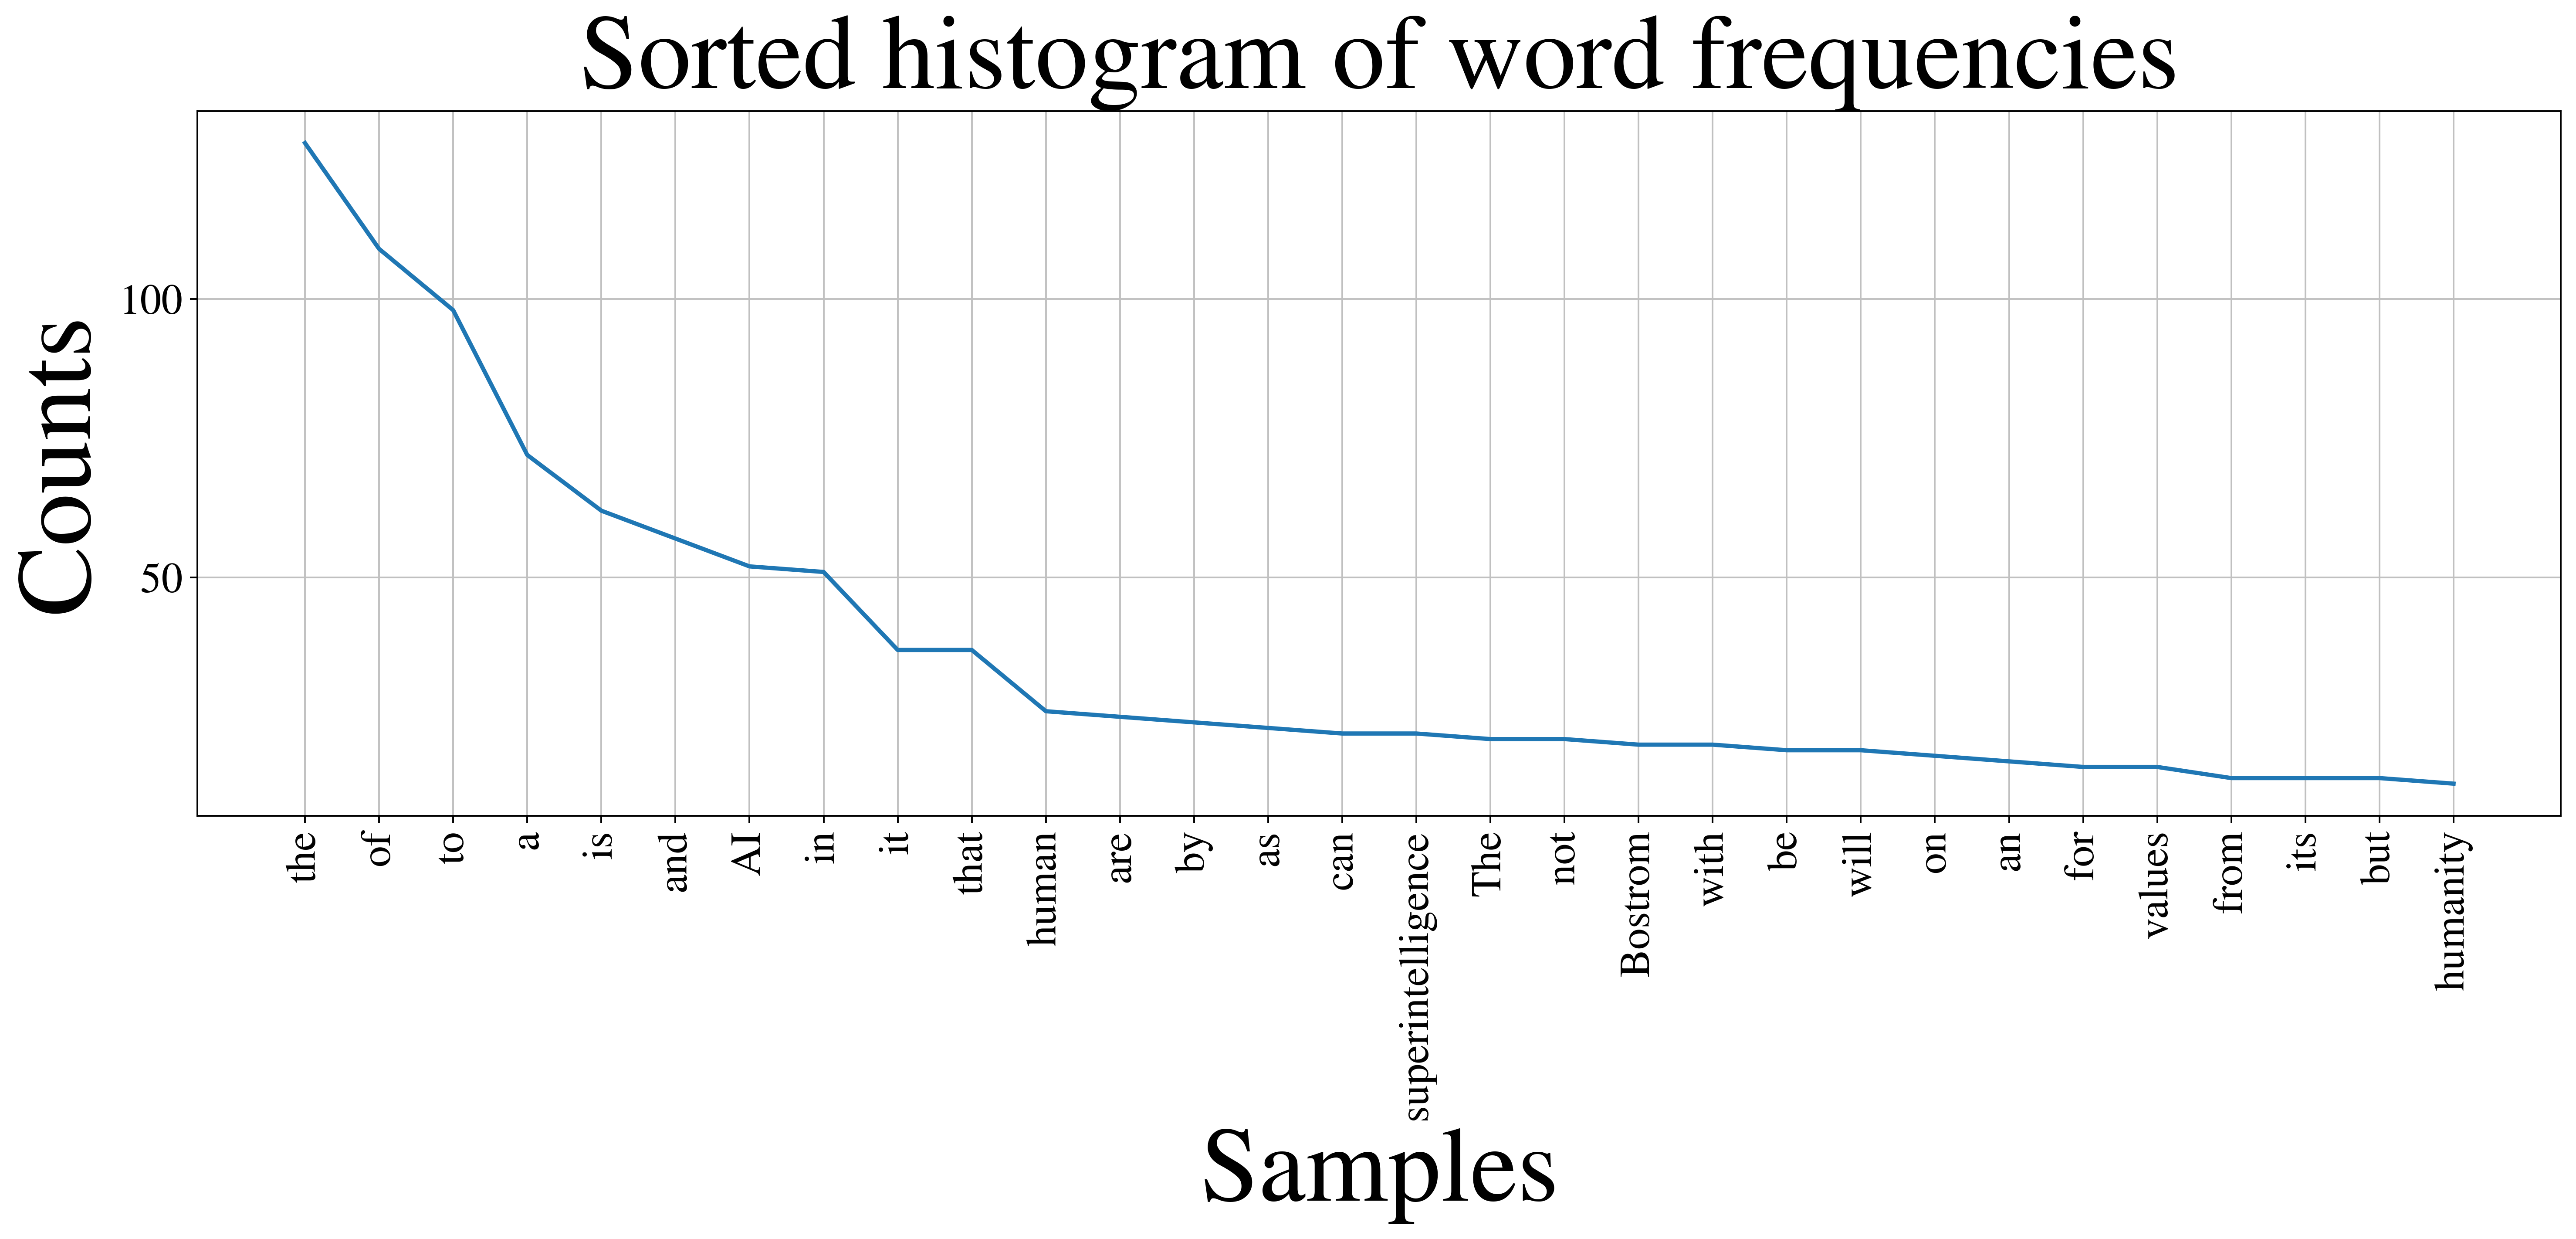

In [29]:
f = plt.figure( figsize=(20, 6))
plt.xlabel('Words', size=50)
plt.ylabel('Counts', size=50)
plt.title('Sorted histogram of word frequencies', size=50)
rcParams['xtick.labelsize'] = 30
rcParams['ytick.labelsize'] = 30
text_article.plot(30)
ax = f.get_axes()
plt.show()

**Exercise:** Plot the word frequencies for the article you cleaned previously.

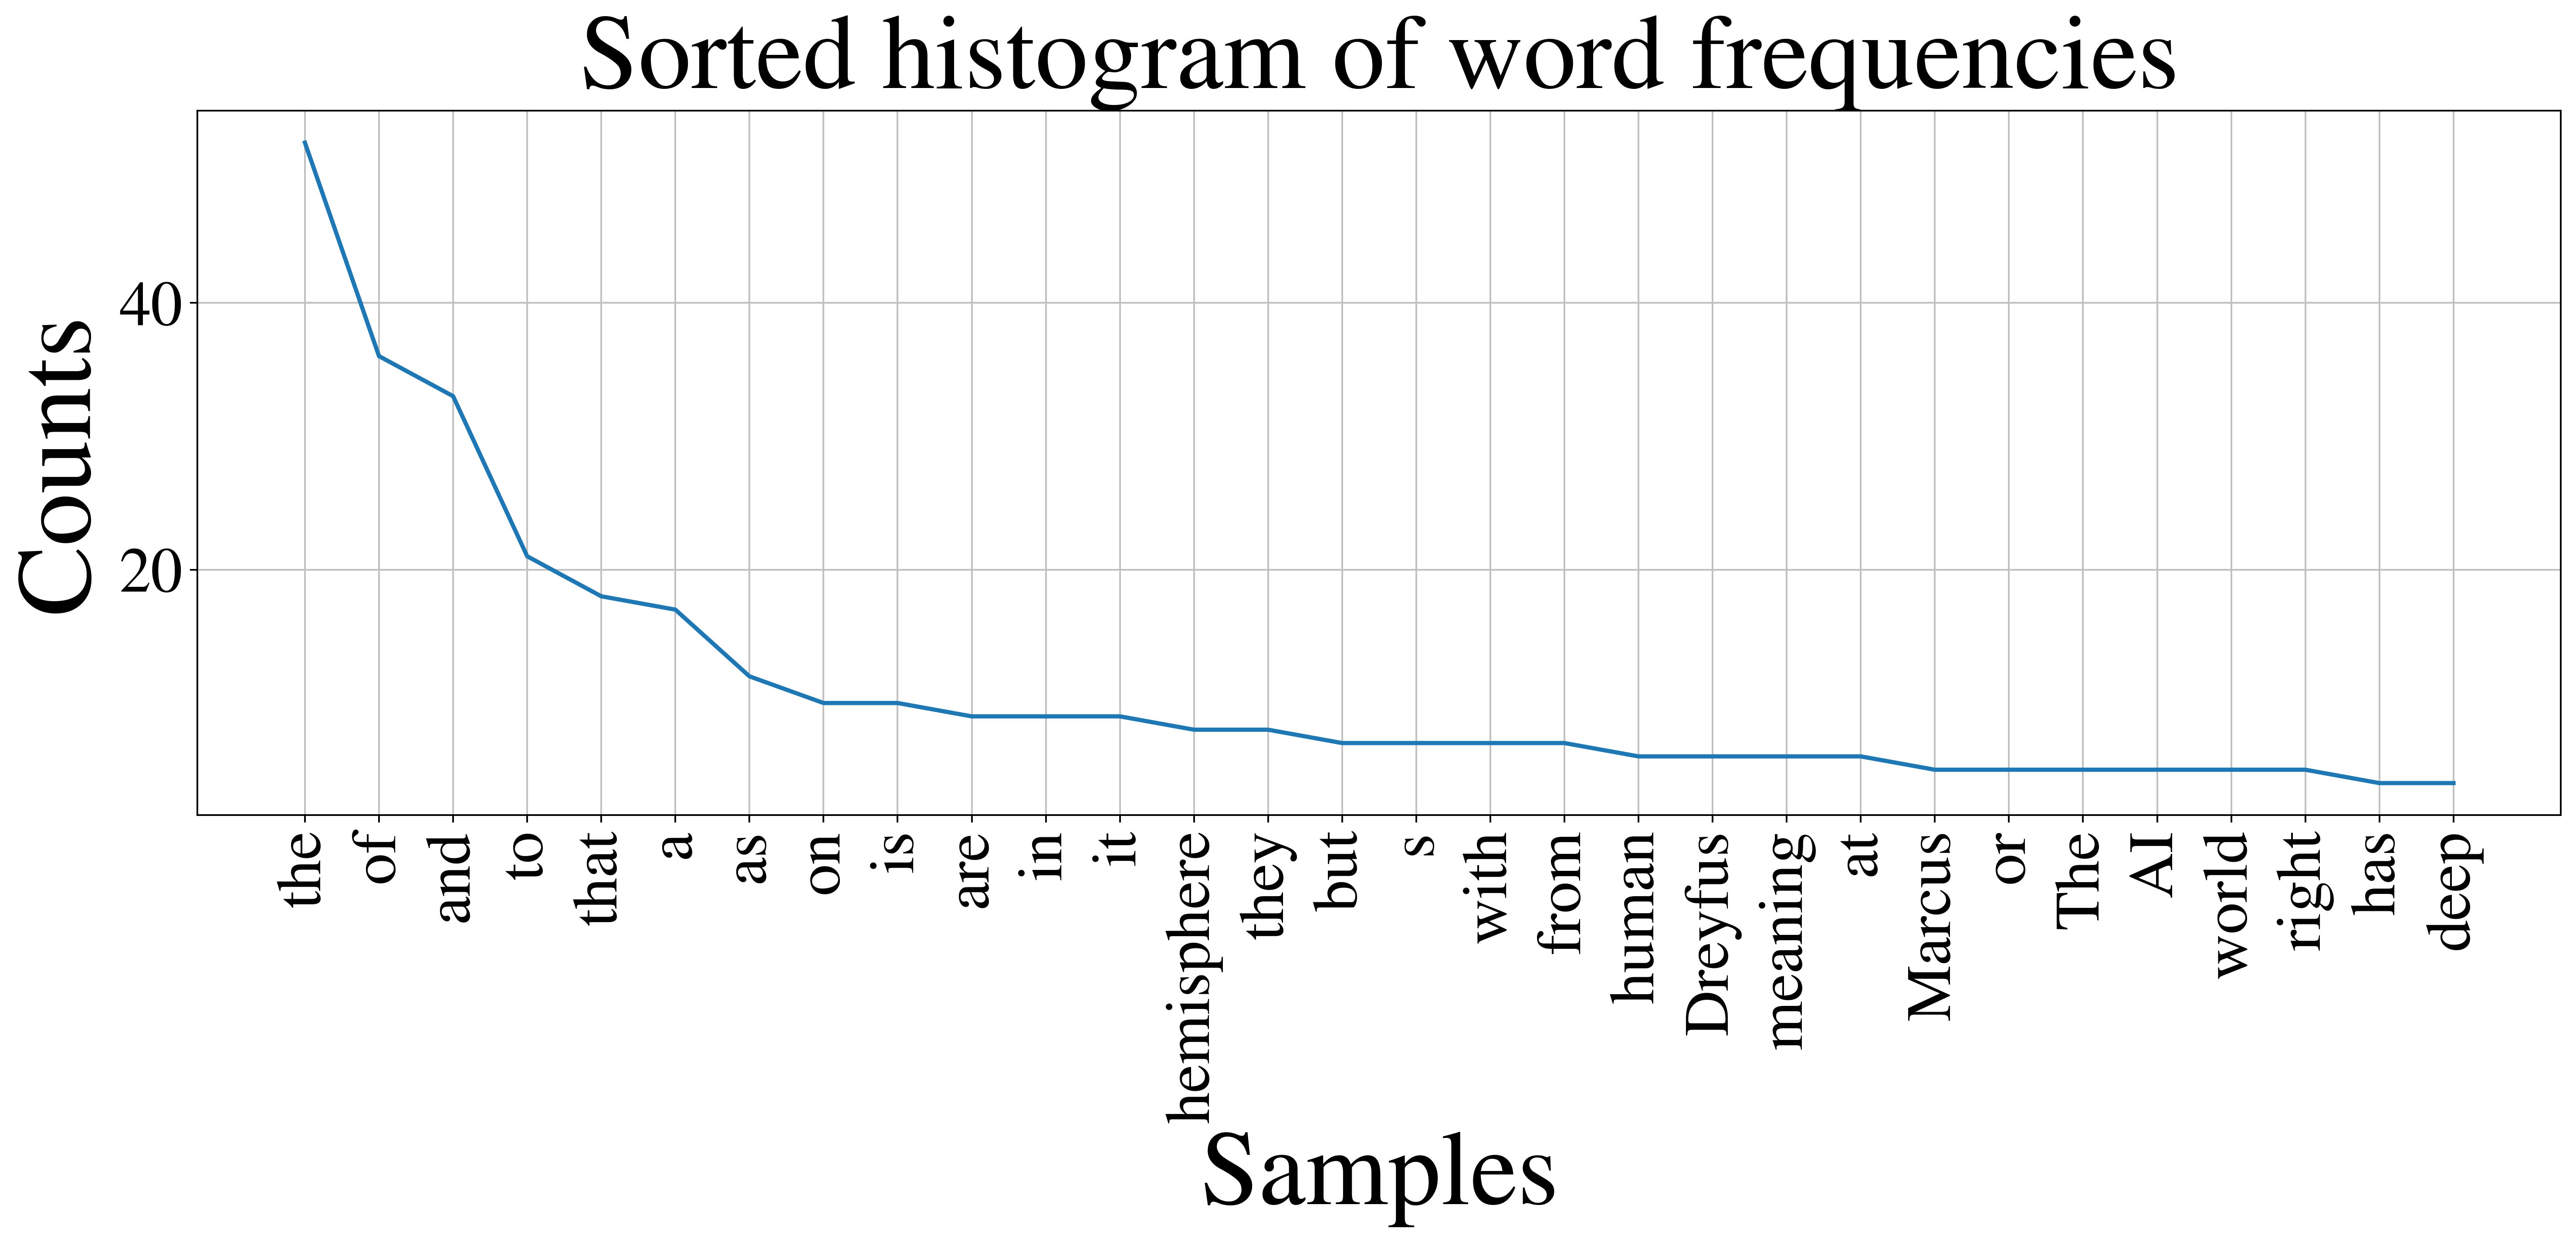

In [30]:
f = plt.figure( figsize=(20, 6))
plt.xlabel('Words', size=50)
plt.ylabel('Counts', size=50)
plt.title('Sorted histogram of word frequencies', size=50)
rcParams['xtick.labelsize'] = 30
rcParams['ytick.labelsize'] = 30
text_article2.plot(30)
ax = f.get_axes()
plt.show()

## Sentence-level tokenization

In [31]:
nltk.sent_tokenize(cleaned_article)[:5]

["b'Published in 2014, Nick Bostrom s book Superintelligence: Paths, Dangers, Strategies has shaped the debate on AI alignment for the past decade.",
 'More than any other book on the topic, it is responsible for shifting concerns about AI safety from  silly  to  serious.',
 'And while many prominent coders still think concerns about the  existential risk  of AI are misplaced, these issues are now receiving legislative attention mainly because key milestones defined by Bostrom ( oracles  and  genies ) have been passed by OpenAI.ChatGPT, launched in November 2022, is an  oracle  (a question and answer system).',
 'OpenAI released  Custom GPTs  that can be linked to actions (that meet Bostrom s definition of  genies ) in November 2023.',
 'Bostrom argues that AI can plausibly develop into a  superintelligence  also known as the  singularity,   strong AI,  artificial general intelligence (AGI), and artificial superintelligence (ASI) far more intelligent than its creators.']

# Text Cleaning 

## Non-English Words and Spelling Errors

In [32]:
#all valid English words according to this corpus
nltk.corpus.words.words()[:30]

['A',
 'a',
 'aa',
 'aal',
 'aalii',
 'aam',
 'Aani',
 'aardvark',
 'aardwolf',
 'Aaron',
 'Aaronic',
 'Aaronical',
 'Aaronite',
 'Aaronitic',
 'Aaru',
 'Ab',
 'aba',
 'Ababdeh',
 'Ababua',
 'abac',
 'abaca',
 'abacate',
 'abacay',
 'abacinate',
 'abacination',
 'abaciscus',
 'abacist',
 'aback',
 'abactinal',
 'abactinally']

In [33]:
tokenized_article[:10]

['b',
 'Published',
 'in',
 '2014',
 'Nick',
 'Bostrom',
 's',
 'book',
 'Superintelligence',
 'Paths']

In [34]:
valid_words = set(word for word in tokenized_article[:10] if  word.lower() in nltk.corpus.words.words())
valid_words

{'Nick', 'b', 'book', 'in', 's'}

## Stopwords

Notice that the **collection of elements from the text comprises of elements which are not all words**. 

Some words may be misspelled as well in which case we might want to take them out. 

Below is an example of how we can extract only words from a given text that appear in a dictionary from a corpus. This command is not something you want to execute on  a large corpus though since it is slow:

There is also a corpus of **stopwords**, that is, high-frequency words such as: the, to etc that we sometimes want to filter out of a document before further processing. 

Stopwords usually have little lexical content or meaning, and their presence in a text thus fails to distinguish
it from other texts.

In [35]:
from nltk.corpus import stopwords
stopwords = stopwords.words('english')
stopwords[0:300]

['a',
 'about',
 'above',
 'after',
 'again',
 'against',
 'ain',
 'all',
 'am',
 'an',
 'and',
 'any',
 'are',
 'aren',
 "aren't",
 'as',
 'at',
 'be',
 'because',
 'been',
 'before',
 'being',
 'below',
 'between',
 'both',
 'but',
 'by',
 'can',
 'couldn',
 "couldn't",
 'd',
 'did',
 'didn',
 "didn't",
 'do',
 'does',
 'doesn',
 "doesn't",
 'doing',
 'don',
 "don't",
 'down',
 'during',
 'each',
 'few',
 'for',
 'from',
 'further',
 'had',
 'hadn',
 "hadn't",
 'has',
 'hasn',
 "hasn't",
 'have',
 'haven',
 "haven't",
 'having',
 'he',
 "he'd",
 "he'll",
 'her',
 'here',
 'hers',
 'herself',
 "he's",
 'him',
 'himself',
 'his',
 'how',
 'i',
 "i'd",
 'if',
 "i'll",
 "i'm",
 'in',
 'into',
 'is',
 'isn',
 "isn't",
 'it',
 "it'd",
 "it'll",
 "it's",
 'its',
 'itself',
 "i've",
 'just',
 'll',
 'm',
 'ma',
 'me',
 'mightn',
 "mightn't",
 'more',
 'most',
 'mustn',
 "mustn't",
 'my',
 'myself',
 'needn',
 "needn't",
 'no',
 'nor',
 'not',
 'now',
 'o',
 'of',
 'off',
 'on',
 'once',
 'on

We can remove all the stop words from our list of tokens:

In [36]:
print(tokenized_article[:100])
[word for word in tokenized_article if word.lower() not in stopwords][:30]

['b', 'Published', 'in', '2014', 'Nick', 'Bostrom', 's', 'book', 'Superintelligence', 'Paths', 'Dangers', 'Strategies', 'has', 'shaped', 'the', 'debate', 'on', 'AI', 'alignment', 'for', 'the', 'past', 'decade', 'More', 'than', 'any', 'other', 'book', 'on', 'the', 'topic', 'it', 'is', 'responsible', 'for', 'shifting', 'concerns', 'about', 'AI', 'safety', 'from', 'silly', 'to', 'serious', 'And', 'while', 'many', 'prominent', 'coders', 'still', 'think', 'concerns', 'about', 'the', 'existential', 'risk', 'of', 'AI', 'are', 'misplaced', 'these', 'issues', 'are', 'now', 'receiving', 'legislative', 'attention', 'mainly', 'because', 'key', 'milestones', 'defined', 'by', 'Bostrom', 'oracles', 'and', 'genies', 'have', 'been', 'passed', 'by', 'OpenAI', 'ChatGPT', 'launched', 'in', 'November', '2022', 'is', 'an', 'oracle', 'a', 'question', 'and', 'answer', 'system', 'OpenAI', 'released', 'Custom', 'GPTs', 'that']


['b',
 'Published',
 '2014',
 'Nick',
 'Bostrom',
 'book',
 'Superintelligence',
 'Paths',
 'Dangers',
 'Strategies',
 'shaped',
 'debate',
 'AI',
 'alignment',
 'past',
 'decade',
 'book',
 'topic',
 'responsible',
 'shifting',
 'concerns',
 'AI',
 'safety',
 'silly',
 'serious',
 'many',
 'prominent',
 'coders',
 'still',
 'think']

**Exercise:** Create another Text object from the article in the previous exercises which this time has all the stopwords removed from it and plot the 30 most frequently occuring words:

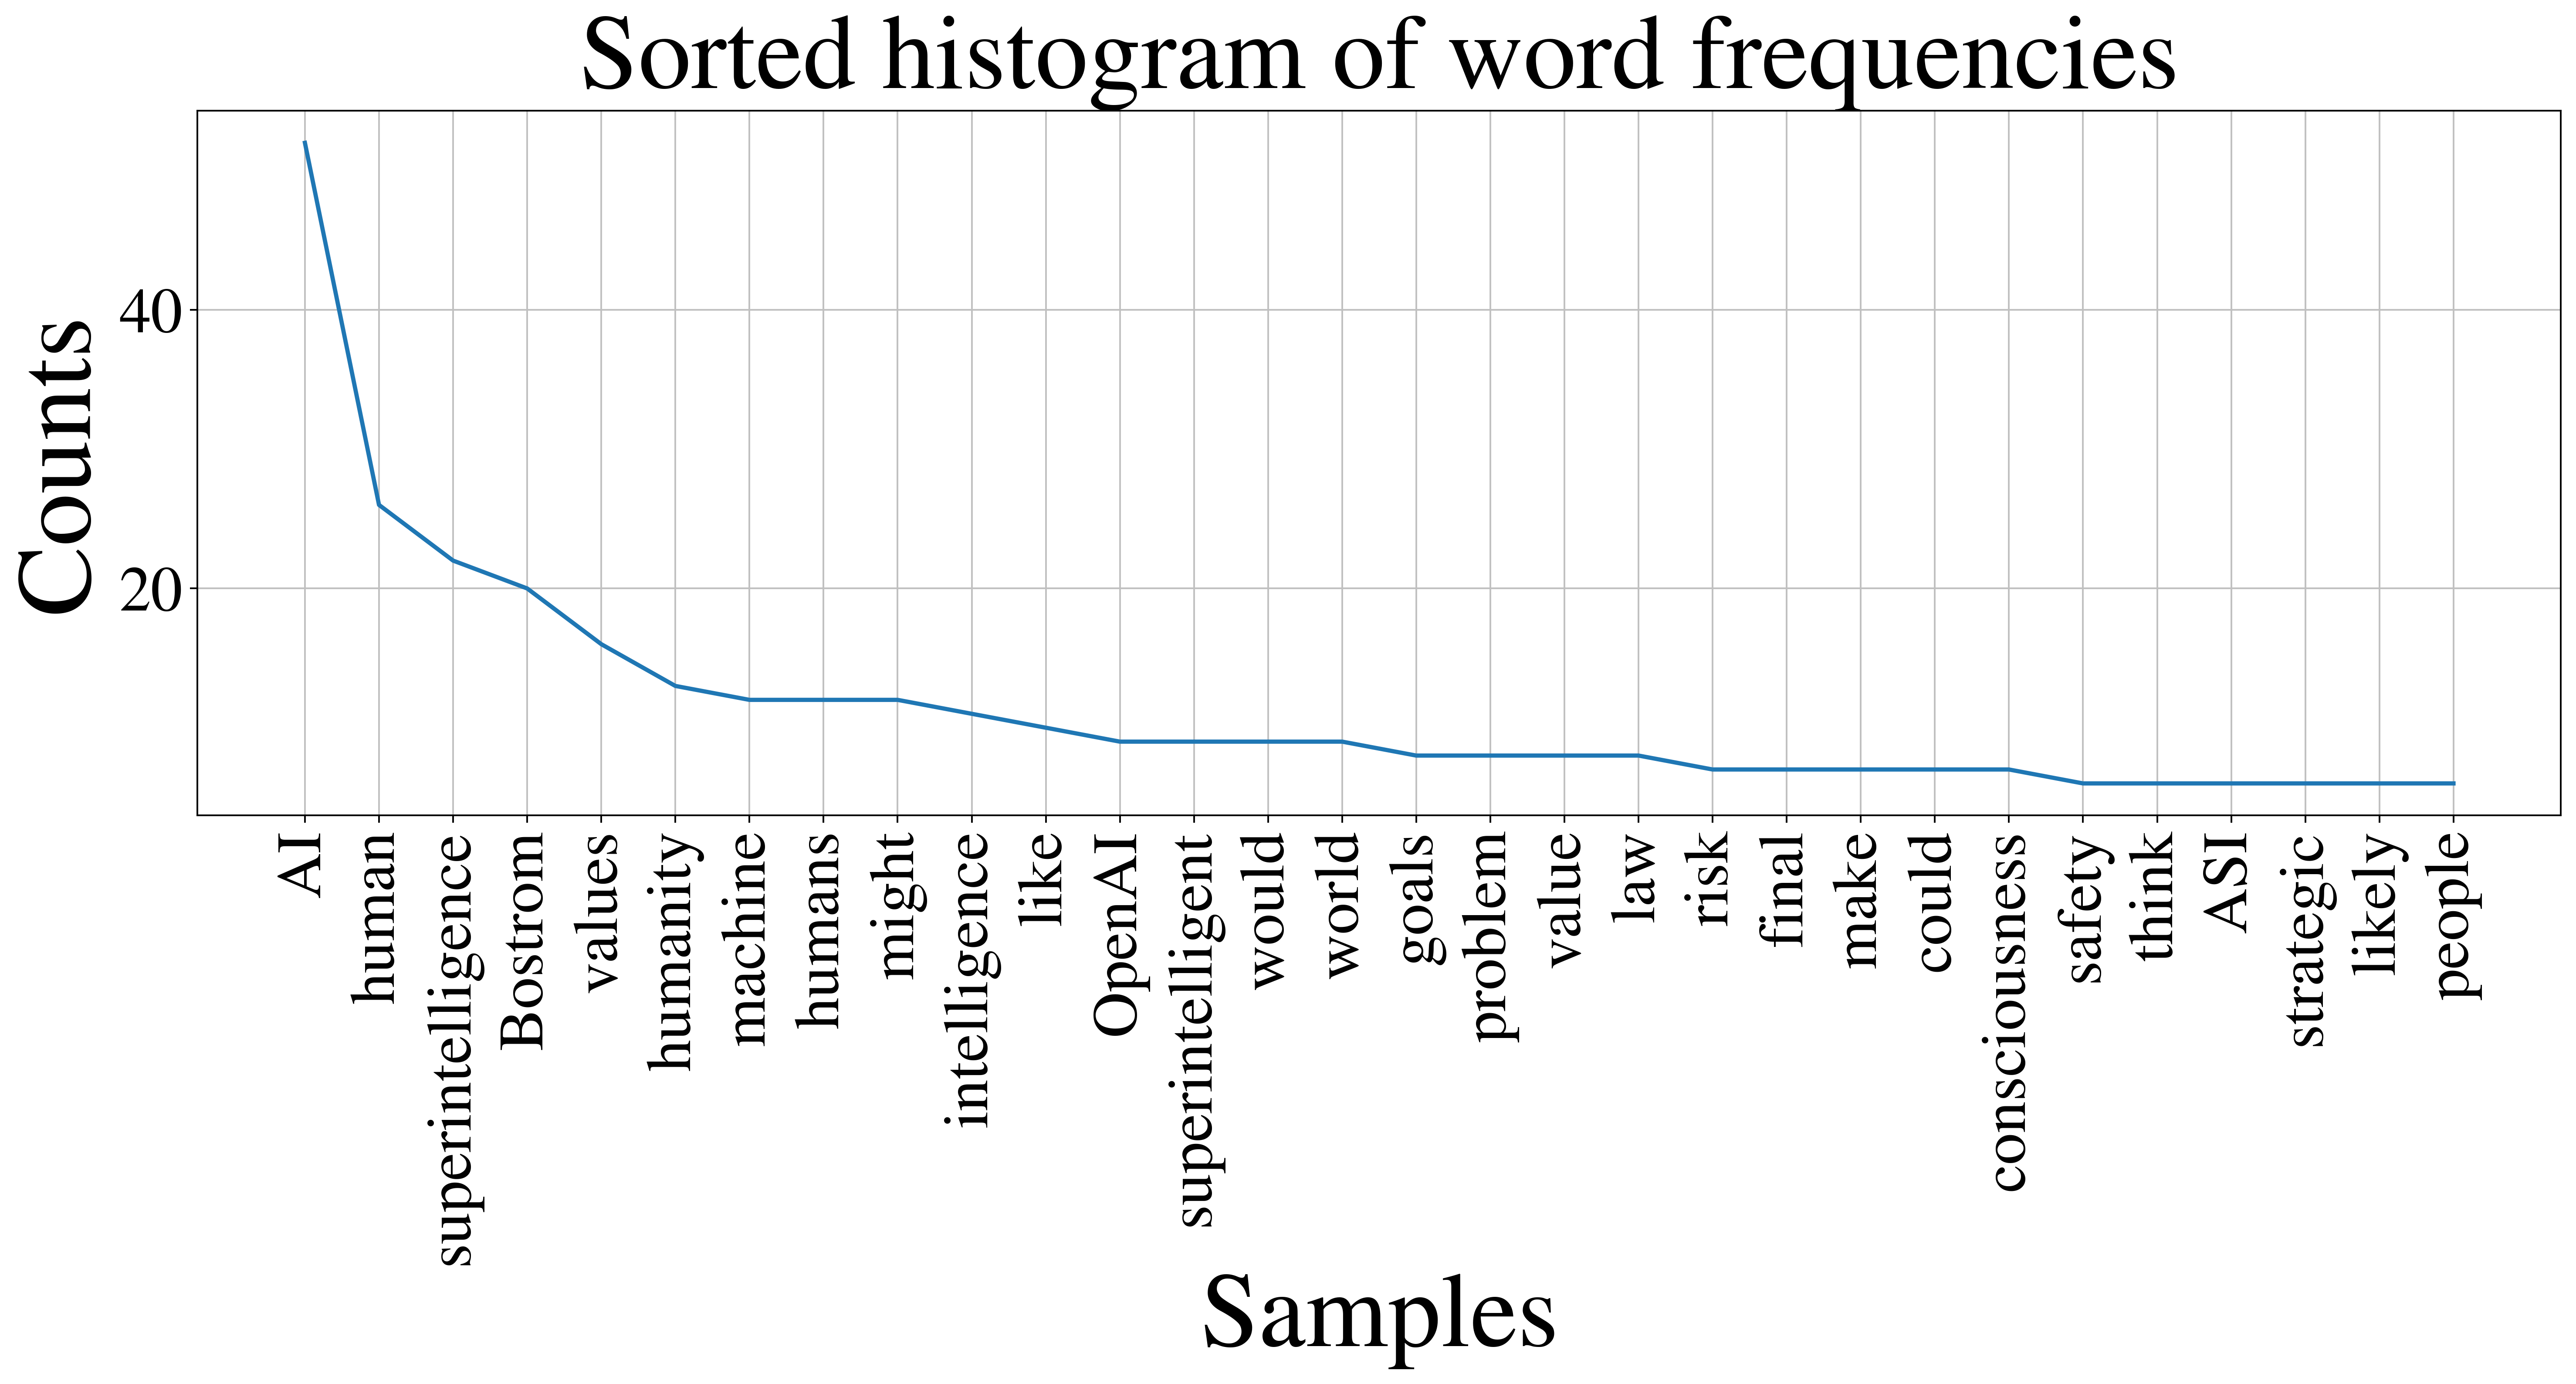

In [37]:
tokenized_article_stop = [word for word in tokenized_article if word.lower() not in stopwords]
text_article_stop = nltk.Text(tokenized_article_stop) #need to use a text object, not a list

f = plt.figure( figsize=(20, 6))
plt.xlabel('Words', size=50)
plt.ylabel('Counts', size=50)
plt.title('Sorted histogram of word frequencies', size=50)
rcParams['xtick.labelsize'] = 30
rcParams['ytick.labelsize'] = 30
text_article_stop.plot(30)
ax = f.get_axes()
plt.show()

In [38]:
tokenized_article2_stop = [word for word in tokenized_article2 if word.lower() not in stopwords]
text_article2_stop = nltk.Text(tokenized_article2_stop) #need to use a text object, not a list


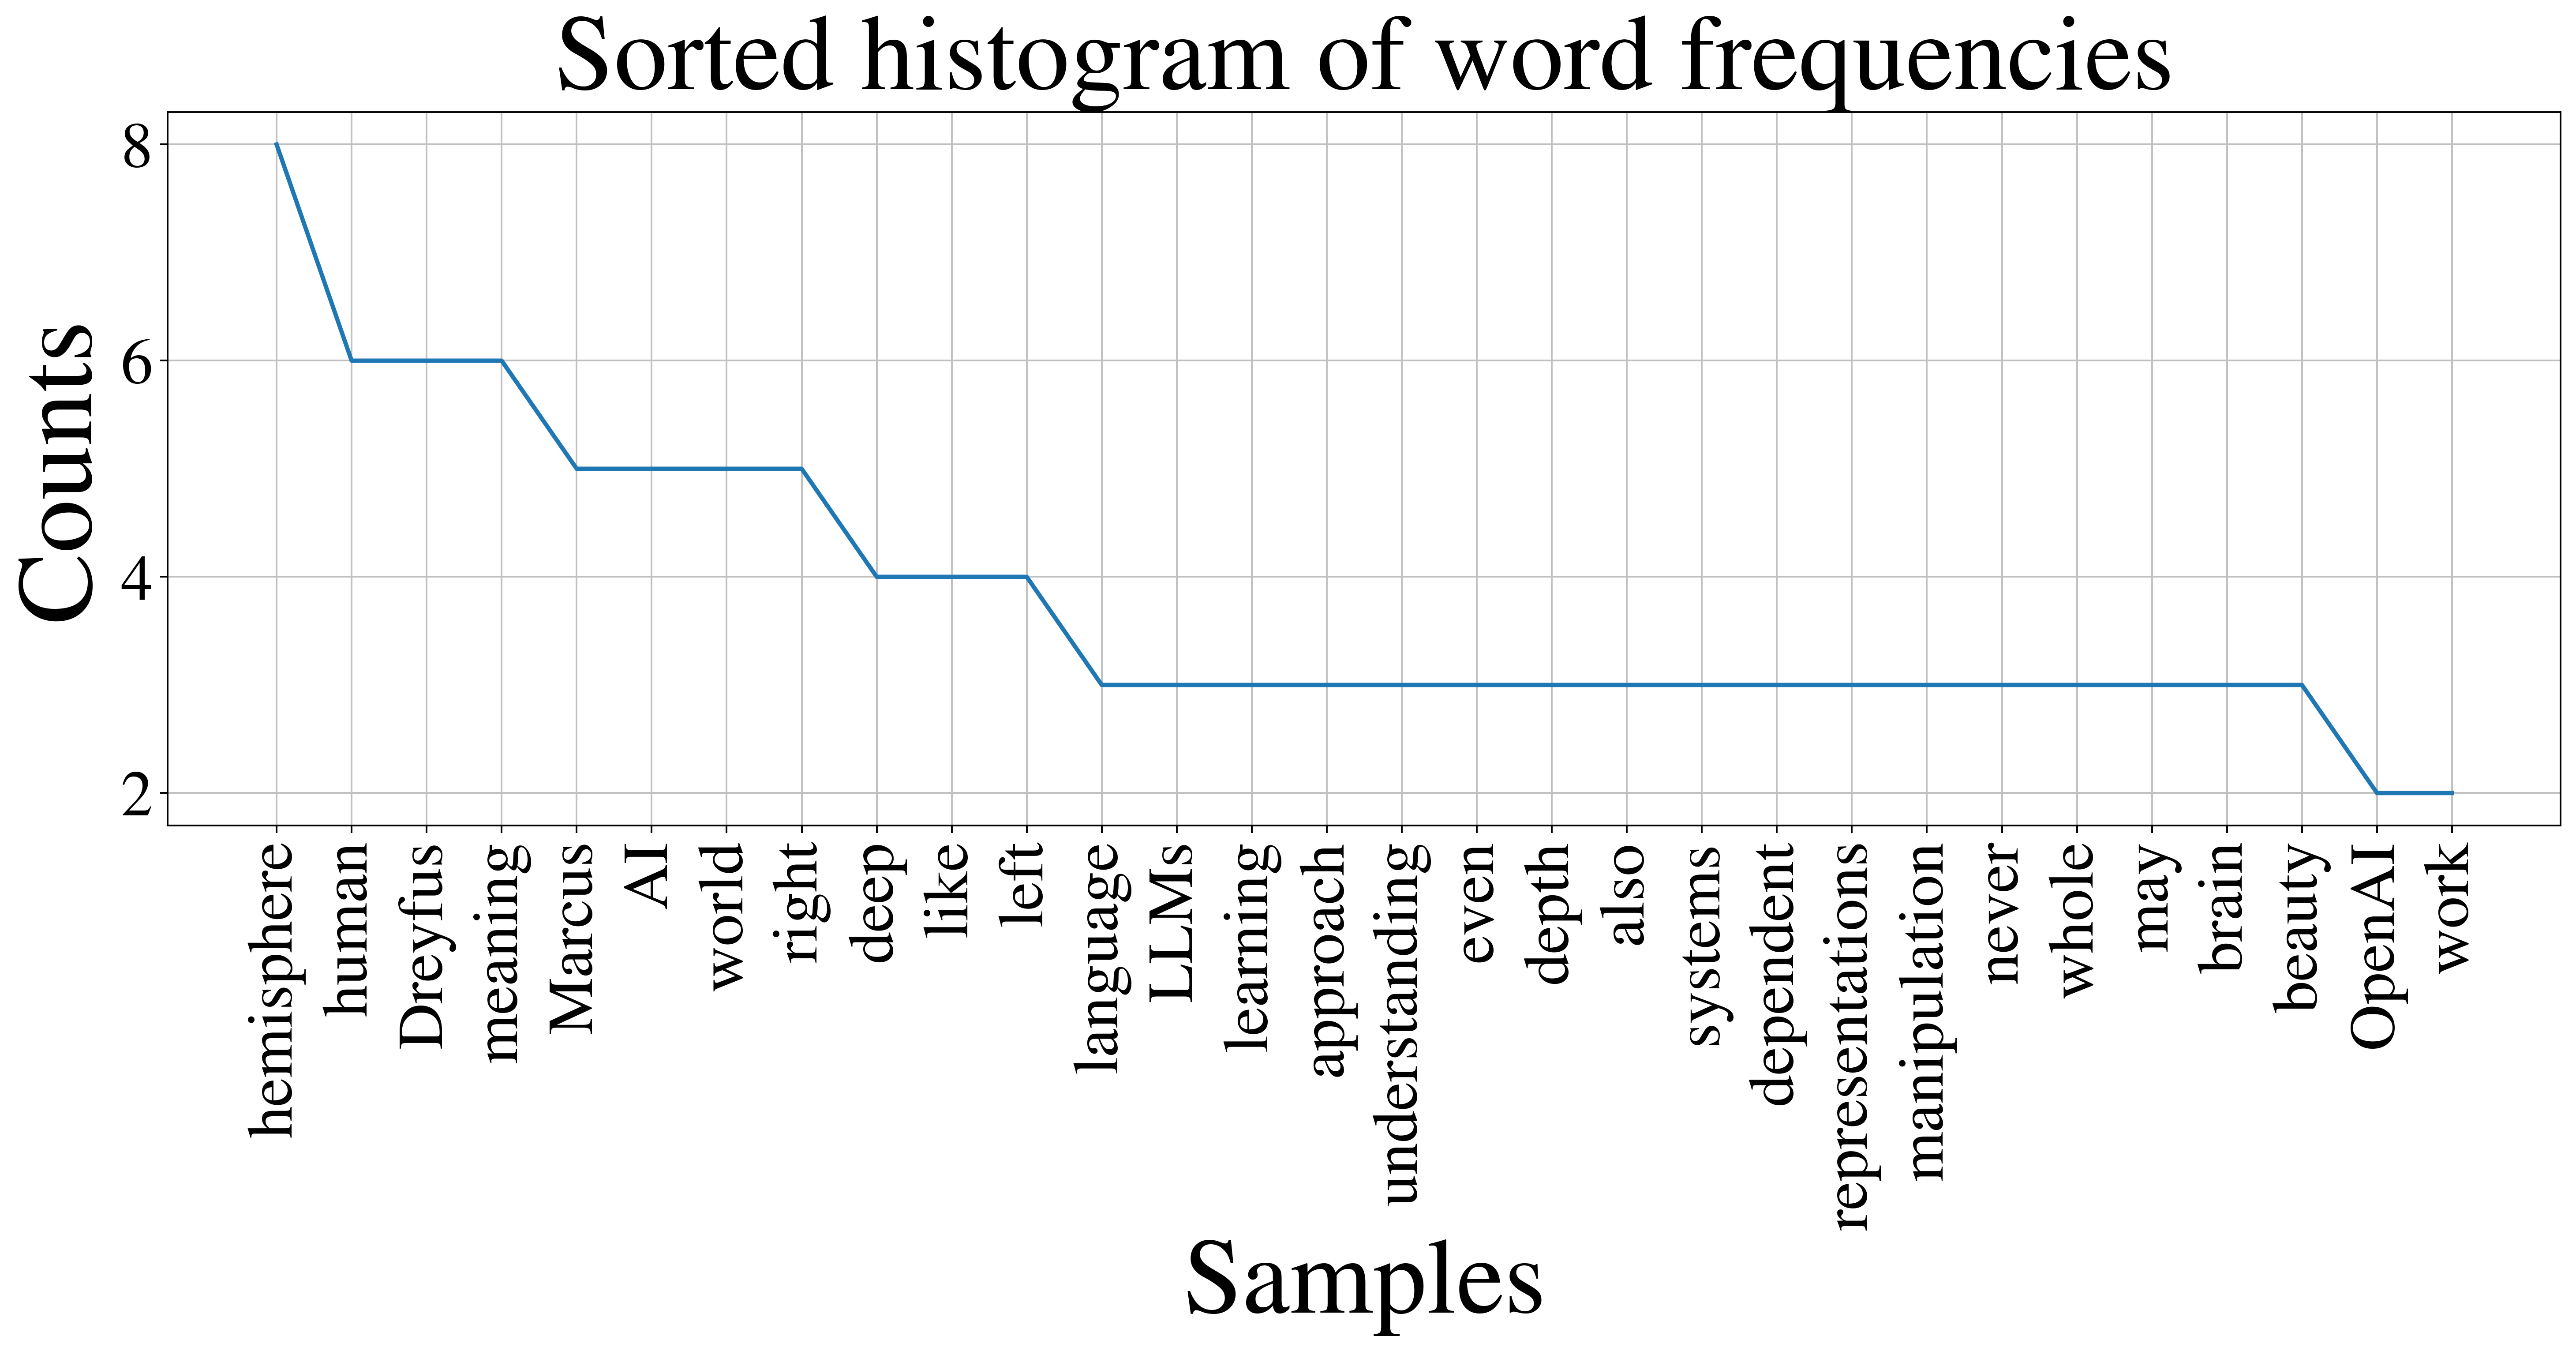

In [39]:
f = plt.figure( figsize=(20, 6))
plt.xlabel('Words', size=50)
plt.ylabel('Counts', size=50)
plt.title('Sorted histogram of word frequencies', size=50)
rcParams['xtick.labelsize'] = 30
rcParams['ytick.labelsize'] = 30
text_article2_stop.plot(30)
ax = f.get_axes()
plt.show()

### Valid Words Only

If we needed to, we could remove all words from a piece of text which are not spelled correctly or are not words by verifying if they occur in an english dictionary:

***The code below will take a few minutes to execute***

In [40]:
valid_words = [word for word in tokenized_article if  word.lower() in nltk.corpus.words.words()]
print(valid_words[:100])

['b', 'in', 'Nick', 's', 'book', 'shaped', 'the', 'debate', 'on', 'AI', 'alignment', 'for', 'the', 'past', 'decade', 'More', 'than', 'any', 'other', 'book', 'on', 'the', 'topic', 'it', 'is', 'responsible', 'for', 'shifting', 'about', 'AI', 'safety', 'from', 'silly', 'to', 'serious', 'And', 'while', 'many', 'prominent', 'still', 'think', 'about', 'the', 'existential', 'risk', 'of', 'AI', 'are', 'these', 'are', 'now', 'legislative', 'attention', 'mainly', 'because', 'key', 'defined', 'by', 'and', 'have', 'been', 'by', 'in', 'is', 'an', 'oracle', 'a', 'question', 'and', 'answer', 'system', 'Custom', 'that', 'can', 'be', 'linked', 'to', 'that', 'meet', 's', 'definition', 'of', 'in', 'that', 'AI', 'can', 'plausibly', 'develop', 'into', 'a', 'also', 'known', 'as', 'the', 'singularity', 'strong', 'AI', 'artificial', 'general', 'intelligence']


We can from this, if we wish, create a vocabulary of the words used in a given text:

In [41]:
valid_words_lower = [ word.lower() for word in valid_words]

In [42]:
valid_words_lower

['b',
 'in',
 'nick',
 's',
 'book',
 'shaped',
 'the',
 'debate',
 'on',
 'ai',
 'alignment',
 'for',
 'the',
 'past',
 'decade',
 'more',
 'than',
 'any',
 'other',
 'book',
 'on',
 'the',
 'topic',
 'it',
 'is',
 'responsible',
 'for',
 'shifting',
 'about',
 'ai',
 'safety',
 'from',
 'silly',
 'to',
 'serious',
 'and',
 'while',
 'many',
 'prominent',
 'still',
 'think',
 'about',
 'the',
 'existential',
 'risk',
 'of',
 'ai',
 'are',
 'these',
 'are',
 'now',
 'legislative',
 'attention',
 'mainly',
 'because',
 'key',
 'defined',
 'by',
 'and',
 'have',
 'been',
 'by',
 'in',
 'is',
 'an',
 'oracle',
 'a',
 'question',
 'and',
 'answer',
 'system',
 'custom',
 'that',
 'can',
 'be',
 'linked',
 'to',
 'that',
 'meet',
 's',
 'definition',
 'of',
 'in',
 'that',
 'ai',
 'can',
 'plausibly',
 'develop',
 'into',
 'a',
 'also',
 'known',
 'as',
 'the',
 'singularity',
 'strong',
 'ai',
 'artificial',
 'general',
 'intelligence',
 'and',
 'artificial',
 'far',
 'more',
 'intelligent

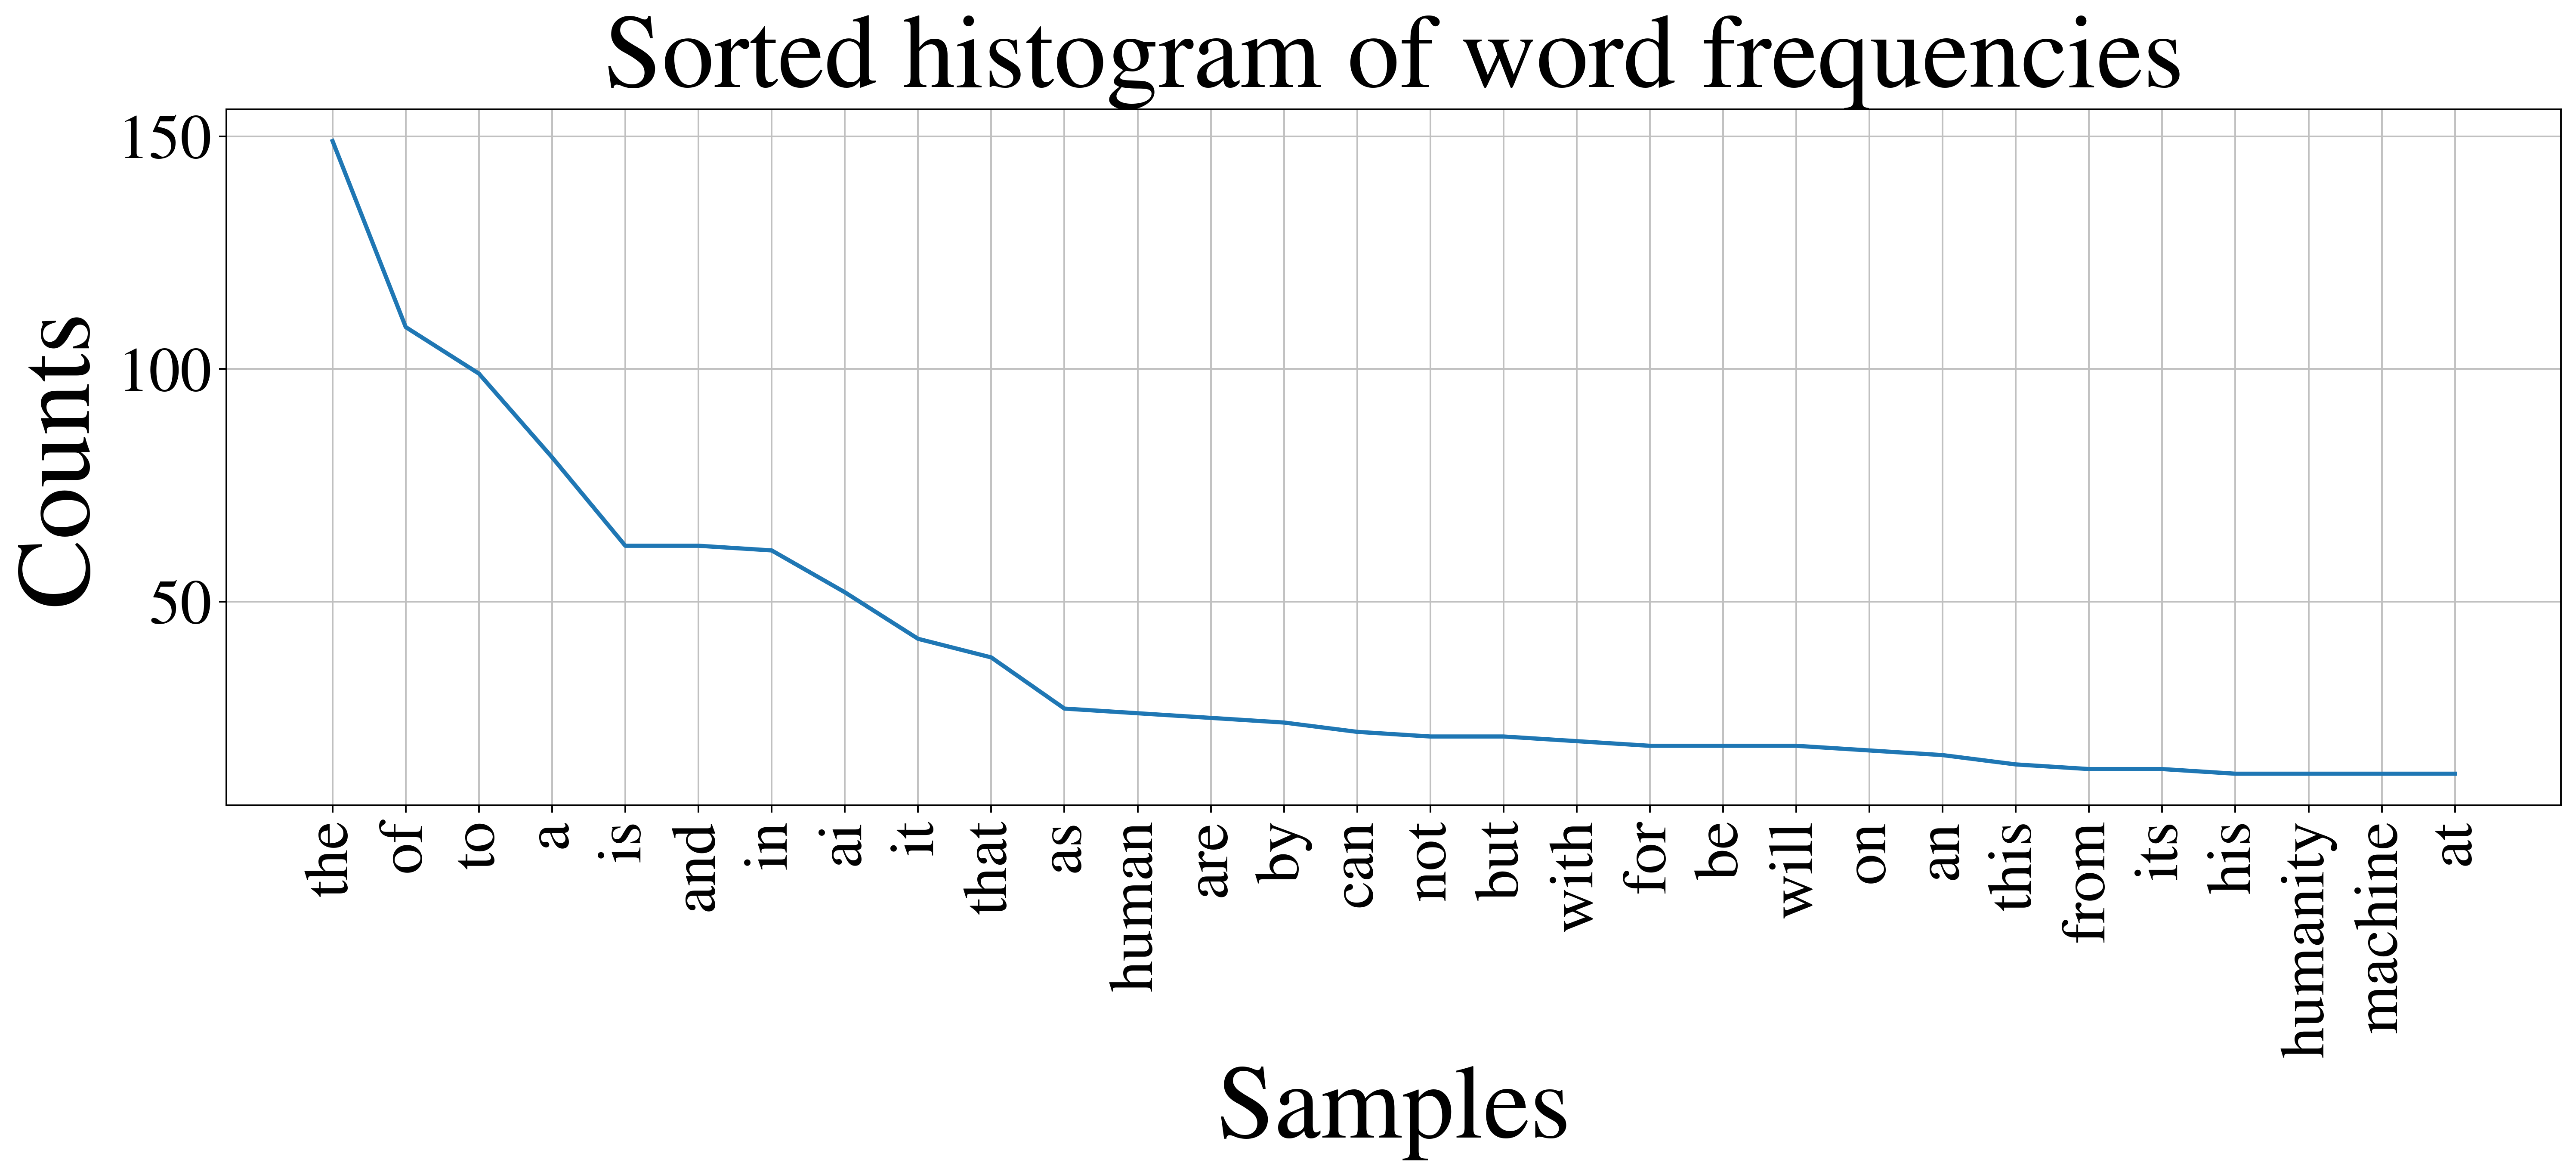

In [43]:
text_article_valid = nltk.Text(valid_words_lower) #need to use a text object, not a list


f = plt.figure( figsize=(20, 6))
plt.xlabel('Words', size=50)
plt.ylabel('Counts', size=50)
plt.title('Sorted histogram of word frequencies', size=50)
rcParams['xtick.labelsize'] = 30
rcParams['ytick.labelsize'] = 30
text_article_valid.plot(30)
ax = f.get_axes()
plt.show()



**Exercise:** Your task now is to remove both all non-English words as well as the stopwords from the article in the previous exercises, and plot the frequency of those words.

### WordClouds

WordClouds are very good at showing visually what the most common words are in the text. However, they are usually not able to preserve the semantic meaning of the words in a visualisation.

There is interesting scientific research being done into semantic-wordclounds which not only encode and convery word frequencies, but also group and visualise commonly ocurring words together. (http://wordcloud.cs.arizona.edu/faq.html)

In [44]:
#!pip install wordcloud

In [45]:
import random 
import wordcloud
#wordcloud = reload(wordcloud)
from wordcloud import WordCloud, STOPWORDS

In [46]:
def grey_color_func(word, font_size, position, orientation, random_state=None, **kwargs):
    return "hsl(0, 0%%, %d%%)" % random.randint(1, 20)

In [47]:
cleaned_article2

"b'Disappointment and a sense of deflation, but no longer denial. Following the release of OpenAI s GPT-5, the internet was soon awash with tweets and posts from industry insiders reluctantly acknowledging the work of Silicon Valley gadfly Gary Marcus. Since the late 2010s, the cognitive scientist has warned of the limits of large language models (LLMs) much to the chagrin of deep learning enthusiasts and figures like OpenAI CEO Sam Altman, who have publicly championed a more heady narrative. Marcus s critique hinges on what he sees as the inherent fragility of deep learning: a data- and energy-hungry, brute-force approach to  understanding  and generating natural language that has proven dazzling yet fundamentally brittle. Those scare quotes are warranted. LLMs do not understand anything not in the way we ordinarily mean the term. Instead, these vast symbol-manipulating machines use enormous computational resources to predict the most statistically likely next word or token, based on 

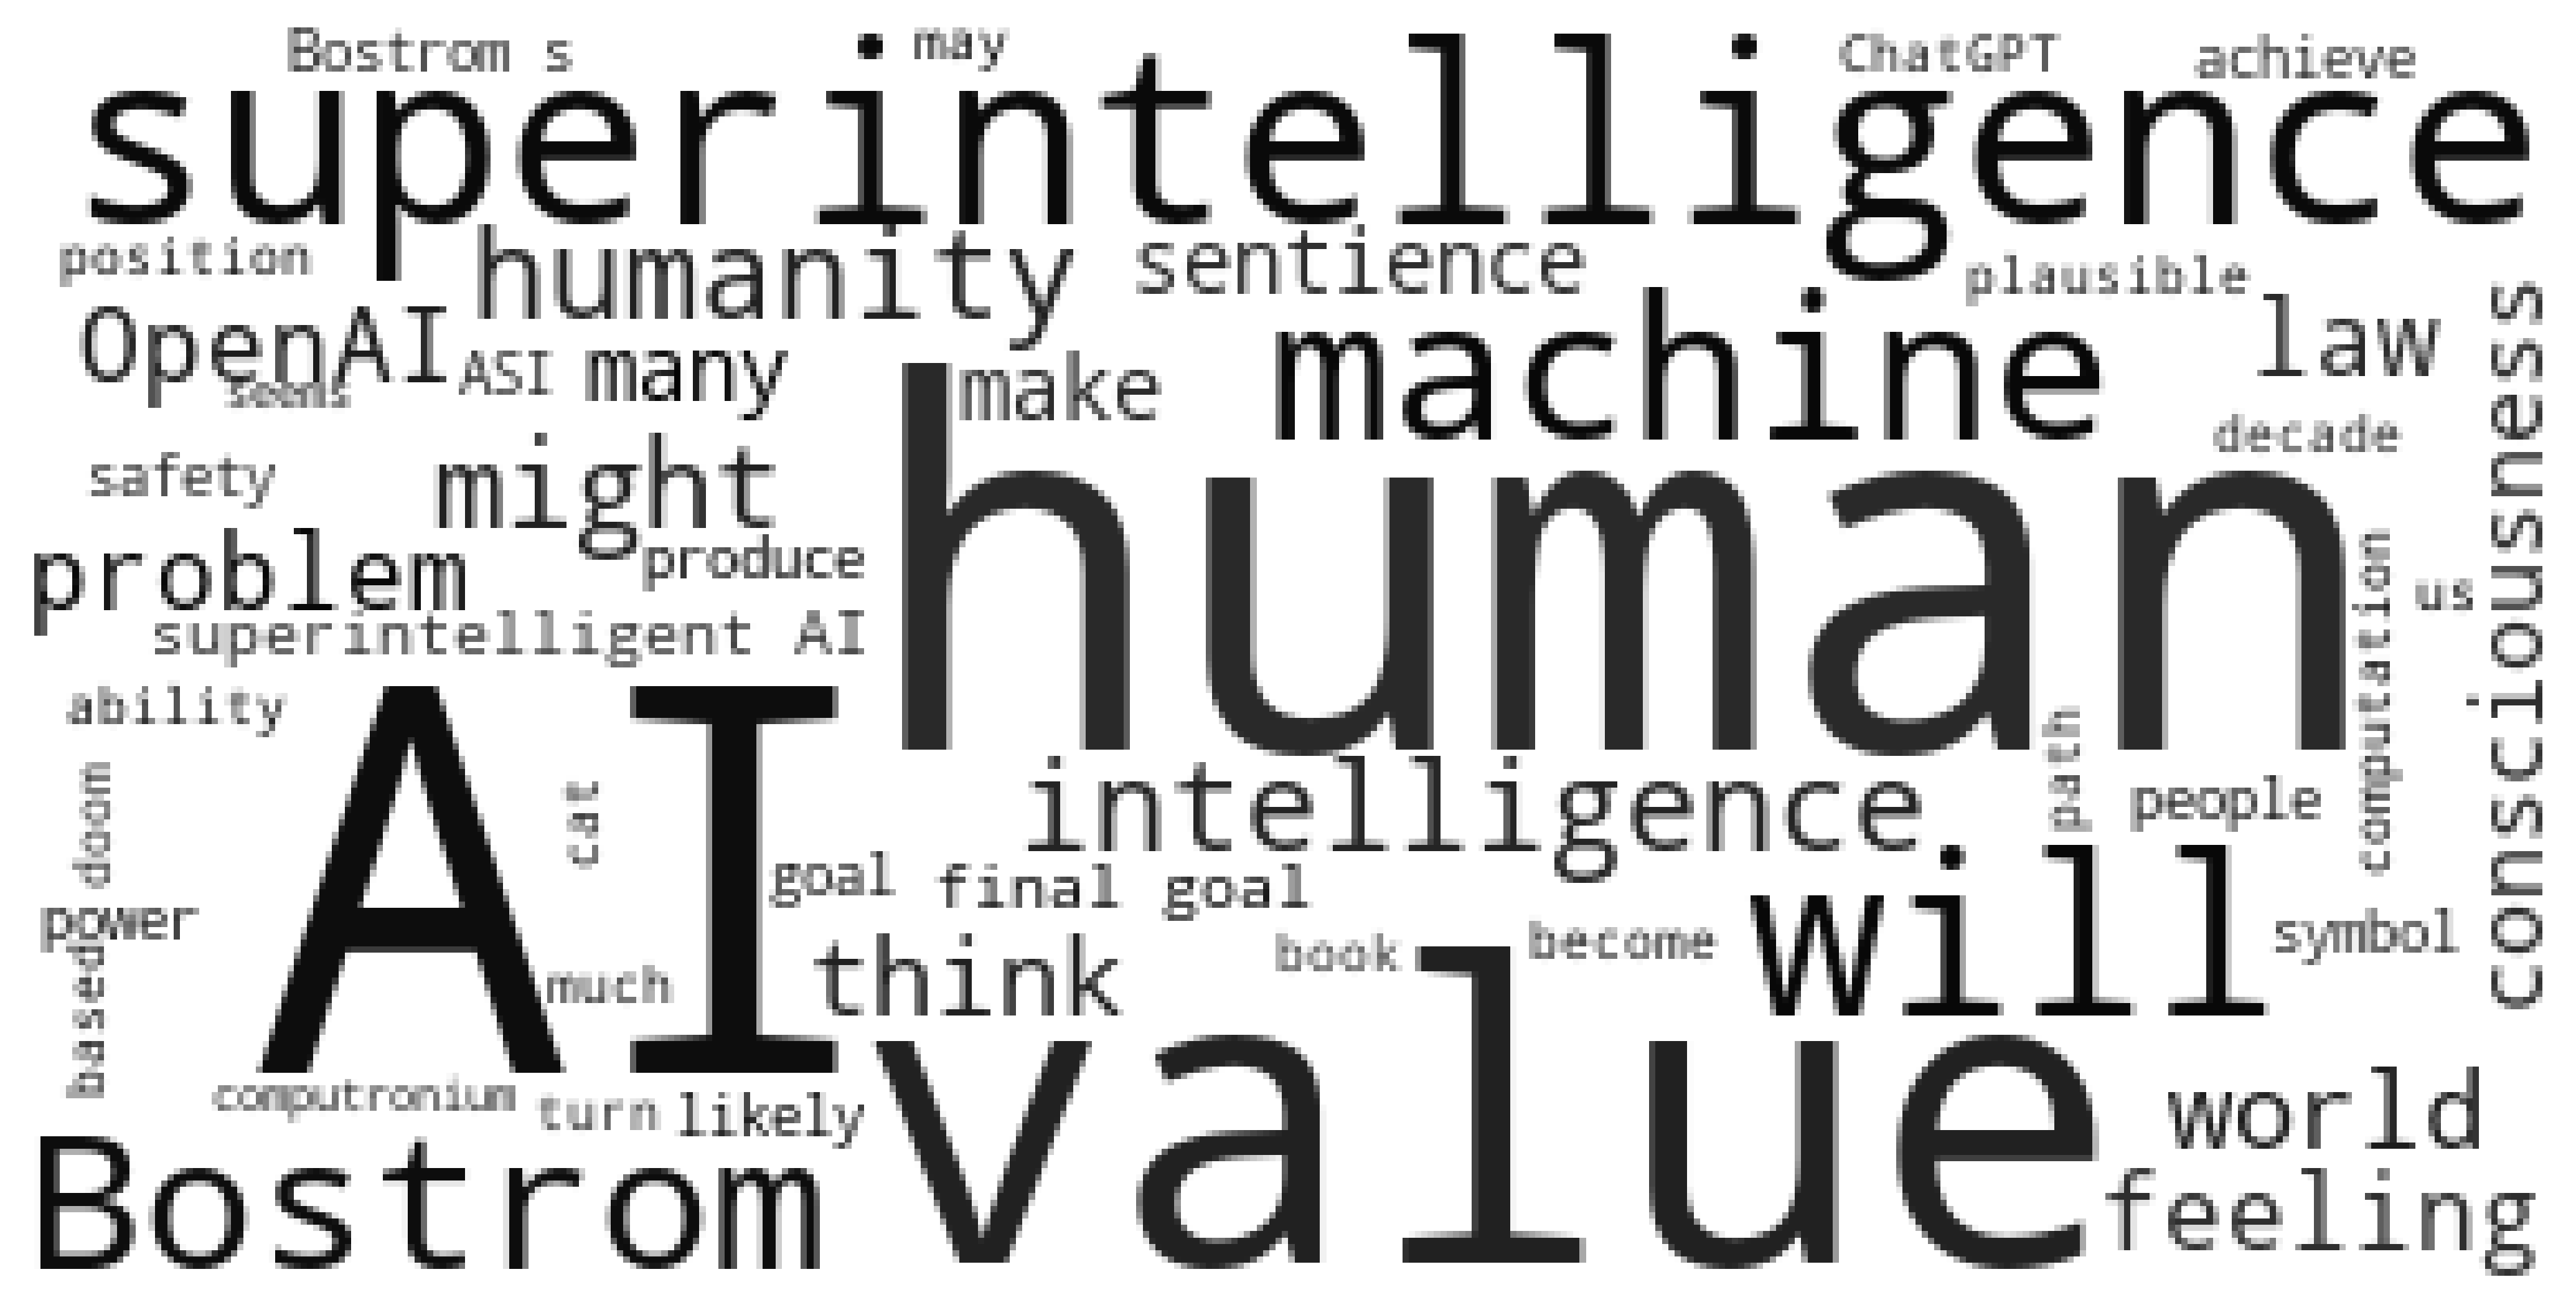

In [48]:
stp = STOPWORDS.copy()
#STOPWORDS.add( "code")
wc = WordCloud(background_color="white", max_words=50,  stopwords=stp)
# generate word cloud
wc.generate(cleaned_article)

# show
plt.figure(figsize=(15,20))
plt.imshow(wc.recolor(color_func=grey_color_func, random_state=3))
plt.axis("off")
plt.show()



**Exercise:** generate a wordcloud for the article in the previous exercises that you have extracted and cleaned.

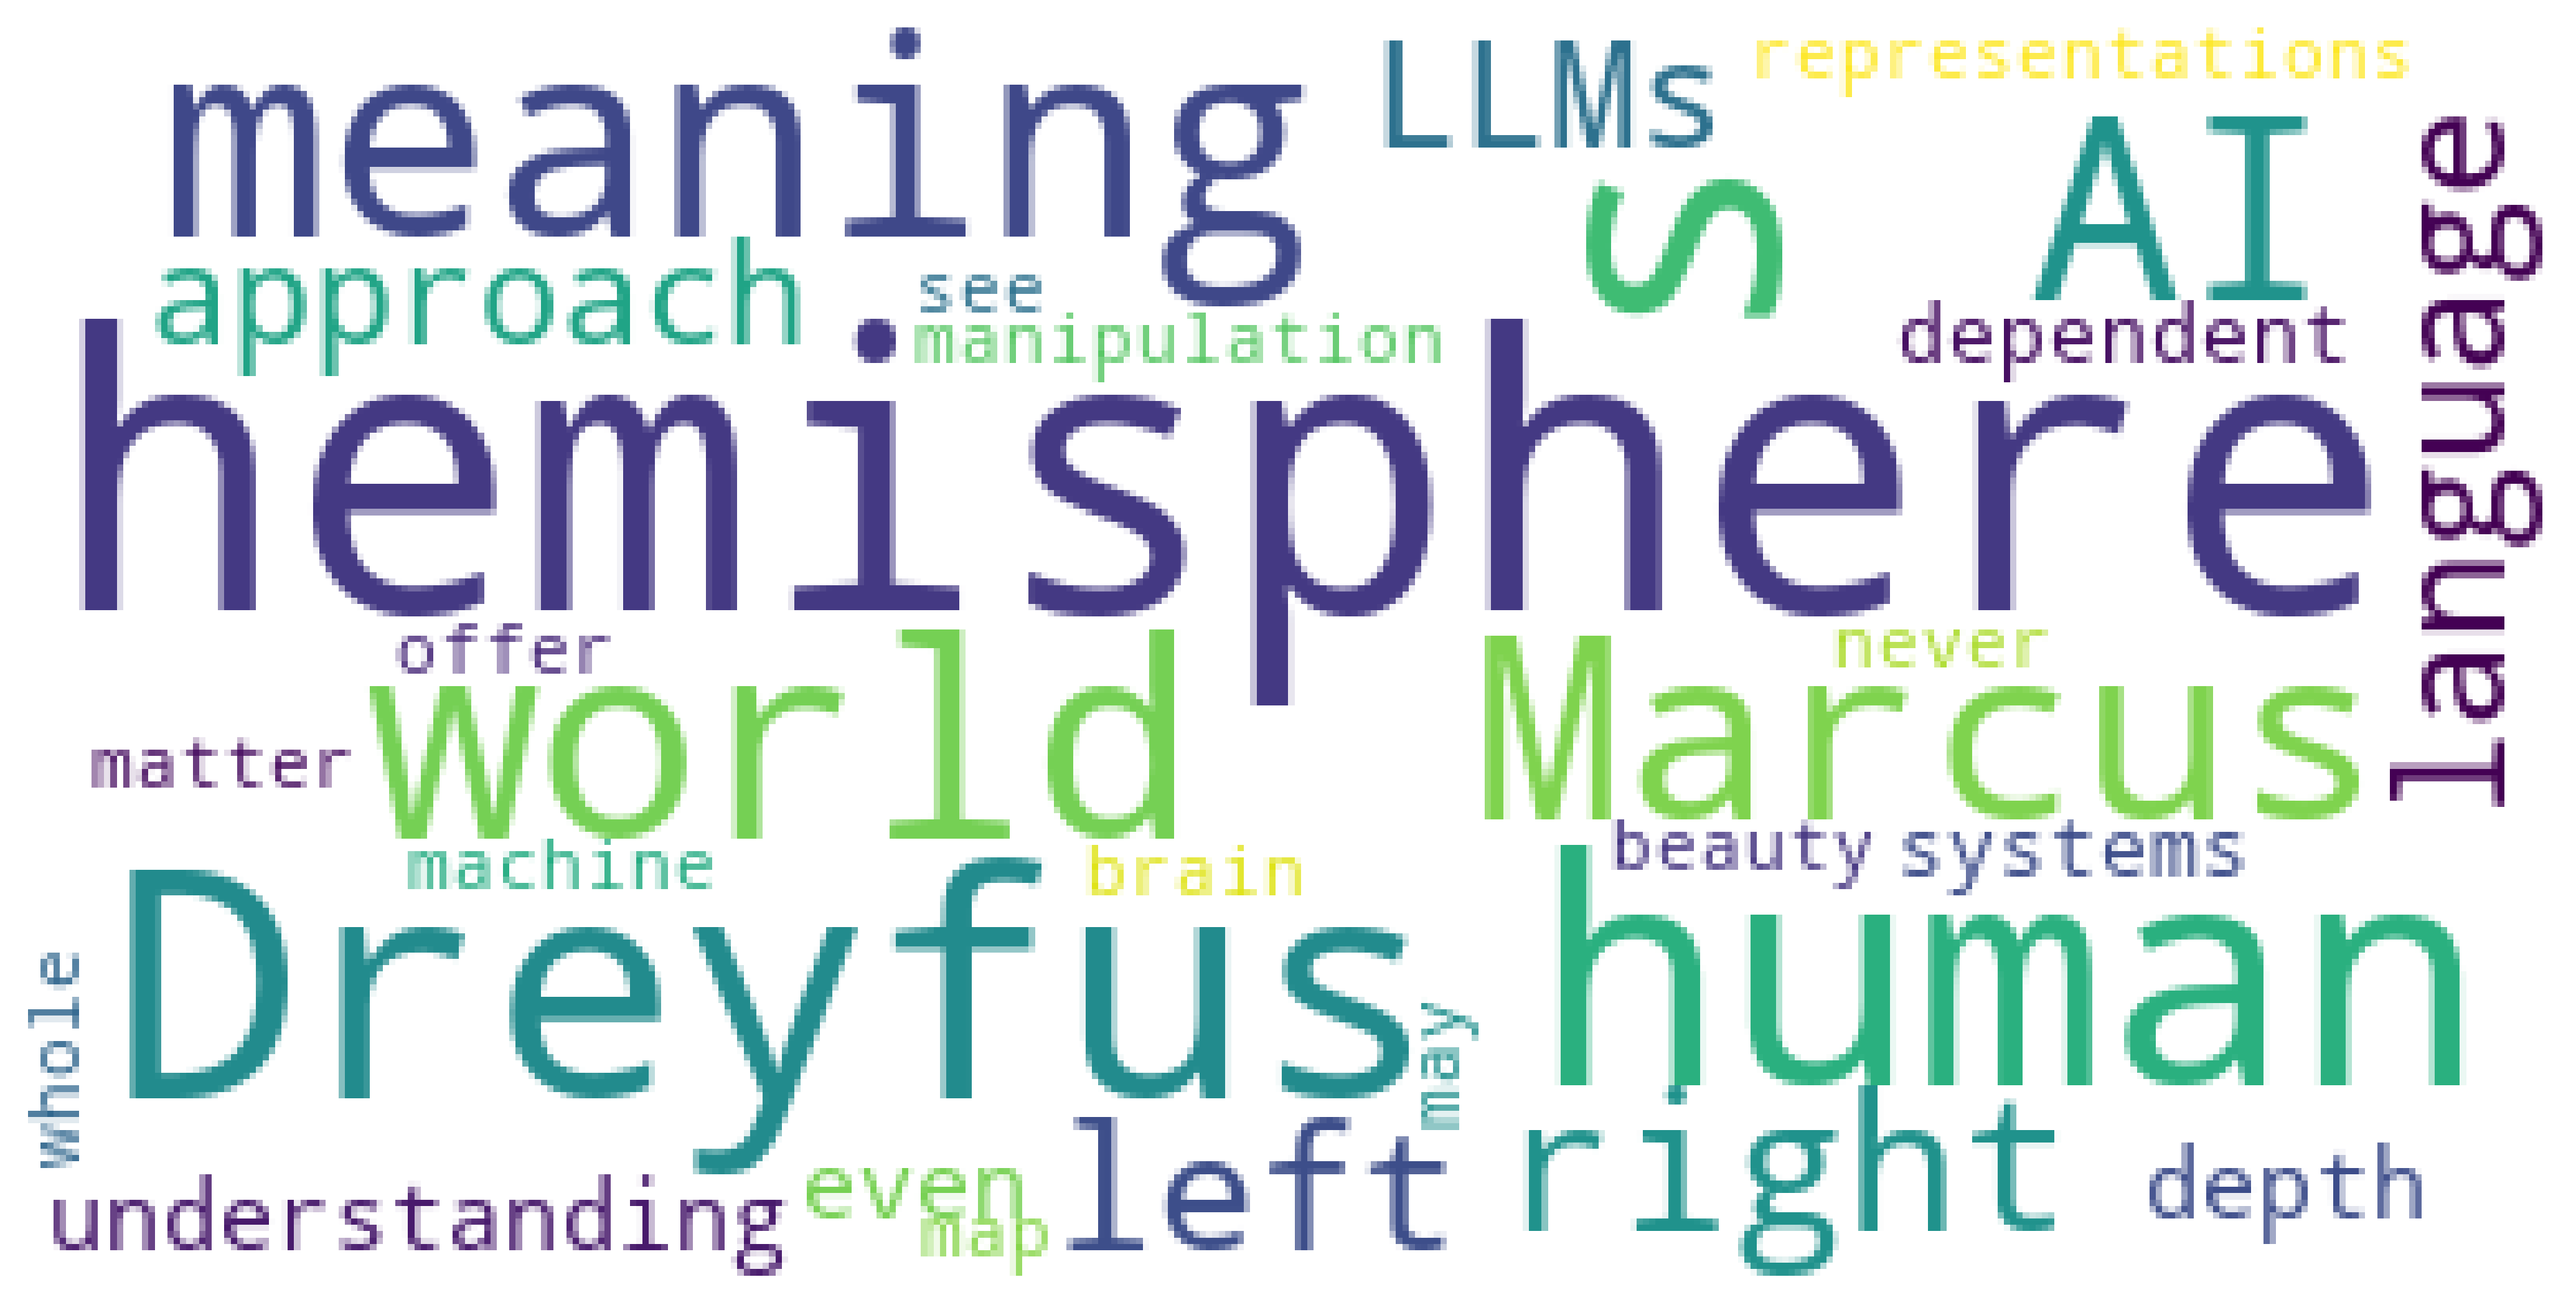

In [49]:
stp = STOPWORDS.copy()
#STOPWORDS.add( "code")
wc = WordCloud(background_color="white", max_words=30,  stopwords=stp)
# generate word cloud
wc.generate(cleaned_article2)

# show
plt.figure(figsize=(15,20))
# plt.imshow(wc.recolor(color_func=grey_color_func, random_state=3))
plt.imshow(wc.recolor(random_state=21))
plt.axis("off")
plt.show()

<div style="background-color: lightblue; padding: 10px;">

    
### Limitations of Traditional Word Clouds and the Advantages of Semantic Word Clouds

**Word clouds** have long been a popular visualisation tool in Natural Language Processing (NLP), often used to represent the frequency of words in a corpus. The size of each word in a traditional word cloud corresponds to its frequency, providing a quick and intuitive way to visualise the most common words in a dataset. However, despite their widespread use, traditional word clouds are severely limited in their ability to capture deeper linguistic and semantic patterns. Below, we explore the key limitations of traditional word clouds and how **semantic word clouds** offer a more sophisticated and meaningful alternative.

#### Limitations of Traditional Word Clouds:

1. **Lack of Contextual Understanding**: 
   - Traditional word clouds simply represent word frequency without accounting for the context in which those words appear. Words with high frequency may not convey much meaning in isolation (e.g., common stopwords), while important context-dependent terms may be overshadowed. For example, the word "bank" in a corpus discussing both financial institutions and riverbanks would appear frequently, but the word cloud would fail to distinguish between the different meanings.
   
2. **No Representation of Semantic Relationships**:
   - Traditional word clouds do not show relationships between words. Words that frequently co-occur or are semantically related (e.g., "car" and "vehicle") are displayed separately and in isolation, even though they may have similar meanings or belong to the same conceptual category. This limits the interpretability of the visualisation and makes it difficult to draw meaningful insights from the data.

3. **Overemphasis on Surface-Level Features**:
   - By focusing solely on raw word counts, traditional word clouds often overemphasise words that are syntactically important but semantically uninformative. Commonly occurring words like "the", "and", or "is" may dominate the visualisation, even if they add little to the overall understanding of the text. Although stopwords can be removed, this solution only partially mitigates the problem, as it does not account for more nuanced or domain-specific patterns.

4. **Inability to Capture Multi-Word Expressions or Phrases**:
   - Traditional word clouds display words individually, ignoring important multi-word expressions or phrases that carry significant meaning (e.g., "machine learning", "New York"). This simplification often leads to an incomplete or misleading representation of the text's key concepts.

#### Advantages of Semantic Word Clouds:

**Semantic word clouds** offer a more advanced and informative visualisation by taking into account both the frequency and the semantic relationships between words or phrases. These improvements address many of the shortcomings of traditional word clouds, making them a far more powerful tool for understanding and interpreting text data.

1. **Context-Aware Representation**:
   - Unlike traditional word clouds, semantic word clouds incorporate contextual information, allowing words to be grouped or organised based on their meaning rather than just their frequency. This is achieved by leveraging vector-based word representations, such as **word embeddings** (e.g., Word2Vec, GloVe) or **contextual embeddings** (e.g., BERT), which capture the semantic similarities between words. As a result, words with similar meanings or those that frequently appear together in similar contexts are placed closer together in the visualisation, providing a more meaningful representation of the text.

2. **Capturing Synonyms and Related Concepts**:
   - Semantic word clouds can group together words with similar meanings (e.g., "car" and "automobile"), even if they do not appear with the same frequency. By capturing the underlying semantic relationships, these clouds offer a richer, more nuanced view of the text and highlight the key concepts that may not be immediately obvious in a traditional word cloud.

3. **Phrase and N-gram Analysis**:
   - In addition to individual words, semantic word clouds can incorporate **multi-word expressions** (e.g., "machine learning", "natural language processing"), which are essential for understanding the key ideas in a text. By including n-grams or phrases, the visualisation provides a more accurate representation of the text's main themes.

4. **Improved Visual Structure**:
   - By grouping related words together and organising the visualisation based on semantic proximity, semantic word clouds present a more coherent and interpretable structure. This allows users to see clusters of related concepts and make connections that would otherwise be hidden in a traditional word cloud.

5. **Enhanced Interpretability**:
   - The combination of frequency and semantic relevance makes semantic word clouds more informative. They not only show the prominence of terms but also reveal how terms relate to each other conceptually. This leads to a deeper understanding of the text's underlying meaning, making semantic word clouds a more effective tool for text analysis, summarisation, and exploration.


While traditional word clouds are easy to generate and offer a quick glimpse into word frequency, they suffer from significant limitations, particularly their lack of contextual understanding and inability to capture semantic relationships between words. **Semantic word clouds**, on the other hand, address these shortcomings by incorporating word embeddings and other techniques that capture the relationships between words based on meaning. This results in a more meaningful and interpretable visualisation, making semantic word clouds a far superior tool for anyone working with large text corpora or seeking to extract deeper insights from unstructured data.
    
Online tool for semantic word clouds: http://wordcloud.cs.arizona.edu/ (btw - this tool somethimes goes offline)


**Exercise:** Go to http://wordcloud.cs.arizona.edu/ and use the tool to generate semantic word cloud rain visualisations for both articles and compare to the normal word clouds for expressiveness.

Read the paper on semantic work clouds here: https://www2.cs.arizona.edu/~kobourov/wordle2.pdf

In [50]:
# !pip install k-means-constrained
# !pip install gensim --user 
# !pip install pythainlp
# !pip install fonttools

In [247]:
# !pip install swordcloud[embedfont]

  Using cached swordcloud-0.0.10-py3-none-any.whl.metadata (9.2 kB)
  Using cached gensim-4.3.3.tar.gz (23.3 MB)
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
  Using cached numpy-1.26.4.tar.gz (15.8 MB)
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): still running...
  Preparing metadata (pyproject.toml): still running...
  Preparing metadata (pyproject.toml): still running...
  Preparing metadata (pyproject.toml): still running...
  Preparing metadata (pyp

  error: subprocess-exited-with-error
  
  Preparing metadata (pyproject.toml) did not run successfully.
  exit code: 1
  
  [44 lines of output]
  + meson setup C:\Users\johnl\AppData\Local\Temp\pip-install-dg3ukhkt\scipy_5205883e287d4a2b97ca5914a012120d C:\Users\johnl\AppData\Local\Temp\pip-install-dg3ukhkt\scipy_5205883e287d4a2b97ca5914a012120d\.mesonpy-p8twpoux -Dbuildtype=release -Db_ndebug=if-release -Db_vscrt=md --native-file=C:\Users\johnl\AppData\Local\Temp\pip-install-dg3ukhkt\scipy_5205883e287d4a2b97ca5914a012120d\.mesonpy-p8twpoux\meson-python-native-file.ini
  The Meson build system
  Version: 1.9.1
  Source dir: C:\Users\johnl\AppData\Local\Temp\pip-install-dg3ukhkt\scipy_5205883e287d4a2b97ca5914a012120d
  Build dir: C:\Users\johnl\AppData\Local\Temp\pip-install-dg3ukhkt\scipy_5205883e287d4a2b97ca5914a012120d\.mesonpy-p8twpoux
  Build type: native build
  Project name: scipy
  Project version: 1.13.1
  C compiler for the host machine: ccache gcc (gcc 13.1.0 "gcc (MinGW-W6

In [248]:
from swordcloud import SemanticWordCloud
from swordcloud.color_func import SingleColorFunc

# Initialize the SemanticWordCloud instance
wordcloud = SemanticWordCloud(
    language='EN',  # Specify language (e.g., 'TH' for Thai, 'EN' for English)
    width=1600,
    height=800,
    max_font_size=150,
    prefer_horizontal=1,
    color_func=SingleColorFunc('black')  # All words will be black
)

# Load raw text (ensure it's UTF-8 encoded)
# raw_text = list(map(str.strip, open('raw_text.txt', encoding='utf-8')))

# Generate the word cloud from raw text
wordcloud.generate_from_text(cleaned_article2, random_state=42)

# Display the word cloud
wordcloud.show()

ModuleNotFoundError: No module named 'swordcloud'

<div style="background-color: lightblue; padding: 10px;">

### Word Rain: A Semantically Enhanced Visualisation Tool

**Word Rain** is a novel and advanced text visualisation technique developed as an evolution of the traditional word cloud. Created through a collaboration between the Centre for Digital Humanities and Social Sciences (CDHU), the National Language Bank of Sweden, and the iVis group, Word Rain introduces semantic awareness to word visualisations, addressing many limitations of traditional word clouds. This tool aims to provide a more sophisticated and interpretable visual representation of text, making it suitable for exploring and comparing corpora in various contexts, such as longitudinal studies and genre-specific analysis.

### How Word Rain Works

Unlike traditional word clouds, which merely display word frequency, **Word Rain** uses **word embeddings** (such as Word2Vec) to incorporate semantic relationships between words. Word embeddings allow the model to represent words as vectors in a high-dimensional space, capturing both their meaning and context. This ensures that related words appear closer together in the visualisation, even if their frequencies differ.

Word Rain is particularly useful for exploring large corpora, which are divided into sub-corpora. This structure enables comparative analysis across multiple datasets, allowing users to visualise how language and themes evolve over time or vary across different contexts. For instance, it has been used to analyse climate change reports and historical periodicals, making it versatile for a wide range of applications.

### How Word Rain Enhances Interpretability

Word Rain significantly improves the **interpretability** of text visualisation through the following features:

- **Contextual Grouping**: By using word embeddings, Word Rain groups words that are semantically similar, enhancing the interpretability of the visualisation. Words that share common meanings or contexts, such as "climate" and "sustainability", are displayed closer to each other. This provides a richer, more meaningful exploration of the text's key themes and concepts, something that traditional word clouds fail to achieve.

- **Comparative Analysis Across Corpora**: One of the key innovations of Word Rain is its ability to handle multiple sub-corpora, making it an effective tool for comparative analysis. This feature allows users to track linguistic trends, patterns, or thematic shifts over time, which is invaluable for tasks like historical analysis or monitoring changes in public discourse on specific topics.

- **Semantic Clustering**: Traditional word clouds are limited to surface-level frequency analysis, but Word Rain goes beyond this by clustering words based on their semantic relationships. This means that, instead of just displaying isolated terms, Word Rain shows how words are connected in meaning, offering deeper insights into the text. For example, synonyms or contextually related terms are visually associated, helping users identify thematic clusters more effectively.

- **Dynamic Representation**: The tool is designed to adapt to the complexity of the text being analysed. As words rain down in the visualisation, the user can visually track the interaction between words, making it easier to interpret relationships within large and diverse corpora.


**Word Rain** offers a significant advancement over traditional word clouds by incorporating semantic awareness into text visualisations. Through the use of word embeddings, it enables more meaningful exploration of text, provides insight into semantic relationships between terms, and allows for the comparative analysis of corpora. Whether used for longitudinal studies, genre analysis, or thematic exploration, Word Rain proves to be a powerful tool for understanding large, complex datasets in a visually intuitive way.

For more details and practical examples, you can install and  explore the Word Rain repository [here](https://github.com/CDHUppsala/word-rain).


**Exercise:** Go to https://wordrain.isof.se/ and use the tool to generate word rain visualisations for both articles and compare to the semantic word clouds for expressiveness.



# Text Normalisation


Text normalization reduce a word to its base or stem form so that text analysis can be more accurate and meaningful by considering words that differ slightly as being same. There are two startegies for this: stemming and lemmatization.

### Stemming

Stemming is the simplest and computationally least expensive strategy which essentially chops off the ending of words in order to arrive at a normalized form.

In [51]:
from nltk.stem import PorterStemmer
porter_stemmer = PorterStemmer()

text = tokenizer.tokenize('women run running runs ran')
[ porter_stemmer.stem(word) for word in text]

['women', 'run', 'run', 'run', 'ran']

In [52]:
from nltk.stem.snowball import SnowballStemmer
snowball_stemmer = SnowballStemmer('english')

In [53]:
# example stemming
print(snowball_stemmer.stem('charge'))
print(snowball_stemmer.stem('charging'))
print(snowball_stemmer.stem('charged'))
print(snowball_stemmer.stem('charges'))

charg
charg
charg
charg


In [54]:
# stem the tokens
clean_tokens = tokenizer.tokenize(cleaned_article) 
stemmed_tokens = [snowball_stemmer.stem(t) for t in clean_tokens]
stemmed_tokens[:30]

['b',
 'publish',
 'in',
 '2014',
 'nick',
 'bostrom',
 's',
 'book',
 'superintellig',
 'path',
 'danger',
 'strategi',
 'has',
 'shape',
 'the',
 'debat',
 'on',
 'ai',
 'align',
 'for',
 'the',
 'past',
 'decad',
 'more',
 'than',
 'ani',
 'other',
 'book',
 'on',
 'the']

### Lemmatization

Lemmatization is much more powerful since it employs a dictionary. Lemmatization employs a broader scope of fuzzy word matching.

In [113]:
lemmatizer = nltk.WordNetLemmatizer()

# compare stemmer to lemmatizer
print(porter_stemmer.stem('dogs'))
print(lemmatizer.lemmatize('dogs'))

print(porter_stemmer.stem('wolves')) # Beter for information retrieval and search
print(lemmatizer.lemmatize('wolves')) # Better for text analysis

# compare stemmer to lemmatizer
print(porter_stemmer.stem('automobiles'))
print(lemmatizer.lemmatize('automobiles'))

dog
dog
wolv
wolf
automobil
automobile


In [114]:
lemmatizer_tokens = [lemmatizer.lemmatize(t) for t in clean_tokens]
lemmatizer_tokens[:35]

['b',
 'Published',
 'in',
 '2014',
 'Nick',
 'Bostrom',
 's',
 'book',
 'Superintelligence',
 'Paths',
 'Dangers',
 'Strategies',
 'ha',
 'shaped',
 'the',
 'debate',
 'on',
 'AI',
 'alignment',
 'for',
 'the',
 'past',
 'decade',
 'More',
 'than',
 'any',
 'other',
 'book',
 'on',
 'the',
 'topic',
 'it',
 'is',
 'responsible',
 'for']

**Exercise:** Lemmatize all the words from the article in the previous exercises that you have extracted and cleaned.

In [138]:
# cleaned_article2_stop
text_cleaned_article2_stop = nltk.Text(tokenized_article2_stop) #need to use a text object, not a list

# cleaned_article2_stop = [word for word in text_cleaned_article2_stop if word.lower() not in stopwords]

# type(cleaned_article2_stop)
# cleaned_article2_stop

text_cleaned_article2_stop
text_string = ' '.join(text_cleaned_article2_stop.tokens)
text_string
clean_tokens2 = tokenizer.tokenize(text_string) 
clean_tokens2 #lemmatize this, with no stop words

['b',
 'Disappointment',
 'sense',
 'deflation',
 'longer',
 'denial',
 'Following',
 'release',
 'OpenAI',
 'GPT',
 '5',
 'internet',
 'soon',
 'awash',
 'tweets',
 'posts',
 'industry',
 'insiders',
 'reluctantly',
 'acknowledging',
 'work',
 'Silicon',
 'Valley',
 'gadfly',
 'Gary',
 'Marcus',
 'Since',
 'late',
 '2010s',
 'cognitive',
 'scientist',
 'warned',
 'limits',
 'large',
 'language',
 'models',
 'LLMs',
 'much',
 'chagrin',
 'deep',
 'learning',
 'enthusiasts',
 'figures',
 'like',
 'OpenAI',
 'CEO',
 'Sam',
 'Altman',
 'publicly',
 'championed',
 'heady',
 'narrative',
 'Marcus',
 'critique',
 'hinges',
 'sees',
 'inherent',
 'fragility',
 'deep',
 'learning',
 'data',
 'energy',
 'hungry',
 'brute',
 'force',
 'approach',
 'understanding',
 'generating',
 'natural',
 'language',
 'proven',
 'dazzling',
 'yet',
 'fundamentally',
 'brittle',
 'scare',
 'quotes',
 'warranted',
 'LLMs',
 'understand',
 'anything',
 'way',
 'ordinarily',
 'mean',
 'term',
 'Instead',
 'vast',

In [ ]:
lemmatizer_tokens2 = [lemmatizer.lemmatize(t) for t in clean_tokens2]
lemmatizer_tokens2[:35]

# Text Semantic Analysis 

~~The usual NLP pipeline involved in semantic analysis of text consists of the following steps depending on the domain and purpose of analysis:~~

1. End of Sentence (EOS) Detection, then
2. Tokenization, then
3. Part-of-Speech (POS) Tagging, then
4. Chunking, then
5. Information Extraction

http://googleresearch.blogspot.co.nz/2016/05/announcing-syntaxnet-worlds-most.html

<div style="background-color: lightblue; padding: 10px;">
    
## Semantic Analysis Redefined post Transformer-based LLMs

With the rapid advancements brought by large language models (LLMs) like GPT and BERT, traditional NLP pipelines—such as the one involving EOS detection, tokenization, POS tagging, chunking, and information extraction—have been significantly redefined. However, these methods still hold relevance, particularly for foundational learning and specific domain-oriented tasks, even though modern LLMs have transformed how text is processed and analysed.

### Relevance in Modern NLP:

1. **Conceptual Foundation:**
    - While LLMs have automated and largely subsumed many traditional tasks, understanding the classical NLP pipeline remains important for grasping the evolution of the field. Concepts such as tokenization and POS tagging are fundamental, as they help students understand how language is broken down and processed at a granular level.
    - LLMs, despite their advanced capabilities, still rely on underlying tokenization mechanisms (e.g., subword tokenization, byte-pair encoding) to process text, making it valuable to understand these concepts in context.

2. **Fine-Tuning and Domain-Specific Applications:**
    - Traditional NLP tasks like chunking, named entity recognition (NER), and information extraction are still used when fine-tuning LLMs for specialised domains (e.g., legal, medical, or financial texts). These domain-specific tasks often benefit from explicit linguistic rules and structure, combined with the flexibility of LLMs.
    - Industries where high precision and interpretability are required may still integrate rule-based approaches alongside LLMs, as traditional methods can offer transparency and domain-specific control.

3. **Efficiency and Simplicity:**
    - For applications where deploying a full-scale LLM is impractical or unnecessary, traditional NLP methods offer computational efficiency and simplicity. In real-time processing scenarios or resource-constrained environments, simpler models based on the classical pipeline may still be favoured.
    - The explicit steps of tokenization, POS tagging, and chunking may be more computationally lightweight than end-to-end LLMs, especially when working with smaller datasets or well-defined tasks like sentiment analysis or keyword extraction.

### How the NLP Pipeline Has Shifted with LLMs:

- **End-to-End Learning:**
    - Modern LLMs perform many of these tasks (e.g., POS tagging, chunking, information extraction) implicitly, making explicit manual steps largely redundant in certain contexts. For example, information extraction, once dependent on chunking and hand-crafted rules, is now effectively handled by fine-tuned LLMs that leverage transfer learning and deep contextual embeddings.

- **Integrated Semantic Understanding:**
    - LLMs have transformed semantic analysis by encapsulating multiple layers of linguistic understanding within their learned representations. As a result, tasks like POS tagging and chunking, which were once necessary for downstream tasks, are now internalised within the model's architecture. This allows LLMs to perform complex tasks like summarisation, text generation, and question answering without relying on step-by-step pipelines.


We have seen what tokenization and normalization are and how they are used at the most basic level of text processing. In order to make meaning of text though, words must be organised into sentences and then words in sentences must be identified according to their types.

The (EOS) Detection part looks at a text and first attempts to segment it based on sentences. It looks for beginning and the end of each sentence in order to give text structure.

In [55]:
text = 'Dr. Sheldon Cooper can be very abraisive to others with what he says. Dr. Sheldon Cooper is sometimes not much liked, but is very amusing.'
sentences = nltk.tokenize.sent_tokenize(text)
sentences

['Dr. Sheldon Cooper can be very abraisive to others with what he says.',
 'Dr. Sheldon Cooper is sometimes not much liked, but is very amusing.']

Following the EOS segmentation, the individual sentences are then tokenized as we have seen before.

In [56]:
tokens = [tokenizer.tokenize(sentence) for sentence in sentences] 
tokens

[['Dr',
  'Sheldon',
  'Cooper',
  'can',
  'be',
  'very',
  'abraisive',
  'to',
  'others',
  'with',
  'what',
  'he',
  'says'],
 ['Dr',
  'Sheldon',
  'Cooper',
  'is',
  'sometimes',
  'not',
  'much',
  'liked',
  'but',
  'is',
  'very',
  'amusing']]

POS tagging is very important for semantic analysis. 

Each word/token is decorated with a part of the speech or linguistic construct it belongs to. 

This can later be used for deriving meaning from a text and for example, for applying machine learning. 

In [57]:
pos_tagged_tokens = [nltk.pos_tag(token) for token in tokens] 
pos_tagged_tokens

[[('Dr', 'NNP'),
  ('Sheldon', 'NNP'),
  ('Cooper', 'NNP'),
  ('can', 'MD'),
  ('be', 'VB'),
  ('very', 'RB'),
  ('abraisive', 'JJ'),
  ('to', 'TO'),
  ('others', 'NNS'),
  ('with', 'IN'),
  ('what', 'WP'),
  ('he', 'PRP'),
  ('says', 'VBZ')],
 [('Dr', 'NNP'),
  ('Sheldon', 'NNP'),
  ('Cooper', 'NNP'),
  ('is', 'VBZ'),
  ('sometimes', 'RB'),
  ('not', 'RB'),
  ('much', 'JJ'),
  ('liked', 'VBN'),
  ('but', 'CC'),
  ('is', 'VBZ'),
  ('very', 'RB'),
  ('amusing', 'JJ')]]

Chunk extraction is a useful step towards achieving information extraction. It generates a parse tree from unstructured text. Given a parse tree of a sentence,  more specific information extraction like named entity recognition and relation extraction can be accomplished as a final step.

In [58]:
pos_tagged_chunks = [nltk.ne_chunk(chunk) for chunk in pos_tagged_tokens] 
pos_tagged_chunks

[Tree('S', [('Dr', 'NNP'), ('Sheldon', 'NNP'), ('Cooper', 'NNP'), ('can', 'MD'), ('be', 'VB'), ('very', 'RB'), ('abraisive', 'JJ'), ('to', 'TO'), ('others', 'NNS'), ('with', 'IN'), ('what', 'WP'), ('he', 'PRP'), ('says', 'VBZ')]),
 Tree('S', [('Dr', 'NNP'), ('Sheldon', 'NNP'), ('Cooper', 'NNP'), ('is', 'VBZ'), ('sometimes', 'RB'), ('not', 'RB'), ('much', 'JJ'), ('liked', 'VBN'), ('but', 'CC'), ('is', 'VBZ'), ('very', 'RB'), ('amusing', 'JJ')])]

The chunks can  be visually portrayed:

In [59]:
pos_tagged_chunks[0].pprint()

(S
  Dr/NNP
  Sheldon/NNP
  Cooper/NNP
  can/MD
  be/VB
  very/RB
  abraisive/JJ
  to/TO
  others/NNS
  with/IN
  what/WP
  he/PRP
  says/VBZ)


In [ ]:
#takes a long time
pos_tagged_chunks[0].draw()

Information Extraction involves analyzing each chunk and associating it with an additional tag. Information Extraction standardly consists of three subtasks: Named Entity Recognition, Relation Extraction and Template Filling.


# Text Sentiment Analysis 

<div style="background-color: lightblue; padding: 10px;">

    
### Traditional Sentiment Analysis vs. LLMs: The Evolution of Sentiment Classification

The field of **sentiment analysis** has evolved significantly over the past decade. Traditional methods, which relied on classical machine learning algorithms and feature engineering, have been largely replaced by more powerful techniques driven by **LLMs**. However, traditional sentiment analysis classifiers still hold relevance in certain contexts, particularly where computational efficiency and interpretability are crucial. Below, we explore the shift from traditional methods to LLM-based sentiment analysis, and the factors influencing the choice between these approaches.

#### Traditional Sentiment Analysis Classifiers:

Traditional sentiment analysis typically involves:

- **Preprocessing the text**: Tokenizing, removing stopwords, and normalising text (e.g., stemming or lemmatization).
- **Feature extraction**: Using methods like **TF-IDF**, **bag-of-words**, or **n-grams** to represent the text numerically.
- **Classifiers**: Applying classical algorithms such as **Naive Bayes**, **Support Vector Machines (SVMs)**, or **Logistic Regression** to classify sentiment (e.g., positive, negative, or neutral).

These approaches were effective for tasks where the textual data was relatively simple or when domain-specific feature engineering could capture sentiment patterns. Additionally, traditional models often perform well on smaller datasets and offer **interpretability**, allowing users to understand which features (words or phrases) contributed most to the sentiment classification.

However, traditional methods have limitations:

- **Lack of context awareness**: Sentiment often depends on subtle context, sarcasm, or complex sentence structure. Traditional classifiers struggle with this as they rely heavily on surface-level features and word frequencies, often missing the deeper semantic meaning.
- **Labor-intensive feature engineering**: Significant effort is required to manually engineer features and preprocess the data in ways that capture sentiment effectively.
  
#### LLMs for Sentiment Analysis:

The rise of **transformer-based models**, such as **BERT**, **GPT**, and **RoBERTa**, has transformed how sentiment analysis is performed. These **LLMs** use attention mechanisms to understand context, semantics, and syntactic structure more deeply than traditional classifiers ever could. With fine-tuning on specific tasks, LLMs offer several advantages:

- **Contextual Understanding**: LLMs can capture complex dependencies between words, understanding sentiment in nuanced contexts where traditional classifiers would fail. For example, in sentences with sarcasm or ambiguous language, LLMs excel by considering the broader context of the sentence rather than relying on isolated word frequencies.
  
- **Out-of-the-Box Performance**: Pre-trained LLMs like BERT and GPT can achieve state-of-the-art performance on sentiment analysis tasks with minimal feature engineering. Fine-tuning these models on sentiment data results in highly accurate classifiers without the need for intensive data preprocessing.

- **Scalability**: LLMs can handle large-scale sentiment analysis tasks with ease, and their pre-training on vast amounts of text makes them suitable for sentiment classification across various domains without needing domain-specific feature engineering.

#### Choosing Between Traditional Methods and LLMs:

- **Efficiency and Simplicity**: Traditional classifiers may still be useful in cases where computational resources are limited, or when simpler models suffice. For smaller datasets or applications requiring real-time sentiment analysis on edge devices, traditional methods can offer faster performance with lower overhead.

- **Interpretability**: LLMs, despite their superior performance, are often considered "black boxes" with limited interpretability. In contrast, traditional classifiers provide clear insight into which features influenced the sentiment decision, making them more desirable in certain regulatory or business contexts where understanding model behaviour is crucial.

- **Domain-Specific Adaptation**: While LLMs generalise well across domains, traditional classifiers—when paired with robust feature engineering—may still perform competitively in narrowly defined, domain-specific tasks. This is particularly true when rich annotated datasets are unavailable for fine-tuning LLMs.

#### The Current Trend:

In practice, **LLMs are becoming the dominant approach** for sentiment analysis due to their superior performance, especially in more complex or large-scale tasks. With LLMs, there is little need for extensive feature engineering, and they generalise well across various tasks and domains. **Traditional sentiment analysis classifiers**, while still used in some resource-constrained environments or for more interpretable results, are increasingly giving way to these more sophisticated models. While traditional sentiment analysis techniques remain relevant in certain scenarios, the shift towards **LLMs** reflects the broader trend in NLP towards models that capture deeper context and semantics, leading to more accurate and nuanced sentiment classification.



### TextBlob - Simplified NLP


> TextBlob is a Python (2 and 3) library for processing textual data. It provides a simple API for diving into common natural language processing (NLP) tasks such as part-of-speech tagging, noun phrase extraction, sentiment analysis, classification, translation, and more.

TextBlob stands on the giant shoulders of NLTK and pattern, and plays nicely with both.

Features:

    Noun phrase extraction
    Part-of-speech tagging
    Sentiment analysis
    Classification (Naive Bayes, Decision Tree)
    Language translation and detection powered by Google Translate
    Tokenization (splitting text into words and sentences)
    Word and phrase frequencies
    Parsing
    n-grams
    Word inflection (pluralization and singularization) and lemmatization
    Spelling correction
    Add new models or languages through extensions
    WordNet integration


Source: https://textblob.readthedocs.org/en/dev/

In [140]:
# !pip install TextBlob

In [60]:
from textblob import TextBlob, Word

# identify words
blob = TextBlob('Tom and Jerry are Computer Science students at Massey University in Auckland')
blob.words#a function that we can call on Word


WordList(['Tom', 'and', 'Jerry', 'are', 'Computer', 'Science', 'students', 'at', 'Massey', 'University', 'in', 'Auckland'])

In [61]:
# identify noun phrases
blob.noun_phrases

WordList(['tom', 'jerry', 'computer', 'science students', 'massey', 'auckland'])

In [62]:
# singularize and pluralize - not perfect
blob = TextBlob('I see many trees')
print([word.singularize() for word in blob.words])
print([word.pluralize() for word in blob.words])


['I', 'see', 'many', 'tree']
['we', 'sees', 'manies', 'treess']


## Sentiment Analysis with TextBlob

The textblob.sentiments module contains two sentiment analysis implementations, PatternAnalyzer (based on the pattern library) and NaiveBayesAnalyzer (an NLTK classifier trained on a movie reviews corpus).

The default implementation is PatternAnalyzer, but you can override the analyzer by passing another implementation into a TextBlob’s constructor.

In [63]:
from textblob.sentiments import NaiveBayesAnalyzer, PatternAnalyzer
from textblob import Blobber
tba = Blobber(analyzer=NaiveBayesAnalyzer())

 For instance, the NaiveBayesAnalyzer returns its result as a namedtuple of the form: Sentiment(classification, p_pos, p_neg).

In [64]:
tba("I love natural language processing. It is very difficult though but I still enjoy it.").sentiment

Sentiment(classification='pos', p_pos=0.9090178756547229, p_neg=0.09098212434527589)

In [65]:
tba("I love natural language processing. It is very difficult though but I still enjoy it.").polarity

0.0875

In [66]:
# sentiment analysis
blob = TextBlob('I love natural language processing. It is very difficult though but I still enjoy it.', analyzer=PatternAnalyzer())
blob.sentences 


[Sentence("I love natural language processing."),
 Sentence("It is very difficult though but I still enjoy it.")]

In [67]:
#Polarity ranges from -1 to 1 (1 = positive sentiment). 
#Subjectivity how much opinion is expressed within a given sentence: 0 = objective 1 = subjective
blob.sentiment


Sentiment(polarity=0.0875, subjectivity=0.625)

The sentiment property returns a namedtuple of the form Sentiment(polarity, subjectivity). The polarity score is a float within the range [-1.0, 1.0]. The subjectivity is a float within the range [0.0, 1.0] where 0.0 is very objective and 1.0 is very subjective.

In [68]:
blob.sentiment.polarity


0.0875

In [69]:
[sent.sentiment.polarity for sent in blob.sentences]


[0.3, -0.125]

In [70]:
# sentiment subjectivity
print(TextBlob("I am a really good programmer").sentiment.subjectivity) #  subjective
TextBlob("I am a programmer").sentiment.subjectivity #  objective


0.6000000000000001


0.0

**Exercise:** Extract each sentence from the article in the previous exercises that you have downloaded and list each sentence with its sentiment.

In [72]:
nb_blob = tba(cleaned_article2)
nb_blob.sentiment
nb_blob.polarity

[(sent.sentiment, sent.polarity) for sent in nb_blob.sentences]


[(Sentiment(classification='pos', p_pos=0.9078173935775283, p_neg=0.09218260642247142),
  -0.6),
 (Sentiment(classification='pos', p_pos=0.9968877923348864, p_neg=0.0031122076651161493),
  0.0),
 (Sentiment(classification='pos', p_pos=0.9802779815553521, p_neg=0.0197220184446508),
  0.10238095238095239),
 (Sentiment(classification='pos', p_pos=0.9998137842805369, p_neg=0.0001862157194569519),
  0.2833333333333333),
 (Sentiment(classification='neg', p_pos=0.04414849792615739, p_neg=0.9558515020738435),
  0.0),
 (Sentiment(classification='pos', p_pos=0.5360859514100833, p_neg=0.4639140485899164),
  -0.3125),
 (Sentiment(classification='pos', p_pos=0.9717641803103021, p_neg=0.028235819689693215),
  0.08333333333333333),
 (Sentiment(classification='neg', p_pos=0.21189464098837293, p_neg=0.7881053590116288),
  0.1375),
 (Sentiment(classification='pos', p_pos=0.9995254169978766, p_neg=0.0004745830021204696),
  -0.09999999999999999),
 (Sentiment(classification='pos', p_pos=0.9978942518669709,

In [73]:
#not doing with naive bayes due to processing speed,
blob = TextBlob(cleaned_article2, analyzer=PatternAnalyzer())
# blob.sentences 
blob.sentiment
blob.sentiment.polarity

[sent.sentiment for sent in blob.sentences]


[Sentiment(polarity=-0.6, subjectivity=0.4),
 Sentiment(polarity=0.0, subjectivity=0.1),
 Sentiment(polarity=0.10238095238095239, subjectivity=0.3658730158730159),
 Sentiment(polarity=0.2833333333333333, subjectivity=0.6),
 Sentiment(polarity=0.0, subjectivity=0.0),
 Sentiment(polarity=-0.3125, subjectivity=0.6875),
 Sentiment(polarity=0.08333333333333333, subjectivity=0.5833333333333334),
 Sentiment(polarity=0.1375, subjectivity=0.75),
 Sentiment(polarity=-0.09999999999999999, subjectivity=0.3),
 Sentiment(polarity=0.22499999999999998, subjectivity=0.30000000000000004),
 Sentiment(polarity=0.2, subjectivity=0.55),
 Sentiment(polarity=0.4, subjectivity=0.5),
 Sentiment(polarity=0.0, subjectivity=0.0),
 Sentiment(polarity=0.3333333333333333, subjectivity=0.41666666666666663),
 Sentiment(polarity=0.06666666666666667, subjectivity=0.4000000000000001),
 Sentiment(polarity=0.05500000000000001, subjectivity=0.4466666666666666),
 Sentiment(polarity=0.0, subjectivity=0.0),
 Sentiment(polarity=

We can train our own sentiment classifiers using TextBlob.

In [74]:
from textblob import TextBlob
from textblob.classifiers import NaiveBayesClassifier
train = [
     ('I love this course.', 'pos'),
    ('I love hats.', 'pos'),
    ('I love icecream.', 'pos'),
     ('This univeristy is an amazing place!', 'pos'),
     ('I feel very good about these assignments.', 'pos'),
     ('I do not like this lab.', 'neg'),
     ('I am tired of this semester.', 'neg'),
     ("I can't deal with this anymore.", 'neg'),
     ("My lecturer is horrible.", "neg"),
    ("I hate stress.", "neg"),
    ("I am a dog.", "neutral"),
    ("That is blue.", "neutral"),
    ("Here is a duck.", "neutral"),
    ("I am going to poo.", "neutral"),
    ('There are dogs in class.', 'neutral'),
    ('I want ice cream.', 'neutral')
     ]


In [75]:
cl = NaiveBayesClassifier(train)
cl.classify("I feel good!")


'pos'

In [76]:
#Breaks down text into seperate sentences and analyses them
blob = TextBlob("I love ice cream it is good. The course is also good. But the stress is horrible. I want ice cream.", classifier=cl)
for s in blob.sentences:
    print(s)
    print(s.classify())
    

I love ice cream it is good.
pos
The course is also good.
pos
But the stress is horrible.
neg
I want ice cream.
neutral


**Exercise:** Modify the above training dataset to include an additional class called 'neutral'. Create several sample sentences which represent a neutral sentiment. Train the classifier and test it out against several cases:

In [ ]:
# done

Adding neutral comments to a small dataset can stuff up other analysis

In [77]:
blob = TextBlob("The course is ok. But the stress is horrible.", classifier=cl)
for s in blob.sentences:
    print(s)
    print(s.classify())
    

The course is ok.
neutral
But the stress is horrible.
neg


# Text Feature Engineering (Feature Extraction or Feature Design) 

## Collocations and n-grams

A collocation is a sequence of words that occur together unusually often. Examples: *red
wine*, *cosmetic surgery*, *large house* or a verbal phrase like *pick up*. 

The above are examples of bigrams, but of course this can be expanded to n-grams. 

n-gram models are very effective in modeling language data. This is a core part in statistical language applications. While n-gram analysis is a crucial part of many of the exiting applications NLP models such as machine translation applications, they are also complemented with other models such as Bayesian inference.
 
To get a handle on collocations, we start off by extracting from a text a list of word
pairs, also known as bigrams. This is easily accomplished with the function bigrams():

In [78]:
from nltk import bigrams
bgrs = bigrams(['more', 'is', 'said', 'than', 'done'])

list(bgrs)

[('more', 'is'), ('is', 'said'), ('said', 'than'), ('than', 'done')]

Now, collocations are essentially just frequent bigrams or n-grams.

Below is an example of performing collocation analysis in order to draw out some meaning from the text by performing 2 and 3 word collocation analysis.

The top collocations are selected based on the Pairwise Mutual Information (PMI) criterion. PMI weighs occurance and co-occurance probablilities.



In [79]:
from nltk.collocations import *

#tokenized_article = [word for word in tokenized_article if word not in stopwords]
bigram_measures = nltk.collocations.BigramAssocMeasures()


# change this to read in your data
finder = BigramCollocationFinder.from_words(tokenized_article)

# only bigrams that appear 2+ times
finder.apply_freq_filter(2) 

# return the 10 n-grams with the highest PMI
print("Bigram analysis")
print(finder.nbest(bigram_measures.pmi, 10) )

Bigram analysis
[('Mark', 'Solms'), ('Skynet', 'story'), ('United', 'States'), ('default', 'outcome'), ('Custom', 'GPTs'), ('anthropomorphic', 'premises'), ('explicit', 'representation'), ('intelligent', 'optimisation'), ('reward', 'function'), ('concerns', 'about')]


In [80]:
# change this to read in your data
finder = nltk.collocations.TrigramCollocationFinder.from_words(tokenized_article)

# only trigrams that appear 2+ times
finder.apply_freq_filter(2) 

trigram_measures = nltk.collocations.TrigramAssocMeasures()

print("Trigram analysis")
print(finder.nbest(trigram_measures.pmi, 15) )

Trigram analysis
[('decisive', 'strategic', 'advantage'), ('machine', 'intelligent', 'optimisation'), ('intelligent', 'optimisation', 'are'), ('does', 'not', 'need'), ('Custom', 'GPTs', 'that'), ('an', 'existential', 'risk'), ('optimisation', 'are', 'likely'), ('Malthusian', 'for', 'humanity'), ('the', 'United', 'States'), ('according', 'to', 'rules'), ('willing', 'to', 'decelerate'), ('be', 'Malthusian', 'for'), ('become', 'the', 'ruler'), ('can', 'out', 'think'), ('Bostrom', 's', 'book')]


**Exercise:** Perform bigram and trigram analysis of the article in the previous exercises that you have downloaded and list the 15 most commonly occuring.

In [81]:
finder = BigramCollocationFinder.from_words(tokenized_article2_stop)

# only bigrams that appear 2+ times
finder.apply_freq_filter(2) 

# return the 10 n-grams with the highest PMI
print("Bigram analysis")
print(finder.nbest(bigram_measures.pmi, 10) )

Bigram analysis
[('context', 'dependent'), ('deep', 'learning'), ('left', 'hemisphere'), ('right', 'hemisphere')]


In [82]:
# change this to read in your data
finder = nltk.collocations.TrigramCollocationFinder.from_words(tokenized_article2) #without stop words, there is no trigram

# only trigrams that appear 2+ times
finder.apply_freq_filter(2) 

trigram_measures = nltk.collocations.TrigramAssocMeasures()

print("Trigram analysis")
print(finder.nbest(trigram_measures.pmi, 15) )

Trigram analysis
[('The', 'left', 'hemisphere'), ('of', 'deep', 'learning'), ('the', 'right', 'hemisphere'), ('on', 'the', 'right'), ('end', 'of', 'the')]


# TF-IDF


Term-frequency can offer a good representation of textual information/content in documents as seen above.

However, the main problem with the term-frequency approach is that it elevates frequent terms and demotes rare terms which can, and often are more informative than the high frequency terms. 

When considering a document classification problem and the need to extract meaningful features from many documents, intuition informs us then that a terms that occur most often in many documents are probably not the best discriminators. Would we really want a feature that in a classification problem, emphasizes a term that is found across the entire corpus of all your documents?

TF-IDF addresses this. It quantifies the importance of a term to a specific document and also the importance of the term in the entire collection. TF-IDF balances and incorporates both local and global importance of a term.

TF-IDF effectively penalises frequent terms while emphasising rare terms; a term that occurs 100 times more than another isn’t 100 times more important than it. This is why TF-IDF uses the logarithmic scale to achieve this that.

TF-IDF stands for term frequency-inverse document frequency. TF-IDF is a measure of **relevance**.  TF-IDF tends to be more useful than "term frequency" for identifying "important" words in each document (high frequency in that document, low frequency in other documents).

**TF:** measures how frequently a term occurs in a document. Since every document is different in length, it is possible that a term would appear more frequently in longer documents. Thus, the term frequency is often normalized by dividing by the document length: 

\begin{equation}
TF(t) = ( \frac{Number\ of\ times\ term\ t\ appears\ in\ a\ document}{Total\ number\ of\ terms\ in\ the\ document})
\end{equation}


**IDF:** calculates the importance of  term. In TF, all terms are considered equally important. However we saw how stop words appear frequently but offer little discriminating value. Therefore, the frequent terms need to be weighted down, while the rarer terms needed to be scaled up: 

\begin{equation}
IDF(t) = 1 + \ln( \frac{Total\ number\ of\ documents}{Number\ of\ documents\ with\ term\ t\ in\ it})
\end{equation}


\begin{equation}
TF-IDF = TF \times IDF
\end{equation}


The final TF-IDF value is the product of the TF and IDF quantities. 

TF-IDF yields a very large feature vector. Essentially, we create a column to represent every word in the entire training set since we need a vector of equal length, and this becomes the feature for each individual document.

The vector tends to be quite sparse and will thus contain many zeros, since documents will not contain all the words that are found in other documents of the entire corpus. 

When using TF-IDF in conjunction with Information Retrieval Document Clustering, Cosine Similarity is often used as the measure of similarity. Both the TF-IDF calculation and the Cosine Similarity is built-in into scikit-learn, returning 1 minus the cosine of the angle between vectors 'v' and 'u' which is is equal to 1 - (u.v / |u||v|). 0 indicates perfect similarity score and 1.0 indicates a complete opposite score.  

## Document Topic Discovery 

Automatic text summarization reduces a text document in order to create a summary that retains the most important points from the original. 

Due to the increasing problem of information overload, applications and research into interest automatic summarization has also increased and this has become an important area within machine learning and data mining.

Summarization technologies are used today in many industry sectors. Google is the best example. But news and media outlets also heavily use these technologies.

Latent Dirichlet Allocation (LDA) is a powerful algorithm which can automatically discover topics from sentences and thus, both summerise document and extract potentially meaningful features.

LDA defines each topic as a bag of words, though it does not determine what the topic is. You have to label the topics as you deem fit.

The algorithm is essentially iterative. It will check and update topic assignments, looping through each word in every document. For each word, its topic assignment is updated based on two criteria:

    How prevalent is that word across topics?

    How prevalent are topics in the document?
    

<div style="background-color: lightblue; padding: 10px;">
    
## Topic Analysis in the LLM Era
    
Latent Dirichlet Allocation (LDA) has historically been a foundational method for topic discovery in documents, offering a probabilistic approach to uncover latent topics in large text corpora. However, in the context of recent advancements in NLP, particularly with the rise of transformer-based models and large language models (LLMs), the relevance of LDA has shifted. While LDA remains valuable in scenarios where interpretable topic models are required, its limitations—such as fixed vocabulary, inability to handle contextual nuances, and sensitivity to hyperparameters—have become more apparent compared to modern deep learning approaches. LLMs such as GPT and BERT have largely overshadowed LDA for tasks like document summarisation and topic discovery because they can capture deep contextual relationships and semantic meanings that LDA cannot. Moreover, transformers enable more flexible and scalable text representations, particularly for large-scale and complex datasets. However, LDA still holds value in research and applications where computational simplicity, interpretability, or unsupervised learning in resource-constrained environments is needed. 
    
In practice, LDA is often used alongside more advanced methods to provide complementary insights, especially in exploratory data analysis.
    
These days, a more robust piepline is to convert texts into word embeddings, apply UMAP projections to 2 dimensions, then visualise and potentiall apply clustering on the projection. So it is valuable not to have the attitude of “replace everything with LLMs,” but rather “understand the continuum from symbolic and statistical NLP to LLMs, and know when to deploy which.”


Sources for extra info:

http://chrisstrelioff.ws/sandbox/2014/11/13/getting_started_with_latent_dirichlet_allocation_in_python.html
https://www.analyticsvidhya.com/blog/2016/08/beginners-guide-to-topic-modeling-in-python/
http://blog.echen.me/2011/06/27/topic-modeling-the-sarah-palin-emails/


Pseudo Algorithm: (adapted from  http://blog.echen.me/2011/08/22/introduction-to-latent-dirichlet-allocation/)

* Suppose we have a set of documents D and each document has a mixture of topics in them.
* We choose a fixed K number of T topics to discover
* We go through each document, and randomly assign each word in the document to one of the K topics. The random assignment defines both a topic representations of all the documents and word distributions of all the topics, though not in an accurate way.
* In order to improve: 
    - for each document d in D:
        - for each word w in d:
            - for each topic t, compute: 
                   1) p(topic t | document d) = the proportion of words in document d that are currently assigned to topic t, and 
                   2) p(word w | topic t) = the proportion of assignments to topic t over all documents that come from this word w. 
                       Reassign w to a new topic, where we choose topic t with probability p(topic t | document d) * p(word w | topic t) (according to our generative model, this is essentially the probability that topic t generated word w, so it makes sense that we resample the current word’s topic with this probability). In other words, in this step, we’re assuming that all topic assignments except for the current word in question are correct, and then updating the assignment of the current word using our model of how documents are generated.
                   
After a number of iterations, eventually a stable state should be reached where the assignments are meaningful. 

These assignments are then used to estimate the topic mixtures of each document (by counting the proportion of words assigned to each topic within that document) and the words associated to each topic (by counting the proportion of words assigned to each topic overall).


We will use a sample of Yelp reviews from https://raw.githubusercontent.com/justmarkham/DAT7/master/data/yelp.csv in order to build LDA models and extract topics from the corpus. 

Yelp (http://www.yelp.com/) is an American multinational corporation headquartered in San Francisco, California. It publishes crowd-sourced reviews about local businesses.

In [48]:
from time import time
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation

In [84]:
# source: https://scikit-learn.org/dev/auto_examples/applications/plot_topics_extraction_with_nmf_lda.html#sphx-glr-auto-examples-applications-plot-topics-extraction-with-nmf-lda-py
def plot_top_words(model, feature_names, n_top_words, title, n, m):
    fig, axes = plt.subplots(m, n, figsize=(30, 15), sharex=True)
    axes = axes.flatten()
    for topic_idx, topic in enumerate(model.components_):
        top_features_ind = topic.argsort()[:-n_top_words - 1:-1]
        top_features = [feature_names[i] for i in top_features_ind]
        weights = topic[top_features_ind]

        ax = axes[topic_idx]
        ax.barh(top_features, weights, height=0.7)
        ax.set_title(f'Topic {topic_idx +0}',
                     fontdict={'fontsize': 30})
        ax.invert_yaxis()
        ax.tick_params(axis='both', which='major', labelsize=20)
        for i in 'top right left'.split():
            ax.spines[i].set_visible(False)
        fig.suptitle(title, fontsize=40)

    plt.subplots_adjust(top=0.90, bottom=0.05, wspace=0.90, hspace=0.3)
    plt.show()

In [85]:
yelp = pd.read_csv(r"yelp_reviews.csv")
yelp


,business_id,date,review_id,stars,text,type,user_id,cool,useful,funny
0,9yKzy9PApeiPPOUJEtnvkg,2011-01-26,fWKvX83p0-ka4JS3dc6E5A,5,My wife took me here on my birthday for breakf...,review,rLtl8ZkDX5vH5nAx9C3q5Q,2,5,0
1,ZRJwVLyzEJq1VAihDhYiow,2011-07-27,IjZ33sJrzXqU-0X6U8NwyA,5,I have no idea why some people give bad review...,review,0a2KyEL0d3Yb1V6aivbIuQ,0,0,0
2,6oRAC4uyJCsJl1X0WZpVSA,2012-06-14,IESLBzqUCLdSzSqm0eCSxQ,4,love the gyro plate. Rice is so good and I als...,review,0hT2KtfLiobPvh6cDC8JQg,0,1,0
3,_1QQZuf4zZOyFCvXc0o6Vg,2010-05-27,G-WvGaISbqqaMHlNnByodA,5,"Rosie, Dakota, and I LOVE Chaparral Dog Park!!...",review,uZetl9T0NcROGOyFfughhg,1,2,0
4,6ozycU1RpktNG2-1BroVtw,2012-01-05,1uJFq2r5QfJG_6ExMRCaGw,5,General Manager Scott Petello is a good egg!!!...,review,vYmM4KTsC8ZfQBg-j5MWkw,0,0,0
...,...,...,...,...,...,...,...,...,...,...
9995,VY_tvNUCCXGXQeSvJl757Q,2012-07-28,Ubyfp2RSDYW0g7Mbr8N3iA,3,First visit...Had lunch here today - used my G...,review,_eqQoPtQ3e3UxLE4faT6ow,1,2,0
9996,EKzMHI1tip8rC1-ZAy64yg,2012-01-18,2XyIOQKbVFb6uXQdJ0RzlQ,4,Should be called house of deliciousness!\r\r\n...,review,ROru4uk5SaYc3rg8IU7SQw,0,0,0
9997,53YGfwmbW73JhFiemNeyzQ,2010-11-16,jyznYkIbpqVmlsZxSDSypA,4,I recently visited Olive and Ivy for business ...,review,gGbN1aKQHMgfQZkqlsuwzg,0,0,0
9998,9SKdOoDHcFoxK5ZtsgHJoA,2012-12-02,5UKq9WQE1qQbJ0DJbc-B6Q,2,My nephew just moved to Scottsdale recently so...,review,0lyVoNazXa20WzUyZPLaQQ,0,0,0


In [86]:
data_samples = yelp['text'].values
data_samples

array(['My wife took me here on my birthday for breakfast and it was excellent.  The weather was perfect which made sitting outside overlooking their grounds an absolute pleasure.  Our waitress was excellent and our food arrived quickly on the semi-busy Saturday morning.  It looked like the place fills up pretty quickly so the earlier you get here the better.\r\r\n\r\r\nDo yourself a favor and get their Bloody Mary.  It was phenomenal and simply the best I\'ve ever had.  I\'m pretty sure they only use ingredients from their garden and blend them fresh when you order it.  It was amazing.\r\r\n\r\r\nWhile EVERYTHING on the menu looks excellent, I had the white truffle scrambled eggs vegetable skillet and it was tasty and delicious.  It came with 2 pieces of their griddled bread with was amazing and it absolutely made the meal complete.  It was the best "toast" I\'ve ever had.\r\r\n\r\r\nAnyway, I can\'t wait to go back!',
       'I have no idea why some people give bad reviews about this

In [87]:
data_samples[5]

"Quiessence is, simply put, beautiful.  Full windows and earthy wooden walls give a feeling of warmth inside this restaurant perched in the middle of a farm.  The restaurant seemed fairly full even on a Tuesday evening; we had secured reservations just a couple days before.\r\r\n\r\r\nMy friend and I had sampled sandwiches at the Farm Kitchen earlier that week, and were impressed enough to want to eat at the restaurant.  The crisp, fresh veggies didn't disappoint: we ordered the salad with orange and grapefruit slices and the crudites to start.  Both were very good; I didn't even know how much I liked raw radishes and turnips until I tried them with their pesto and aioli sauces.\r\r\n\r\r\nFor entrees, I ordered the lamb and my friend ordered the pork shoulder.  Service started out very good, but trailed off quickly.  Waiting for our food took a very long time (a couple seated after us received and finished their entrees before we received our's), and no one bothered to explain the sit

In [88]:
n_features = 1000

print("Extracting tf features for LDA...")
tf_vectorizer = CountVectorizer(max_df=0.95, min_df=2,
                                max_features=n_features,
                                stop_words='english')
t0 = time()
tf = tf_vectorizer.fit_transform(data_samples)
print("done in %0.3fs." % (time() - t0))

Extracting tf features for LDA...
done in 0.624s.


In [89]:
n_components = 10 # ie topics
n_top_words = 10

lda = LatentDirichletAllocation(n_components=n_components, max_iter=10,
                                learning_method='online',
                                learning_offset=50.,
                                random_state=0)
t0 = time()
lda.fit(tf)
print("done in %0.3fs." % (time() - t0))

tf_feature_names = tf_vectorizer.get_feature_names_out()


done in 25.550s.


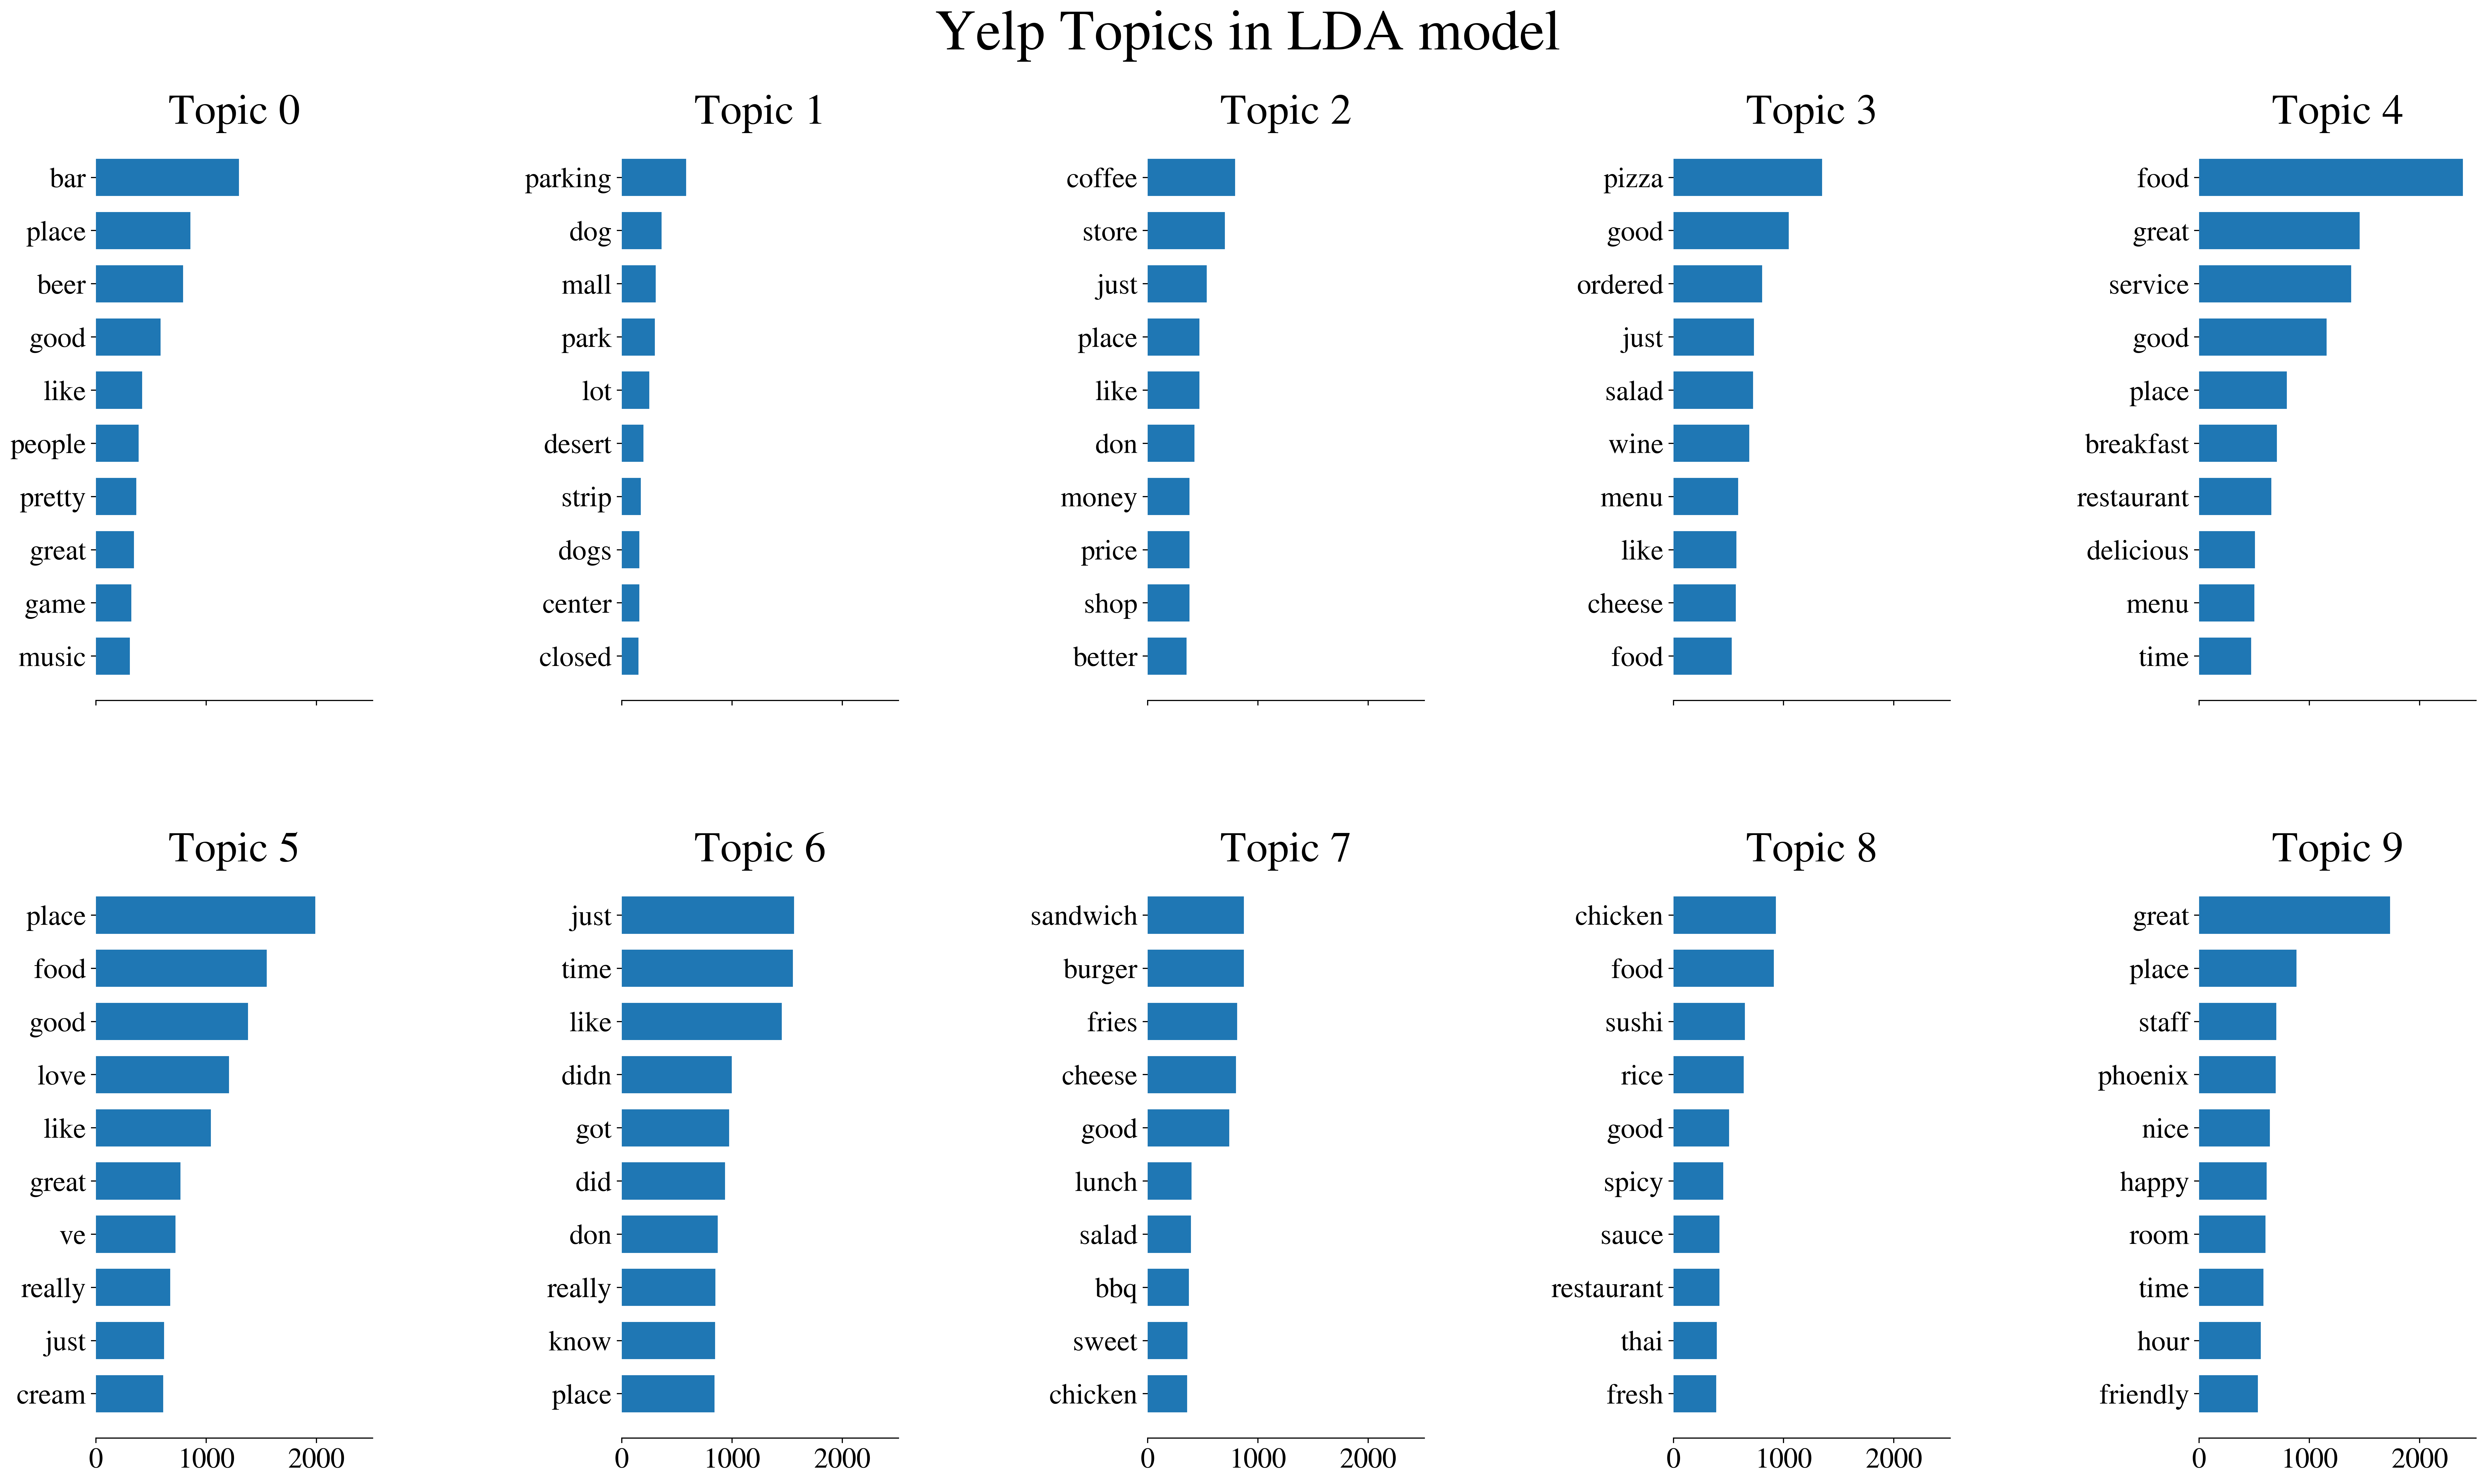

In [90]:
plot_top_words(lda, tf_feature_names, n_top_words, 'Yelp Topics in LDA model', 5, 2)

In [91]:
for topic_idx, topic in enumerate(lda.components_):
    #print(topic_idx, topic)
    top_features_ind = topic.argsort()[:-n_top_words - 1:-1]
    top_features = [tf_feature_names[i] for i in top_features_ind]
    weights = topic[top_features_ind]
    print('======================')
    print('Topic:', topic_idx)
    print('======================')
    print(dict(zip(top_features, weights)))
    print()


Topic: 0
{'bar': np.float64(1297.9623371053924), 'place': np.float64(855.7029976134654), 'beer': np.float64(790.7818185237192), 'good': np.float64(587.1642801229591), 'like': np.float64(417.615005226701), 'people': np.float64(385.7070620673454), 'pretty': np.float64(366.5763579842217), 'great': np.float64(345.74901212067886), 'game': np.float64(321.85141244485453), 'music': np.float64(308.2912308482939)}

Topic: 1
{'parking': np.float64(583.0640027912305), 'dog': np.float64(361.85360726759296), 'mall': np.float64(308.2805724094113), 'park': np.float64(300.19047232744776), 'lot': np.float64(250.39107782896906), 'desert': np.float64(197.64344623468037), 'strip': np.float64(172.12450038729284), 'dogs': np.float64(160.4321287949457), 'center': np.float64(159.73000565304375), 'closed': np.float64(152.62671925898542)}

Topic: 2
{'coffee': np.float64(793.7494106094111), 'store': np.float64(700.2064198650917), 'just': np.float64(535.8163731889545), 'place': np.float64(471.14344739814766), 'lik

In [92]:
# this step applies the model to our data and essentially produces topi predictions/classifications for the entire dataset
doc_topic = lda.transform(tf)
doc_topic.shape

(10000, 10)

In [93]:
#and list the doc and its highest score topic like this:
print(doc_topic[:10])
for n in range(10):
    topic_most_pr = doc_topic[n].argmax()
    print("doc: {} topic: {}\n".format(n,topic_most_pr))


[[2.00046378e-03 2.00028997e-03 2.00066809e-03 1.64830465e-01
  8.19165267e-01 2.00065639e-03 2.00067339e-03 2.00041346e-03
  2.00061576e-03 2.00048755e-03]
 [1.25041966e-03 1.25005657e-03 1.25036357e-03 5.44871195e-01
  1.25043717e-03 1.25040349e-03 4.45125898e-01 1.25043135e-03
  1.25035900e-03 1.25043626e-03]
 [2.02517357e-01 1.66668694e-02 1.66686121e-02 1.66736868e-02
  1.66717080e-02 2.71490443e-01 1.66671799e-02 1.66688109e-02
  4.09304559e-01 1.66707733e-02]
 [4.54653561e-03 9.59080963e-01 4.54696840e-03 4.54595206e-03
  4.54665559e-03 4.54709890e-03 4.54616217e-03 4.54596452e-03
  4.54590592e-03 4.54779398e-03]
 [4.16725412e-03 4.16741474e-03 4.16746983e-03 4.16724391e-03
  1.32531538e-01 4.16806757e-03 8.34128243e-01 4.16750868e-03
  4.16761792e-03 4.16764232e-03]
 [8.33464942e-04 8.33361149e-04 8.33485026e-04 8.62961357e-01
  8.33506355e-04 8.33537307e-04 1.30370405e-01 8.33822557e-04
  8.33528737e-04 8.33532328e-04]
 [7.78598285e-02 1.28238348e-03 1.28230828e-03 1.28251639e

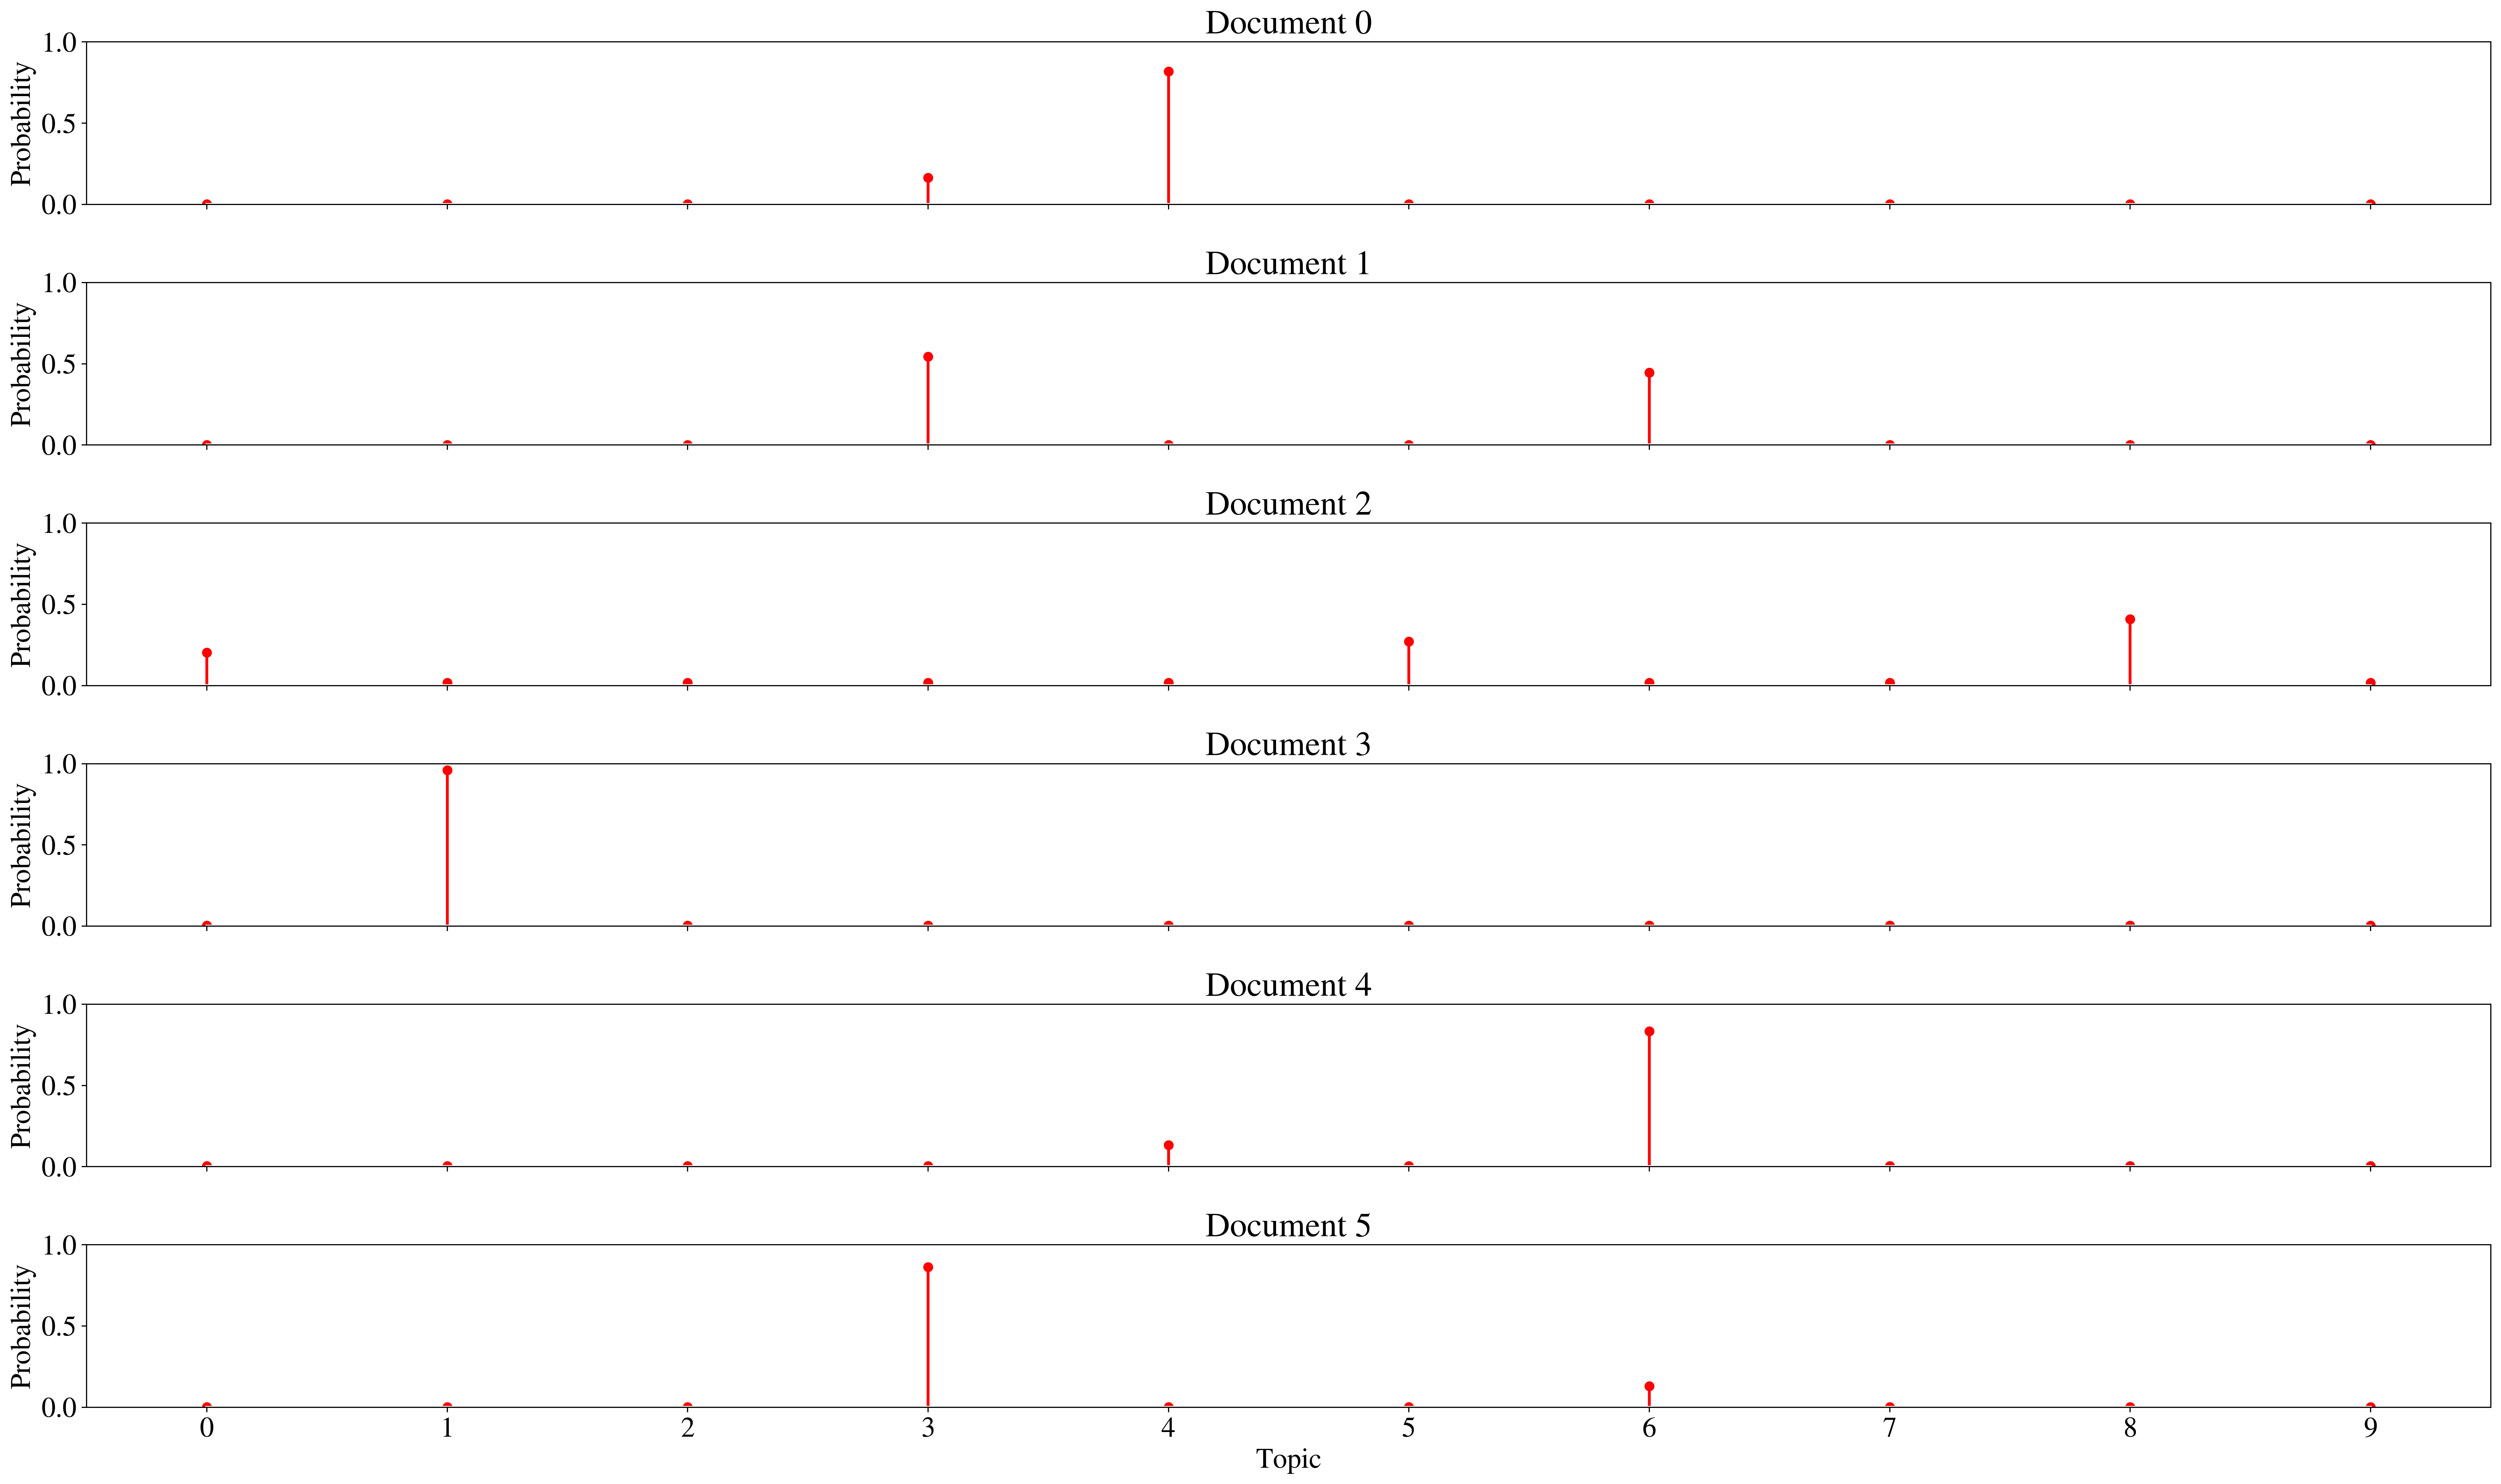

In [94]:
#doc_topic = model.doc_topic_
rcParams['xtick.labelsize'] = 20
rcParams['ytick.labelsize'] = 20

f, ax= plt.subplots(6, 1, figsize=(25, 15), sharex=True)
for i, k in enumerate(range(6)):
    ax[i].stem(doc_topic[k,:], linefmt='r-', markerfmt='ro', basefmt='w-')
    ax[i].set_xlim(-0.5, 9.5)
    ax[i].set_ylim(0, 1)
    ax[i].set_ylabel("Probability")
    ax[i].set_title("Document {}".format(k))
    ax[i].set_xticks(list(range(10)) )
    
ax[5].set_xlabel("Topic")

plt.tight_layout()
plt.show()

**Exercise:** Combine the two articles that we scraped in the above exercises into a dataset and perform LDA. This is obviously a small dataset and not ideal for this kind of analysis, but will be useful in validating topics that we clearly know exist in the articles. 

In [95]:
# cleaned_article

docs = pd.DataFrame((cleaned_article, cleaned_article2), columns = ['text'])

docs = docs['text'].values


In [96]:
n_features = 1000

print("Extracting tf features for LDA...")
tf_vectorizer = CountVectorizer(max_df=10, min_df=0.01,
                                max_features=n_features,
                                stop_words='english')
t0 = time()
tf = tf_vectorizer.fit_transform(docs)
print("TF-IDF done in %0.3fs." % (time() - t0))

#----------------LDA model-------------------
n_components = 3 # ie topics
n_top_words = 7

lda = LatentDirichletAllocation(n_components=n_components, max_iter=100,
                                learning_method='online',
                                learning_offset=50.,
                                random_state=0)
t0 = time()
lda.fit(tf)
print("LDA done in %0.3fs." % (time() - t0))

tf_feature_names = tf_vectorizer.get_feature_names_out()

Extracting tf features for LDA...
TF-IDF done in 0.006s.
LDA done in 0.094s.


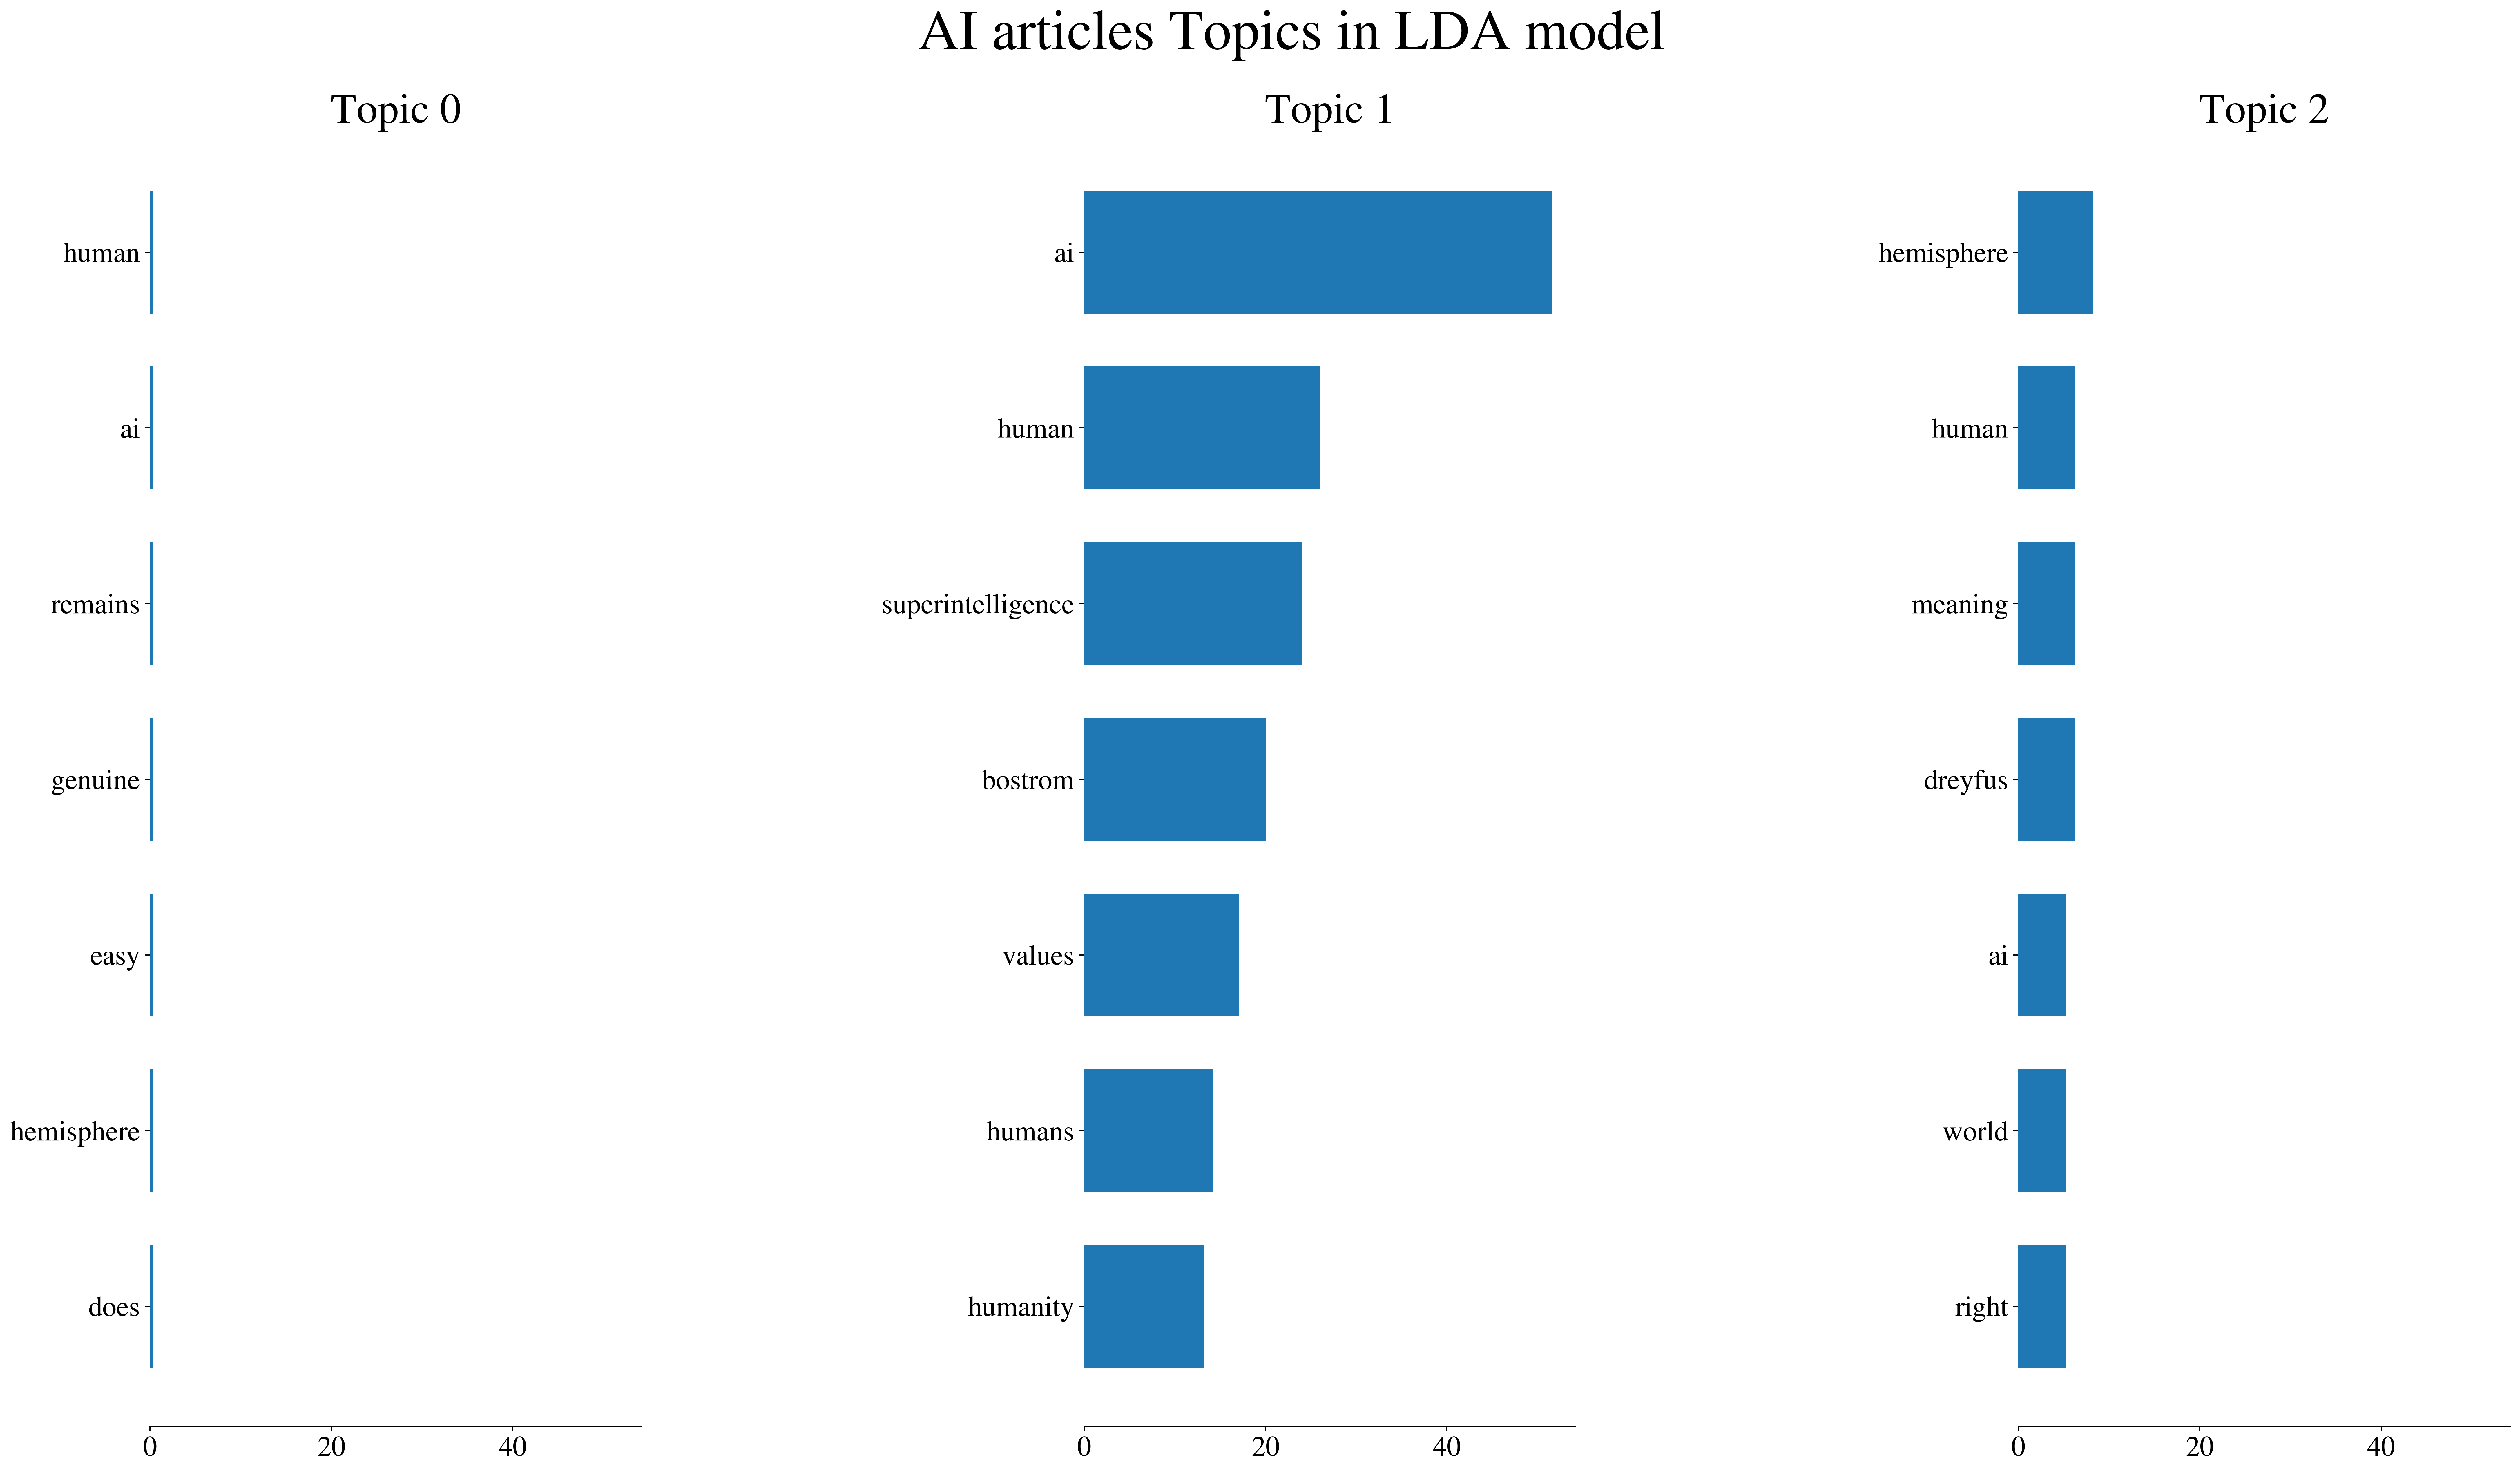

In [97]:
plot_top_words(lda, tf_feature_names, n_top_words, 'AI articles Topics in LDA model', 3, 1)

In [98]:
for topic_idx, topic in enumerate(lda.components_):
    #print(topic_idx, topic)
    top_features_ind = topic.argsort()[:-n_top_words - 1:-1]
    top_features = [tf_feature_names[i] for i in top_features_ind]
    weights = topic[top_features_ind]
    print('======================')
    print('Topic:', topic_idx)
    print('======================')
    print(dict(zip(top_features, weights)))
    print()

Topic: 0
{'human': np.float64(0.3549093787910862), 'ai': np.float64(0.35005001017315973), 'remains': np.float64(0.34732890203552796), 'genuine': np.float64(0.34731659106978174), 'easy': np.float64(0.3470581009968996), 'hemisphere': np.float64(0.34694054723941453), 'does': np.float64(0.3469306398894086)}

Topic: 1
{'ai': np.float64(51.61354448108035), 'human': np.float64(25.97349347762693), 'superintelligence': np.float64(24.001921397504976), 'bostrom': np.float64(20.05912968724613), 'values': np.float64(17.105380921756083), 'humans': np.float64(14.148248766409722), 'humanity': np.float64(13.160371526711067)}

Topic: 2
{'hemisphere': np.float64(8.228375237295545), 'human': np.float64(6.261852176121661), 'meaning': np.float64(6.256252498236659), 'dreyfus': np.float64(6.255859518654275), 'ai': np.float64(5.275231023420409), 'world': np.float64(5.273905311409901), 'right': np.float64(5.2738759361516925)}



In [99]:
doc_topic = lda.transform(tf)
doc_topic.shape

(2, 3)

In [100]:
#and list the doc and its highest score topic like this:
print(doc_topic[:3])
for n in range(2):
    topic_most_pr = doc_topic[n].argmax()
    print("doc: {} topic: {}\n".format(n,topic_most_pr))


[[2.35667274e-04 9.99522570e-01 2.41762640e-04]
 [7.22782071e-04 7.56527475e-04 9.98520690e-01]]
doc: 0 topic: 1

doc: 1 topic: 2



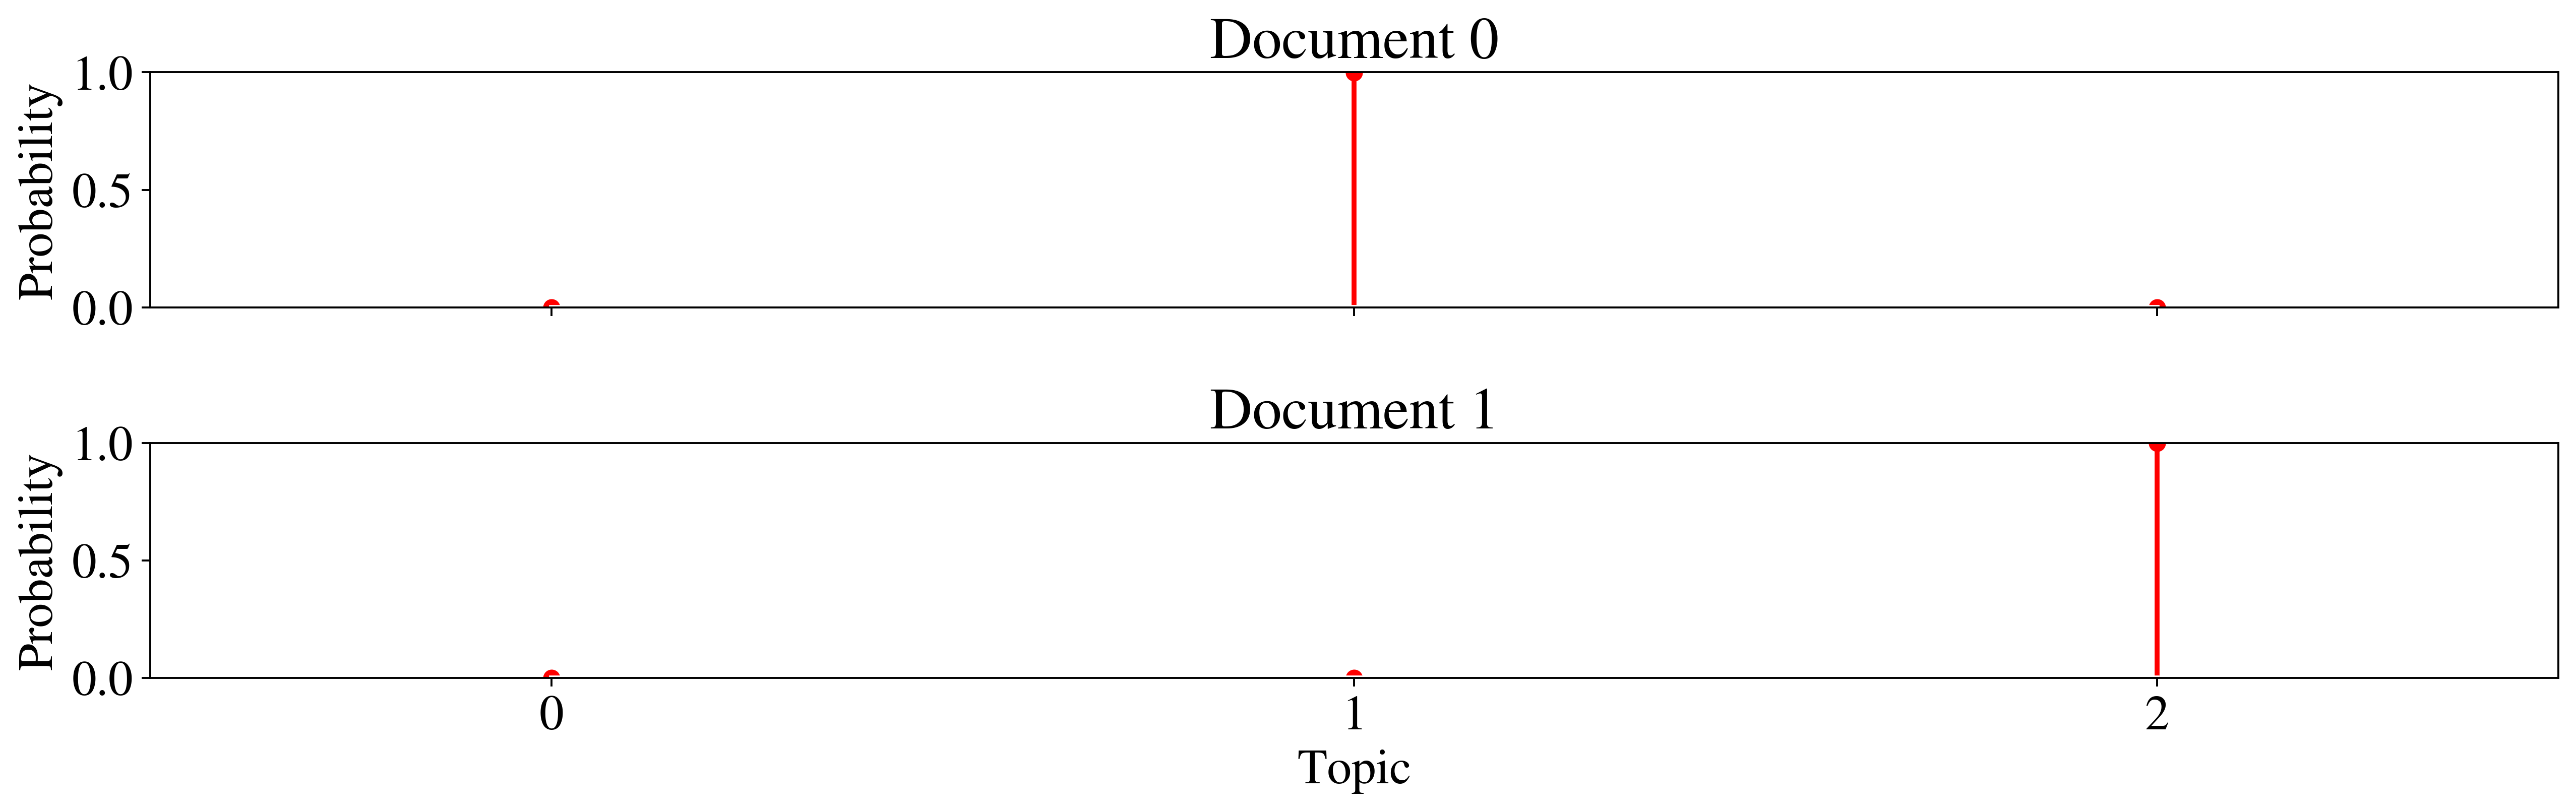

In [101]:
#doc_topic = model.doc_topic_
rcParams['xtick.labelsize'] = 20
rcParams['ytick.labelsize'] = 20

f, ax= plt.subplots(2, 1, figsize=(15, 5), sharex=True)
for i, k in enumerate(range(2)):
    ax[i].stem(doc_topic[k,:], linefmt='r-', markerfmt='ro', basefmt='w-')
    ax[i].set_xlim(-0.5, 2.5)
    ax[i].set_ylim(0, 1)
    ax[i].set_ylabel("Probability")
    ax[i].set_title("Document {}".format(k))
    ax[i].set_xticks(list(range(3)) )
    
ax[1].set_xlabel("Topic")

plt.tight_layout()
plt.show()

**Bonus Exercise:** Scrape another article. Clean it in the same manner that we cleaned the previous articles. Then apply the LDA model in order to extract topics from it.

# Text Classification 

## Training a Classifier for Sentiment Classification  From Scratch

We will use a sample of Yelp reviews for building sentiment classification models.

We will go though the machine learning process, experimenting and tweaking the features until we arrive at a desirable accuracy.

In [1]:
import pandas as pd
import numpy as np
import scipy as sp
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB, GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn import metrics
from textblob import TextBlob, Word
from nltk.stem.snowball import SnowballStemmer

In [2]:
yelp = pd.read_csv("yelp_reviews.csv")


In [105]:
len(yelp)

10000

In [106]:
yelp.head()


,business_id,date,review_id,stars,text,type,user_id,cool,useful,funny
0,9yKzy9PApeiPPOUJEtnvkg,2011-01-26,fWKvX83p0-ka4JS3dc6E5A,5,My wife took me here on my birthday for breakf...,review,rLtl8ZkDX5vH5nAx9C3q5Q,2,5,0
1,ZRJwVLyzEJq1VAihDhYiow,2011-07-27,IjZ33sJrzXqU-0X6U8NwyA,5,I have no idea why some people give bad review...,review,0a2KyEL0d3Yb1V6aivbIuQ,0,0,0
2,6oRAC4uyJCsJl1X0WZpVSA,2012-06-14,IESLBzqUCLdSzSqm0eCSxQ,4,love the gyro plate. Rice is so good and I als...,review,0hT2KtfLiobPvh6cDC8JQg,0,1,0
3,_1QQZuf4zZOyFCvXc0o6Vg,2010-05-27,G-WvGaISbqqaMHlNnByodA,5,"Rosie, Dakota, and I LOVE Chaparral Dog Park!!...",review,uZetl9T0NcROGOyFfughhg,1,2,0
4,6ozycU1RpktNG2-1BroVtw,2012-01-05,1uJFq2r5QfJG_6ExMRCaGw,5,General Manager Scott Petello is a good egg!!!...,review,vYmM4KTsC8ZfQBg-j5MWkw,0,0,0


In [3]:
# create a new DataFrame that only contains the 5-star and 1-star reviews
yelp_best_worst = yelp[(yelp.stars==5) | (yelp.stars==1)]


In [4]:
print('total dataset size: ',len(yelp_best_worst))


total dataset size:  4086


### Use default CountVectorizer to train entire dataset first and test it against the training set too

Performing training and testing on just the training test gives us an idea of what the upper boundary of classification would be given a particular machine learning algorithm and dataset and is thus a useful exercise. Using the Naive Bayes classifier for this is particularly advantageous because NB is less prone to overfitting and generates a simple liner decision boundary between classes.

In [5]:
X_train = yelp_best_worst.text.values
y_train = yelp_best_worst.stars.values


In [6]:
print(X_train.shape)
print(y_train.shape)


(4086,)
(4086,)


In [7]:
#Initialises an object of count vectorizers
# rows are documents, columns are terms (aka "tokens" or "features")
#It adds features to the review to represent all words in the dataset. = sparse matrix.
#most counts will be zero.
# use CountVectorizer to create document-term matrices from X_train and X_test
vect = CountVectorizer()
train_dtm = vect.fit_transform(X_train)


In [8]:
#We end up with a training dataset of 4086 rows and 19183 features
train_dtm.shape


(4086, 19183)

In [9]:
#number of features
print( len(vect.get_feature_names_out()))
print( 'Features: ', train_dtm.shape[1])


19183
Features:  19183


In [10]:
# first 500 features
print(vect.get_feature_names_out()[:500])


['00' '000' '00a' '00am' '00pm' '01' '02' '03' '03342' '04' '05' '06' '07'
 '09' '0buxoc0crqjpvkezo3bqog' '0l' '10' '100' '1000' '1000x' '1001'
 '100s' '100th' '101' '102' '1030' '105' '1070' '108' '109' '10am' '10ish'
 '10min' '10mins' '10minutes' '10pm' '10th' '10x' '10yo' '11' '110' '1100'
 '111' '111th' '112' '115' '115th' '116' '118' '11a' '11am' '11p' '11pm'
 '12' '120' '128i' '129' '12am' '12oz' '12pm' '12th' '13' '1300' '13331'
 '13th' '14' '140' '147' '14lbs' '15' '150' '1500' '150mm' '157' '15am'
 '15mins' '15pm' '15th' '16' '160' '165' '169' '16th' '17' '175' '17p'
 '17th' '18' '180' '1800' '1895' '18th' '19' '1900' '1913' '1928' '1929'
 '1930s' '1940' '1952' '1955' '1956' '1960' '1961' '1968' '1969' '1970'
 '1978' '1980' '1980s' '1987' '1990' '1990s' '1992' '1995' '1996' '1997'
 '1998' '1999' '19th' '1cent' '1k' '1p' '1pm' '1st' '20' '200' '2002'
 '2003' '2004' '2005' '2006' '2007' '2008' '2009' '200lbs' '2010' '2011'
 '2012' '202' '20mbs' '20miles' '20min' '20minutes' '20p

The array will be mostly empty - sparse. eg: first three rows and ten columns

In [11]:
train_dtm[0:3, 0:10].toarray()


array([[0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
       [0, 0, 0, 0, 0, 0, 1, 0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 0, 0, 0]])

In [12]:
#number of features
print( len(vect.get_feature_names_out()))
print( 'Features: ', train_dtm.shape[1])


19183
Features:  19183


In [13]:
#We use MultinomialNB since we are dealing with counts
nb = MultinomialNB()
nb.fit(train_dtm, y_train)



MultinomialNB()

In [14]:
y_pred_class = nb.predict(train_dtm)
print( 'Accuracy: ', metrics.accuracy_score(y_train, y_pred_class))


Accuracy:  0.9718551150269212


Anything that approaches this level of accuracy will be regarded as a good classification performance.

In [15]:
print( 'F1: ', metrics.f1_score(y_train, y_pred_class))

F1:  0.921715452688904


### Use default CountVectorizer which creates a list of term/frequency features for every review on  a split dataset

In [16]:
# split the new DataFrame into training and testing sets
# Gives us 75 train : 25 test split
X_train, X_test, y_train, y_test = train_test_split(yelp_best_worst.text, yelp_best_worst.stars, random_state=1, train_size=0.75)


In [17]:
type(X_train)

pandas.core.series.Series

In [18]:
print( 'training dataset size: ', len(X_train))
print( 'test dataset size: ',  len(X_test))


training dataset size:  3064
test dataset size:  1022


In [19]:
print( y_train.shape)
print( y_test.shape)


(3064,)
(1022,)


In [20]:
#Initialises an object of count vectorizers
# rows are documents, columns are terms (aka "tokens" or "features")
#It adds features to the review to represent all words (16825) in the dataset. = sparse matrix.
#most counts will be zero.
# use CountVectorizer to create document-term matrices from X_train and X_test
vect = CountVectorizer()
train_dtm = vect.fit_transform(X_train)
test_dtm = vect.transform(X_test)


In [21]:
#We end up with a training dataset of 3064 rows and 16825 features
train_dtm.shape


(3064, 16825)

In [22]:
test_dtm.shape

(1022, 16825)

In [23]:
#We use MultinomialNB since we are dealing with counts
nb = MultinomialNB()
nb.fit(train_dtm, y_train)


MultinomialNB()

In [24]:
y_pred_class = nb.predict(test_dtm)
print( 'Accuracy: ', metrics.accuracy_score(y_test, y_pred_class))


Accuracy:  0.9187866927592955


### Use default CountVectorizer with filtered stopwords 

In [25]:
# remove English stop words
vect = CountVectorizer(stop_words='english')
train_dtm = vect.fit_transform(X_train)
print( 'Features: ', train_dtm.shape[1])
test_dtm = vect.transform(X_test)
nb = MultinomialNB()
nb.fit(train_dtm, y_train)
y_pred_class = nb.predict(test_dtm)
print( 'Accuracy: ', metrics.accuracy_score(y_test, y_pred_class))


Features:  16528
Accuracy:  0.9158512720156555


### Use default CountVectorizer with filtered stopwords and select top 100

In [26]:
# remove English stop words and only keep 100 features
vect = CountVectorizer(stop_words='english', max_features=100)
train_dtm = vect.fit_transform(X_train)
print( 'Features: ', train_dtm.shape[1])
test_dtm = vect.transform(X_test)
nb = MultinomialNB()
nb.fit(train_dtm, y_train)
y_pred_class = nb.predict(test_dtm)
print( 'Accuracy: ', metrics.accuracy_score(y_test, y_pred_class))



Features:  100
Accuracy:  0.8698630136986302


**Exercise:** Train a classifier on top 10000 words

In [27]:
# remove English stop words and only keep 10000 features
vect = CountVectorizer(stop_words='english', max_features=10000)
train_dtm = vect.fit_transform(X_train)
print( 'Features: ', train_dtm.shape[1])
test_dtm = vect.transform(X_test)
nb = MultinomialNB()
nb.fit(train_dtm, y_train)
y_pred_class = nb.predict(test_dtm)
print( 'Accuracy: ', metrics.accuracy_score(y_test, y_pred_class))

Features:  10000
Accuracy:  0.9217221135029354


**Exercise:** Train a classifier on bigram frequencies 

In [28]:
bigram_vectorizer = CountVectorizer(ngram_range=(2, 2), stop_words='english')
train_dtm = bigram_vectorizer.fit_transform(X_train)
print( 'Features: ', train_dtm.shape[1])

test_dtm = bigram_vectorizer.transform(X_test)
nb = MultinomialNB()
nb.fit(train_dtm, y_train)
y_pred_class = nb.predict(test_dtm)
print( 'Accuracy: ', metrics.accuracy_score(y_test, y_pred_class))

Features:  133506
Accuracy:  0.8816046966731899


**Exercise:** Train a classifier on bigrams and restricting to top 10000 

In [29]:
bigram_vectorizer = CountVectorizer(ngram_range=(2, 2), stop_words='english', max_features = 10000)
train_dtm = bigram_vectorizer.fit_transform(X_train)
print( 'Features: ', train_dtm.shape[1])

test_dtm = bigram_vectorizer.transform(X_test)
nb = MultinomialNB()
nb.fit(train_dtm, y_train)
y_pred_class = nb.predict(test_dtm)
print( 'Accuracy: ', metrics.accuracy_score(y_test, y_pred_class))

Features:  10000
Accuracy:  0.8904109589041096


**Exercise:** Train a classifier on bigrams including terms that appear at least 2 times

In [30]:
bigram_vectorizer = CountVectorizer(ngram_range=(2, 2), min_df=2, stop_words='english')
train_dtm = bigram_vectorizer.fit_transform(X_train)
print( 'Features: ', train_dtm.shape[1])

test_dtm = bigram_vectorizer.transform(X_test)
nb = MultinomialNB()
nb.fit(train_dtm, y_train)
y_pred_class = nb.predict(test_dtm)
print( 'Accuracy: ', metrics.accuracy_score(y_test, y_pred_class))




Features:  13134
Accuracy:  0.8943248532289628


**Exercise:** Train a classifier on word counts, but this time normalise all the words using a SnowballStemmer lemmatizer.

In [41]:
from nltk.tokenize import word_tokenize
import string
from nltk.corpus import stopwords
import re as re
def preprocess_text(corpus):
    # Initialize the Snowball Stemmer for English
    stemmer = SnowballStemmer("english")
    # Define stopwords for English
    stop_words = set(stopwords.words("english"))
    # List to store processed text
    processed_corpus = []

    for text in corpus:
        # Remove punctuation and convert to lowercase
        text = re.sub(r'[^a-zA-Z\s]', '', text.lower())
        # Tokenize the text
        tokens = word_tokenize(text)
        # Remove stopwords and apply stemming
        stemmed_tokens = [
            stemmer.stem(token) for token in tokens if token not in stop_words
        ]
        # Join the stemmed tokens back into a string
        processed_text = ' '.join(stemmed_tokens)
        processed_corpus.append(processed_text)
    
    return processed_corpus

In [42]:
X_train_sb = preprocess_text(X_train)
X_test_sb = preprocess_text(X_test)

In [43]:
vect = CountVectorizer(stop_words='english', max_features=10000)
train_dtm = vect.fit_transform(X_train_sb)
print( 'Features: ', train_dtm.shape[1])
test_dtm = vect.transform(X_test_sb)
nb = MultinomialNB()
nb.fit(train_dtm, y_train)
y_pred_class = nb.predict(test_dtm)
print( 'Accuracy: ', metrics.accuracy_score(y_test, y_pred_class))


Features:  10000
Accuracy:  0.9246575342465754


Passing numeric regular expression into account vectoriser may improve results further. Or use the dictionary to filter out misspelled words. There are a number of other trial and error tweaks to the training that could be performed.

### Use TF-IDF

In [44]:
# create a document-term matrix using TF-IDF
vect = TfidfVectorizer(stop_words='english',max_features=1000)
dtm = vect.fit_transform(yelp.text)
# features = vect.get_feature_names()


train_dtm = vect.fit_transform(X_train)
print( train_dtm.shape)
print( 'Features: ', train_dtm.shape[1])
test_dtm = vect.transform(X_test)
nb = MultinomialNB()
nb.fit(train_dtm, y_train)
y_pred_class = nb.predict(test_dtm)
print( 'Accuracy: ', metrics.accuracy_score(y_test, y_pred_class))

(3064, 1000)
Features:  1000
Accuracy:  0.8835616438356164


In [95]:
train_dtm[0]

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 1 stored elements and shape (1, 50)>

**Exercise:** Train a classifier again using TF-IDF features, and this time experiment with different subsets/numbers of features and observe changes in accuracy.

In [45]:
# create a document-term matrix using TF-IDF
vect = TfidfVectorizer(stop_words='english',max_features=10000)
dtm = vect.fit_transform(yelp.text)
# features = vect.get_feature_names()


train_dtm = vect.fit_transform(X_train)
print( train_dtm.shape)
print( 'Features: ', train_dtm.shape[1])
test_dtm = vect.transform(X_test)
nb = MultinomialNB()
nb.fit(train_dtm, y_train)
y_pred_class = nb.predict(test_dtm)
print( 'Accuracy: ', metrics.accuracy_score(y_test, y_pred_class))

(3064, 10000)
Features:  10000
Accuracy:  0.8228962818003914


In [46]:
# create a document-term matrix using TF-IDF
vect = TfidfVectorizer(stop_words='english',max_features=10000)
dtm = vect.fit_transform(yelp.text)
# features = vect.get_feature_names()


train_dtm = vect.fit_transform(X_train)
print( train_dtm.shape)
print( 'Features: ', train_dtm.shape[1])
test_dtm = vect.transform(X_test)
nb = MultinomialNB()
nb.fit(train_dtm, y_train)
y_pred_class = nb.predict(test_dtm)
print( 'Accuracy: ', metrics.accuracy_score(y_test, y_pred_class))

(3064, 10000)
Features:  10000
Accuracy:  0.8228962818003914


In [47]:
# create a document-term matrix using TF-IDF
vect = TfidfVectorizer(ngram_range=(2, 2), min_df=2, stop_words='english',max_features=50)
dtm = vect.fit_transform(yelp.text)
# features = vect.get_feature_names()


train_dtm = vect.fit_transform(X_train)
print( train_dtm.shape)
print( 'Features: ', train_dtm.shape[1])
test_dtm = vect.transform(X_test)
nb = MultinomialNB()
nb.fit(train_dtm, y_train)
y_pred_class = nb.predict(test_dtm)
print( 'Accuracy: ', metrics.accuracy_score(y_test, y_pred_class))

(3064, 50)
Features:  50
Accuracy:  0.8297455968688845


### Use LDA

Another way to geenrate features is to train an LDA model and then use it to extract topic distribution probabilities as additional features. Prior to classifying a new piece of text, the LDA model would need to be run on the text first in order to extract the features, followed by the machine learning algorithm.

**Bonus Exercise:** Train a classifier sentiment analysis classifier just using LDA topics. 

In [64]:
from sklearn.decomposition import LatentDirichletAllocation

n_features = 10000

print("Extracting tf features for LDA...")
vectorisor = CountVectorizer(max_df=0.95, min_df=2, max_features=n_features,stop_words='english')
t0 = time()
dtm = vectorisor.fit_transform(yelp_best_worst.text)
print("done in %0.3fs." % (time() - t0))

n_components = 10 # ie topics
n_top_words = 10

LDA = LatentDirichletAllocation(n_components=n_components, max_iter=10,
                                learning_method='online',
                                learning_offset=50.,
                                random_state=0)
# t0 = time()
LDA.fit(dtm)
# print("done in %0.3fs." % (time() - t0))

tf_feature_names = vectorisor.get_feature_names_out()

topic_distributions = LDA.transform(dtm)

Extracting tf features for LDA...
done in 0.257s.


In [91]:
topic_distributions[0]

array([0.00142857, 0.01583592, 0.00142857, 0.00142864, 0.0014286 ,
       0.00142894, 0.00142857, 0.97273483, 0.00142877, 0.00142857])

In [71]:
# X_train, X_test, y_train, y_test = train_test_split(topic_distributions, sentiment_labels, test_size=0.2, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(topic_distributions, yelp_best_worst.stars, random_state=1, train_size=0.75)

nb = MultinomialNB()
nb.fit(X_train, y_train)
# y_pred_class = nb.predict(test_dtm)
y_pred_class = nb.predict(X_test)

print( 'Accuracy: ', metrics.accuracy_score(y_test, y_pred_class))

Accuracy:  0.8199608610567515


### Alternative Features Engineering Techniques

We are now going to continue experimenting with this problem and get more creative with the "feature engineering" component in the hope that we generate new features which are more discriminative in their predictive strength of the target class labels.

In [78]:
# understanding the apply method
yelp['length'] = yelp.text.apply(len)


In [79]:
yelp.head()

,business_id,date,review_id,stars,text,type,user_id,cool,useful,funny,length
0,9yKzy9PApeiPPOUJEtnvkg,2011-01-26,fWKvX83p0-ka4JS3dc6E5A,5,My wife took me here on my birthday for breakf...,review,rLtl8ZkDX5vH5nAx9C3q5Q,2,5,0,901
1,ZRJwVLyzEJq1VAihDhYiow,2011-07-27,IjZ33sJrzXqU-0X6U8NwyA,5,I have no idea why some people give bad review...,review,0a2KyEL0d3Yb1V6aivbIuQ,0,0,0,1353
2,6oRAC4uyJCsJl1X0WZpVSA,2012-06-14,IESLBzqUCLdSzSqm0eCSxQ,4,love the gyro plate. Rice is so good and I als...,review,0hT2KtfLiobPvh6cDC8JQg,0,1,0,76
3,_1QQZuf4zZOyFCvXc0o6Vg,2010-05-27,G-WvGaISbqqaMHlNnByodA,5,"Rosie, Dakota, and I LOVE Chaparral Dog Park!!...",review,uZetl9T0NcROGOyFfughhg,1,2,0,427
4,6ozycU1RpktNG2-1BroVtw,2012-01-05,1uJFq2r5QfJG_6ExMRCaGw,5,General Manager Scott Petello is a good egg!!!...,review,vYmM4KTsC8ZfQBg-j5MWkw,0,0,0,473


In [236]:
# define a function that accepts text and returns the polarity
def detect_sentiment(text):
    return TextBlob(text).sentiment.polarity


# create a new DataFrame column for sentiment
yelp['sentiment'] = yelp.text.apply(detect_sentiment)
yelp.head()

,business_id,date,review_id,stars,text,type,user_id,cool,useful,funny,sentiment
0,9yKzy9PApeiPPOUJEtnvkg,2011-01-26,fWKvX83p0-ka4JS3dc6E5A,5,My wife took me here on my birthday for breakf...,review,rLtl8ZkDX5vH5nAx9C3q5Q,2,5,0,0.402469
1,ZRJwVLyzEJq1VAihDhYiow,2011-07-27,IjZ33sJrzXqU-0X6U8NwyA,5,I have no idea why some people give bad review...,review,0a2KyEL0d3Yb1V6aivbIuQ,0,0,0,0.229773
2,6oRAC4uyJCsJl1X0WZpVSA,2012-06-14,IESLBzqUCLdSzSqm0eCSxQ,4,love the gyro plate. Rice is so good and I als...,review,0hT2KtfLiobPvh6cDC8JQg,0,1,0,0.566667
3,_1QQZuf4zZOyFCvXc0o6Vg,2010-05-27,G-WvGaISbqqaMHlNnByodA,5,"Rosie, Dakota, and I LOVE Chaparral Dog Park!!...",review,uZetl9T0NcROGOyFfughhg,1,2,0,0.608646
4,6ozycU1RpktNG2-1BroVtw,2012-01-05,1uJFq2r5QfJG_6ExMRCaGw,5,General Manager Scott Petello is a good egg!!!...,review,vYmM4KTsC8ZfQBg-j5MWkw,0,0,0,0.468125


<Axes: title={'center': 'sentiment'}, xlabel='stars'>

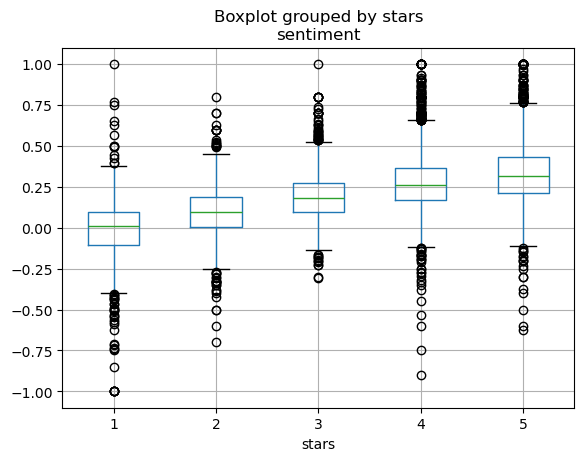

In [102]:
# boxplot of sentiment grouped by stars
yelp.boxplot(column='sentiment', by='stars',fontsize=10)



In [82]:
yelp_best_worst.head()

,business_id,date,review_id,stars,text,type,user_id,cool,useful,funny
0,9yKzy9PApeiPPOUJEtnvkg,2011-01-26,fWKvX83p0-ka4JS3dc6E5A,5,My wife took me here on my birthday for breakf...,review,rLtl8ZkDX5vH5nAx9C3q5Q,2,5,0
1,ZRJwVLyzEJq1VAihDhYiow,2011-07-27,IjZ33sJrzXqU-0X6U8NwyA,5,I have no idea why some people give bad review...,review,0a2KyEL0d3Yb1V6aivbIuQ,0,0,0
3,_1QQZuf4zZOyFCvXc0o6Vg,2010-05-27,G-WvGaISbqqaMHlNnByodA,5,"Rosie, Dakota, and I LOVE Chaparral Dog Park!!...",review,uZetl9T0NcROGOyFfughhg,1,2,0
4,6ozycU1RpktNG2-1BroVtw,2012-01-05,1uJFq2r5QfJG_6ExMRCaGw,5,General Manager Scott Petello is a good egg!!!...,review,vYmM4KTsC8ZfQBg-j5MWkw,0,0,0
6,zp713qNhx8d9KCJJnrw1xA,2010-02-12,riFQ3vxNpP4rWLk_CSri2A,5,Drop what you're doing and drive here. After I...,review,wFweIWhv2fREZV_dYkz_1g,7,7,4


In [83]:
# create a new DataFrame that only contains the 5-star and 1-star reviews
yelp_best_worst = yelp[(yelp.stars==5) | (yelp.stars==1)]

# split the new DataFrame into training and testing sets
feature_cols = ['sentiment', 'cool', 'useful', 'funny', 'length']
X = yelp_best_worst[feature_cols]
y = yelp_best_worst.stars


This will now be our classification dataset features:

In [86]:
X.head()

,sentiment,cool,useful,funny,length
0,0.402469,2,5,0,901
1,0.229773,0,0,0,1353
3,0.608646,1,2,0,427
4,0.468125,0,0,0,473
6,0.300645,7,7,4,1577


In [96]:
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=1)


In [97]:
print('Features: ', X_train.shape[1])
nb = GaussianNB()
nb.fit(X_train, y_train)
y_pred_class = nb.predict(X_test)
print('Accuracy: ', metrics.accuracy_score(y_test, y_pred_class))


Features:  5
Accuracy:  0.8904109589041096


**Exercise:** Add a new feature called subjectivity which represents the subjectivity of the review. Train a classifier with the new feature and observe changes in accuracy.

In [98]:
#Define a function that accepts text and returns polarity
def detect_sentiment_subjectivity(text):
    
    return TextBlob(text).sentiment.subjectivity

#create a new dataframe column for sentiment


In [103]:
yelp['subjectivity'] = yelp.text.apply(detect_sentiment_subjectivity)
# create a new DataFrame that only contains the 5-star and 1-star reviews
yelp_best_worst = yelp[(yelp.stars==5) | (yelp.stars==1)]

# split the new DataFrame into training and testing sets
feature_cols = ['sentiment', 'subjectivity', 'cool', 'useful', 'funny', 'length']
X = yelp_best_worst[feature_cols]
y = yelp_best_worst.stars

yelp.head()

,business_id,date,review_id,stars,text,type,user_id,cool,useful,funny,length,sentiment,subjectivity
0,9yKzy9PApeiPPOUJEtnvkg,2011-01-26,fWKvX83p0-ka4JS3dc6E5A,5,My wife took me here on my birthday for breakf...,review,rLtl8ZkDX5vH5nAx9C3q5Q,2,5,0,901,0.402469,0.659112
1,ZRJwVLyzEJq1VAihDhYiow,2011-07-27,IjZ33sJrzXqU-0X6U8NwyA,5,I have no idea why some people give bad review...,review,0a2KyEL0d3Yb1V6aivbIuQ,0,0,0,1353,0.229773,0.638485
2,6oRAC4uyJCsJl1X0WZpVSA,2012-06-14,IESLBzqUCLdSzSqm0eCSxQ,4,love the gyro plate. Rice is so good and I als...,review,0hT2KtfLiobPvh6cDC8JQg,0,1,0,76,0.566667,0.733333
3,_1QQZuf4zZOyFCvXc0o6Vg,2010-05-27,G-WvGaISbqqaMHlNnByodA,5,"Rosie, Dakota, and I LOVE Chaparral Dog Park!!...",review,uZetl9T0NcROGOyFfughhg,1,2,0,427,0.608646,0.700000
4,6ozycU1RpktNG2-1BroVtw,2012-01-05,1uJFq2r5QfJG_6ExMRCaGw,5,General Manager Scott Petello is a good egg!!!...,review,vYmM4KTsC8ZfQBg-j5MWkw,0,0,0,473,0.468125,0.810000


In [104]:
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=1)
print('Features: ', X_train.shape[1])
nb = GaussianNB()
nb.fit(X_train, y_train)
y_pred_class = nb.predict(X_test)
print('Accuracy: ', metrics.accuracy_score(y_test, y_pred_class))

Features:  6
Accuracy:  0.8747553816046967


---


# Information Retreival 

<div style="background-color: lightblue; padding: 10px;">

### Retrieval-Augmented Generation (RAG) in Modern Information Retrieval for LLMs

The advent of **Retrieval-Augmented Generation (RAG)** has revolutionised the field of information retrieval by seamlessly integrating traditional retrieval methods with the advanced capabilities of large language models (LLMs) such as GPT. This hybrid approach enhances the performance of LLMs by overcoming a fundamental limitation: their inability to access external knowledge dynamically in real-time. By incorporating a retrieval mechanism, RAG allows models to condition their generative process on external data, leading to more accurate, fact-grounded outputs.

#### How RAG Works:

RAG operates through a two-step process that combines retrieval and generation:

1. **Retrieval Step:** The model first retrieves the `k` most relevant documents or passages from a corpus using a similarity-based method, such as dense vector representations or traditional techniques like TF-IDF combined with cosine similarity. The purpose of this step is to locate the most contextually relevant information related to the query.

2. **Generation Step:** The retrieved documents are then passed to a pre-trained generative model, which uses this external information as additional context to generate a coherent and accurate response. This conditioning on factual, retrieved content significantly improves the generative output, ensuring it is both relevant and factually correct.

RAG is particularly effective in high-stakes NLP applications such as **question answering**, **automatic summarisation**, and **fact-checking**, where retrieving relevant, factual information is essential. By combining retrieval with generation, RAG provides a mechanism to bridge the gap between static knowledge encoded in the language model and the dynamic, ever-changing world of real-time information.

#### Comparison to Traditional Information Retrieval (IR):

- **Efficiency:** Traditional IR methods, such as TF-IDF and cosine similarity, remain efficient for simpler, well-defined retrieval tasks. These methods are lightweight and computationally inexpensive, making them useful when resources are limited. However, they fall short when handling complex, open-ended queries that require deeper contextual understanding.
  
- **Contextual Understanding:** RAG leverages the contextual understanding of pre-trained LLMs, making it far superior for handling complex queries that involve semantic reasoning. While traditional methods rank documents based purely on lexical similarities, RAG’s use of a generative model allows it to infer meaning and respond in a way that captures the nuance and context of the query.

- **Scalability and Adaptability:** RAG is inherently more scalable and flexible, particularly for large datasets or domain-specific applications where retrieving accurate and context-aware information is critical. When combined with domain-specific knowledge bases, RAG provides an adaptive solution capable of evolving with new information, unlike traditional IR methods, which rely on static datasets.

#
While traditional information retrieval techniques like TF-IDF and cosine similarity continue to serve as valuable tools for straightforward retrieval tasks, **Retrieval-Augmented Generation (RAG)** represents a major leap forward for more sophisticated applications. By integrating retrieval with the generative capabilities of LLMs, RAG brings the best of both worlds—fact-based retrieval from large, dynamic datasets, and powerful generative abilities that can adapt and respond to complex queries with contextual precision.


In [105]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Assume thats the data we have (4 short documents)
data = [
    'I like tennis and swimming',
    'I love swimming and skiing',
    'I prefer skiing over tennis',
    'Playing sport is awful'
]

# Vectorise the data
vec = TfidfVectorizer()
X = vec.fit_transform(data) # `X` will now be a TF-IDF representation of the data, the first row of `X` corresponds to the first sentence in `data`

# Calculate the pairwise cosine similarities (depending on the amount of data that you are going to have this could take a while)
S = cosine_similarity(X)
S

array([[1.        , 0.43395521, 0.2039269 , 0.        ],
       [0.43395521, 1.        , 0.2039269 , 0.        ],
       [0.2039269 , 0.2039269 , 1.        , 0.        ],
       [0.        , 0.        , 0.        , 1.        ]])

**Exercise:** Complete the function below which takes the target text, a k number of requested closest texts, the tf-idf matrix and the original dataset. It should return the k number of closest texts to the target text.

In [129]:
def select_k_closest(target, k, distance_matrix, data): 
    res = list(np.argsort(distance_matrix[target])[-k-1:-1])
    res.reverse()
    result = [ (S[target, i], data[i]) for i in res]
    return result

In [122]:
print(S)
S[0]

[[1.         0.43395521 0.2039269  0.        ]
 [0.43395521 1.         0.2039269  0.        ]
 [0.2039269  0.2039269  1.         0.        ]
 [0.         0.         0.         1.        ]]


array([1.        , 0.43395521, 0.2039269 , 0.        ])

In [130]:
k = 2
target = 0
select_k_closest(target, k, S, data)
#[(0.43395520933080783, 'I love swimming and skiing'),
#(0.20392689827876312, 'I prefer skiing over tennis')]

[(np.float64(0.43395520933080783), 'I love swimming and skiing'),
 (np.float64(0.20392689827876312), 'I prefer skiing over tennis')]

**Exercise:** Use tf-idf and the cosine similarity to find the 3 closest reviews to the below review.

In [131]:
yelp['text'].values[0]

'My wife took me here on my birthday for breakfast and it was excellent.  The weather was perfect which made sitting outside overlooking their grounds an absolute pleasure.  Our waitress was excellent and our food arrived quickly on the semi-busy Saturday morning.  It looked like the place fills up pretty quickly so the earlier you get here the better.\r\r\n\r\r\nDo yourself a favor and get their Bloody Mary.  It was phenomenal and simply the best I\'ve ever had.  I\'m pretty sure they only use ingredients from their garden and blend them fresh when you order it.  It was amazing.\r\r\n\r\r\nWhile EVERYTHING on the menu looks excellent, I had the white truffle scrambled eggs vegetable skillet and it was tasty and delicious.  It came with 2 pieces of their griddled bread with was amazing and it absolutely made the meal complete.  It was the best "toast" I\'ve ever had.\r\r\n\r\r\nAnyway, I can\'t wait to go back!'

In [136]:
vec = TfidfVectorizer()
X = vec.fit_transform(yelp['text'].values[:])
S = cosine_similarity(X)
S

array([[1.        , 0.18065681, 0.06465361, ..., 0.14925636, 0.10296467,
        0.11193738],
       [0.18065681, 1.        , 0.04444204, ..., 0.17163859, 0.15474634,
        0.13327696],
       [0.06465361, 0.04444204, 1.        , ..., 0.0582237 , 0.02872364,
        0.03414854],
       ...,
       [0.14925636, 0.17163859, 0.0582237 , ..., 1.        , 0.10815854,
        0.0979632 ],
       [0.10296467, 0.15474634, 0.02872364, ..., 0.10815854, 1.        ,
        0.05592508],
       [0.11193738, 0.13327696, 0.03414854, ..., 0.0979632 , 0.05592508,
        1.        ]])

In [137]:
k = 3
target = 0
select_k_closest(target, k, S, yelp['text'].values)

[(np.float64(0.32121567449835703),
  "I went here with a party of 6 on Saturday night.  Our table was ready and waiting when we got there which was nice.  It is an older place with tons of charm.  The place was pretty busy and you could tell that the waiters/servers/busers were clearly over worked.\r\r\n\r\r\nAfter sitting for about 10 minutes we had to flag someone down to get bread and place our appetizer order.  After that we only saw our waiter every 20 minutes or so so it was difficult to order additional items or to get soda refills.\r\r\n\r\r\nThe service was pretty blah but the food was excellent.  Everything I tried was top notch.  Everything was freshly made and delicious  Probably some of the best Italian cuisine around.  Definitely some of the best gnocchi I've ever had.\r\r\n\r\r\nI would definitely return but hope the service is better."),
 (np.float64(0.3164479256985055),
  "I went here with a party of 4 on Saturday night and it was surprisingly dead.  Not that that's a 

**Exercise:** Extend the above exercise and use tf-idf and the cosine similarity to classify the test set from the previous classification problem involving 1 and 5 start reviews. 

In [138]:
yelp_best_worst['text'].values[0]

'My wife took me here on my birthday for breakfast and it was excellent.  The weather was perfect which made sitting outside overlooking their grounds an absolute pleasure.  Our waitress was excellent and our food arrived quickly on the semi-busy Saturday morning.  It looked like the place fills up pretty quickly so the earlier you get here the better.\r\r\n\r\r\nDo yourself a favor and get their Bloody Mary.  It was phenomenal and simply the best I\'ve ever had.  I\'m pretty sure they only use ingredients from their garden and blend them fresh when you order it.  It was amazing.\r\r\n\r\r\nWhile EVERYTHING on the menu looks excellent, I had the white truffle scrambled eggs vegetable skillet and it was tasty and delicious.  It came with 2 pieces of their griddled bread with was amazing and it absolutely made the meal complete.  It was the best "toast" I\'ve ever had.\r\r\n\r\r\nAnyway, I can\'t wait to go back!'

In [139]:
vec = TfidfVectorizer()
X = vec.fit_transform(yelp_best_worst['text'].values[:])
S = cosine_similarity(X)
S

k = 3
target = 0

select_k_closest(target, k, S, yelp_best_worst['text'].values)

[(np.float64(0.30477560638446444),
  "The name is so misleading, because this is the most charming dining spot I've ever eaten! \r\r\n\r\r\nI dined here for lunch with a friend and was blown away by everything about it. First, it's location is tucked away near ASU campus in a quiet little neighborhood. It appears to be a converted home built in the early 1900's and lots of beautiful mature trees and plants growing in their huge, and I mean huge outdoor patio area. I only dined outside, but honestly with such beautiful weather 9 months out of the year here, why would you dine any other way! \r\r\n\r\r\nThe service was excellent! The staff was extremely attentive and always checked up on me while I drank water and waited a while for my friend. The menu was amazing. I never once read a menu that I wanted to try everything on here. They had a huge variety of dishes at what I can only describe as American/French fusion. It all looked so divine. And from what I've been told, their menu chang

**Exercise:** Combine both the tf-idf and the cosine similarity classification and the trained classifiers from previous examples in order to perform the classification of the yelp dataset from the above example.

In [196]:
X_train, X_test, y_train, y_test = train_test_split(yelp_best_worst.text, yelp_best_worst.stars, random_state=1, train_size=0.75)

vec = TfidfVectorizer()
dtm = vec.fit_transform(yelp_best_worst['text'].values[:])
# features = vect.get_feature_names()

train_dtm = vect.fit_transform(X_train)
print( train_dtm.shape)
print( 'Features: ', train_dtm.shape[1])
test_dtm = vect.transform(X_test)
nb = MultinomialNB()
nb.fit(train_dtm, y_train)
y_pred_class = nb.predict(test_dtm)
print( 'Accuracy: ', metrics.accuracy_score(y_test, y_pred_class))

(3064, 1000)
Features:  1000
Accuracy:  0.8835616438356164


In [200]:
S = cosine_similarity(test_dtm) #or trian_dtm
S

k = 3
target = 0
select_k_closest(target, k, S, yelp_best_worst['text'].values)

[(np.float64(0.42695704835294473),
  'From my door, it\'s a five minute stroll through the greenbelt to Dukes. They have a nice patio. They have enough TVs to show all MLB/NFL/NBA games. They have plenty of shuffleboard and pool tables. Yet, I\'ve only been to Duke\'s a few times and I am not going back. This place is just bad.\r\r\n\r\r\nMixed drinks are poured short and use cheap mixers (such as bottled sour mix for margaritas). They offer a pretty basic beer selection. I think PBR pitchers might be more modestly priced, but that might be only when they\'re on "special."\r\r\n\r\r\nThe food is pretty bad, even for bar food. And pricey. Sure, the menu is gigantic and I\'ve tried many different items, but I didn\'t find anything good. Everything seems to be made from "freezer to fryer" or packaged products. I\'m not exaggerating: the burger and fries for about $8 is a thin, previously frozen patty with a handful or supermarket fries. I could go on about salads, sandwiches, and ribs. In

# Using pretrained Language Models

### Introduction to Hugging Face

Hugging Face is a leading platform in the field of Natural Language Processing (NLP) that provides open-source tools and models for a wide range of NLP tasks, such as text classification, translation, and text generation. Its flagship library, `transformers`, allows easy access to pre-trained models like BERT, GPT, RoBERTa, and T5, enabling developers and researchers to perform complex NLP tasks with minimal effort. Hugging Face is designed to support tasks ranging from text summarisation and question answering to zero-shot classification, making it a crucial tool for both beginners and experts in NLP. The platform also offers a model hub, where thousands of pre-trained models are shared by the community and are ready for use.

Hugging Face offers a variety of API usage plans, each with different limits on the number of API calls. The free tier provides access to the Hugging Face Inference API, but it has restrictions on the number of requests and the speed of processing. For higher usage needs, Hugging Face offers paid tiers with more generous limits on API calls, including faster response times and access to more complex models.

    Free Tier: Limited number of API calls, typically around 30,000 calls per month. However, the exact limits may vary based on factors such as the complexity of the model and resource usage.

Learn more at [Hugging Face](https://huggingface.co).


In [201]:
!pip install transformers

   ---------------------------------------- 0.0/12.0 MB ? eta -:--:--
   ----- ---------------------------------- 1.6/12.0 MB 9.6 MB/s eta 0:00:02
   ------------- -------------------------- 3.9/12.0 MB 9.8 MB/s eta 0:00:01
   -------------------- ------------------- 6.3/12.0 MB 10.1 MB/s eta 0:00:01
   --------------------------- ------------ 8.4/12.0 MB 10.2 MB/s eta 0:00:01
   ----------------------------------- ---- 10.7/12.0 MB 10.3 MB/s eta 0:00:01
   ---------------------------------------- 12.0/12.0 MB 10.3 MB/s eta 0:00:00
   ---------------------------------------- 0.0/564.3 kB ? eta -:--:--
   ---------------------------------------- 564.3/564.3 kB 7.3 MB/s eta 0:00:00
   ---------------------------------------- 0.0/2.7 MB ? eta -:--:--
   ---------------------------------------  2.6/2.7 MB 12.9 MB/s eta 0:00:01
   ---------------------------------------- 2.7/2.7 MB 11.8 MB/s eta 0:00:00

   ---------- ----------------------------- 1/4 [huggingface-hub]
   ---------- -------

In [202]:
!pip install torch

   ---------------------------------------- 0.0/241.3 MB ? eta -:--:--
   ---------------------------------------- 2.6/241.3 MB 14.7 MB/s eta 0:00:17
   - -------------------------------------- 6.3/241.3 MB 16.0 MB/s eta 0:00:15
   - -------------------------------------- 10.0/241.3 MB 16.2 MB/s eta 0:00:15
   -- ------------------------------------- 13.1/241.3 MB 16.1 MB/s eta 0:00:15
   -- ------------------------------------- 16.8/241.3 MB 16.4 MB/s eta 0:00:14
   --- ------------------------------------ 20.2/241.3 MB 16.4 MB/s eta 0:00:14
   --- ------------------------------------ 24.1/241.3 MB 16.6 MB/s eta 0:00:14
   ---- ----------------------------------- 27.5/241.3 MB 16.7 MB/s eta 0:00:13
   ----- ---------------------------------- 31.2/241.3 MB 16.8 MB/s eta 0:00:13
   ----- ---------------------------------- 34.3/241.3 MB 16.6 MB/s eta 0:00:13
   ------ --------------------------------- 37.2/241.3 MB 16.4 MB/s eta 0:00:13
   ------ --------------------------------- 40.4/24

In [203]:
!pip install --upgrade torch --index-url https://download.pytorch.org/whl/cpu


Looking in indexes: https://download.pytorch.org/whl/cpu
   ---------------------------------------- 0.0/619.4 MB ? eta -:--:--
   ---------------------------------------- 1.8/619.4 MB 13.6 MB/s eta 0:00:46
   ---------------------------------------- 5.2/619.4 MB 15.2 MB/s eta 0:00:41
    --------------------------------------- 8.1/619.4 MB 14.7 MB/s eta 0:00:42
    --------------------------------------- 11.5/619.4 MB 15.2 MB/s eta 0:00:40
   - -------------------------------------- 15.7/619.4 MB 16.4 MB/s eta 0:00:37
   - -------------------------------------- 19.4/619.4 MB 16.8 MB/s eta 0:00:36
   - -------------------------------------- 23.1/619.4 MB 16.9 MB/s eta 0:00:36
   - -------------------------------------- 26.7/619.4 MB 17.0 MB/s eta 0:00:35
   - -------------------------------------- 30.4/619.4 MB 17.1 MB/s eta 0:00:35
   -- ------------------------------------- 33.6/619.4 MB 16.9 MB/s eta 0:00:35
   -- ------------------------------------- 37.2/619.4 MB 17.0 MB/s eta 0:0

### Sentiment Analysis with Hugging Face: A Practical Example

We will explore how to use a real-world sentiment analysis model from Hugging Face in Python. We'll be working with the **"siebert/sentiment-roberta-large-english"** model, which has been fine-tuned specifically for English-language sentiment classification (models for other languages also exist). This model can identify whether a given piece of text conveys a positive or negative sentiment, making it ideal for tasks such as analysing customer reviews, social media posts, or other textual data.

The Hugging Face `transformers` library allows us to easily load pre-trained models and quickly apply them to different NLP tasks with minimal setup. In this example, we will use a simple Python pipeline to pass text to the model and retrieve a sentiment label along with the confidence score. This workflow demonstrates how you can integrate powerful language models into your own projects, enabling accurate sentiment analysis without needing to train models from scratch.

The `siebert/sentiment-roberta-large-english` model has been evaluated across diverse datasets, ensuring its robustness and high performance in generalising to various text types. Follow along to see how this model can be implemented in Python and applied to your own sentiment analysis tasks.


In [204]:
from transformers import pipeline

#load the pre-trained sentiment analysis model from Hugging Face
sentiment_task = pipeline("sentiment-analysis", model="siebert/sentiment-roberta-large-english")

#example text for sentiment analysis
text = "I absolutely love this course on natural language processing!"

#get the sentiment prediction
result = sentiment_task(text)

print(result)

config.json:   0%|          | 0.00/687 [00:00<?, ?B/s]

C:\Users\johnl\anaconda3\Lib\site-packages\huggingface_hub\file_download.py:143: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\johnl\.cache\huggingface\hub\models--siebert--sentiment-roberta-large-english. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular

pytorch_model.bin:   0%|          | 0.00/1.42G [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/256 [00:00<?, ?B/s]

Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`


...

model.safetensors:   0%|          | 0.00/1.42G [00:00<?, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/150 [00:00<?, ?B/s]

Device set to use cpu


[{'label': 'POSITIVE', 'score': 0.9988884329795837}]


**Exercise:** Perform sentiment analysis on the yelp dataset reviews. Save the sentiments in a new colum and then compare the sentiments with the stars column. Use an appropriate method to quantify the relationship. 

In [225]:
yelp = pd.read_csv("yelp_reviews.csv")


In [232]:
sentiment_task(yelp.text[50])


[{'label': 'POSITIVE', 'score': 0.9989234805107117}]

In [237]:
yelp

,business_id,date,review_id,stars,text,type,user_id,cool,useful,funny,sentiment
0,9yKzy9PApeiPPOUJEtnvkg,2011-01-26,fWKvX83p0-ka4JS3dc6E5A,5,My wife took me here on my birthday for breakf...,review,rLtl8ZkDX5vH5nAx9C3q5Q,2,5,0,0.402469
1,ZRJwVLyzEJq1VAihDhYiow,2011-07-27,IjZ33sJrzXqU-0X6U8NwyA,5,I have no idea why some people give bad review...,review,0a2KyEL0d3Yb1V6aivbIuQ,0,0,0,0.229773
2,6oRAC4uyJCsJl1X0WZpVSA,2012-06-14,IESLBzqUCLdSzSqm0eCSxQ,4,love the gyro plate. Rice is so good and I als...,review,0hT2KtfLiobPvh6cDC8JQg,0,1,0,0.566667
3,_1QQZuf4zZOyFCvXc0o6Vg,2010-05-27,G-WvGaISbqqaMHlNnByodA,5,"Rosie, Dakota, and I LOVE Chaparral Dog Park!!...",review,uZetl9T0NcROGOyFfughhg,1,2,0,0.608646
4,6ozycU1RpktNG2-1BroVtw,2012-01-05,1uJFq2r5QfJG_6ExMRCaGw,5,General Manager Scott Petello is a good egg!!!...,review,vYmM4KTsC8ZfQBg-j5MWkw,0,0,0,0.468125
...,...,...,...,...,...,...,...,...,...,...,...
9995,VY_tvNUCCXGXQeSvJl757Q,2012-07-28,Ubyfp2RSDYW0g7Mbr8N3iA,3,First visit...Had lunch here today - used my G...,review,_eqQoPtQ3e3UxLE4faT6ow,1,2,0,0.217708
9996,EKzMHI1tip8rC1-ZAy64yg,2012-01-18,2XyIOQKbVFb6uXQdJ0RzlQ,4,Should be called house of deliciousness!\r\r\n...,review,ROru4uk5SaYc3rg8IU7SQw,0,0,0,0.375541
9997,53YGfwmbW73JhFiemNeyzQ,2010-11-16,jyznYkIbpqVmlsZxSDSypA,4,I recently visited Olive and Ivy for business ...,review,gGbN1aKQHMgfQZkqlsuwzg,0,0,0,0.264633
9998,9SKdOoDHcFoxK5ZtsgHJoA,2012-12-02,5UKq9WQE1qQbJ0DJbc-B6Q,2,My nephew just moved to Scottsdale recently so...,review,0lyVoNazXa20WzUyZPLaQQ,0,0,0,-0.082366


In [234]:
sentiments = []
for i, text in yelp.text.items():
    result = sentiment_task(text)
    sentiments.append(result)

sentiments #note, if the entry is too long it seems to not work.

[[{'label': 'POSITIVE', 'score': 0.9989320635795593}],
 [{'label': 'POSITIVE', 'score': 0.9989179372787476}],
 [{'label': 'POSITIVE', 'score': 0.9988921284675598}],
 [{'label': 'POSITIVE', 'score': 0.9989056587219238}],
 [{'label': 'POSITIVE', 'score': 0.9989103078842163}],
 [{'label': 'POSITIVE', 'score': 0.9985125660896301}],
 [{'label': 'POSITIVE', 'score': 0.998906135559082}],
 [{'label': 'POSITIVE', 'score': 0.9988589286804199}],
 [{'label': 'POSITIVE', 'score': 0.9989331364631653}],
 [{'label': 'POSITIVE', 'score': 0.9989221096038818}],
 [{'label': 'POSITIVE', 'score': 0.9986211061477661}],
 [{'label': 'POSITIVE', 'score': 0.9988498687744141}],
 [{'label': 'POSITIVE', 'score': 0.9988479614257812}],
 [{'label': 'POSITIVE', 'score': 0.9989251494407654}],
 [{'label': 'POSITIVE', 'score': 0.9989045858383179}],
 [{'label': 'NEGATIVE', 'score': 0.9995042085647583}],
 [{'label': 'POSITIVE', 'score': 0.997796893119812}],
 [{'label': 'POSITIVE', 'score': 0.9988697171211243}],
 [{'label': 

In [230]:
len(sentiments)

49

### Zero-Shot Classification with Hugging Face: Using `facebook/bart-large-mnli`

Here, we will explore how to use the **`facebook/bart-large-mnli`** model for **zero-shot classification**. This model is particularly powerful because it allows us to classify text into categories that were not seen during the model's training process. This means you don’t need to fine-tune the model on task-specific data to perform classification. Instead, you simply provide a piece of text and a set of possible labels, and the model predicts which label is most relevant.

The model is based on the BART architecture and has been fine-tuned using the MultiNLI (MNLI) dataset, which enables it to perform well in natural language inference tasks. It leverages this capability by framing text classification as an inference task: the model compares the input text with each candidate label, determining which label is most likely to be "entailed" by the text. This method allows for dynamic, flexible classification, especially useful in applications where labelled data for training might be limited.

Using this model, you can classify text into custom categories with ease, making it ideal for scenarios such as:
- Sorting news articles by topics (e.g., technology, politics, sports)
- Classifying customer support inquiries by urgency (e.g., urgent, non-urgent)
- Analysing text data without needing task-specific models



In [238]:
#load the BART model fine-tuned on MNLI
classifier = pipeline("zero-shot-classification", model="facebook/bart-large-mnli")

#example input text
sequence_to_classify = "I love spending time in nature and hiking."

#candidate labels - we define categories we're interested in
candidate_labels = ["sports", "travel", "nature", "technology"]

#get classification results
result = classifier(sequence_to_classify, candidate_labels)

print(result)

config.json: 0.00B [00:00, ?B/s]

C:\Users\johnl\anaconda3\Lib\site-packages\huggingface_hub\file_download.py:143: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\johnl\.cache\huggingface\hub\models--facebook--bart-large-mnli. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download.

model.safetensors:   0%|          | 0.00/1.63G [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Device set to use cpu


{'sequence': 'I love spending time in nature and hiking.', 'labels': ['travel', 'nature', 'sports', 'technology'], 'scores': [0.5550879240036011, 0.4360746443271637, 0.006590669974684715, 0.002246748423203826]}


**Exercise:** Define 10 possible categories/topics. The, run both of the articles we extracted earlier through the model and extract the classifications. Does the model work well? 

In [242]:
yelp_100 = yelp.head(100)
yelp_100.text

0     My wife took me here on my birthday for breakf...
1     I have no idea why some people give bad review...
2     love the gyro plate. Rice is so good and I als...
3     Rosie, Dakota, and I LOVE Chaparral Dog Park!!...
4     General Manager Scott Petello is a good egg!!!...
                            ...                        
95         Awesome subs clean and friendly well priced.
96    Had dinner and brunch, not on the same day...t...
97    This is a very interesting place.  Don't go he...
98    I LOVE Chic Nails!\r\r\n\r\r\nI used to go to ...
99    After the Padres Spring Training game, we had ...
Name: text, Length: 100, dtype: object

In [243]:
candidate_labels = ['cafe', 'bread', 'friends', 'dog']


similarity = []
for i, text in yelp_100.text.items():
    result = classifier(text, candidate_labels)
    similarity.append(result)

similarity

[{'sequence': 'My wife took me here on my birthday for breakfast and it was excellent.  The weather was perfect which made sitting outside overlooking their grounds an absolute pleasure.  Our waitress was excellent and our food arrived quickly on the semi-busy Saturday morning.  It looked like the place fills up pretty quickly so the earlier you get here the better.\r\r\n\r\r\nDo yourself a favor and get their Bloody Mary.  It was phenomenal and simply the best I\'ve ever had.  I\'m pretty sure they only use ingredients from their garden and blend them fresh when you order it.  It was amazing.\r\r\n\r\r\nWhile EVERYTHING on the menu looks excellent, I had the white truffle scrambled eggs vegetable skillet and it was tasty and delicious.  It came with 2 pieces of their griddled bread with was amazing and it absolutely made the meal complete.  It was the best "toast" I\'ve ever had.\r\r\n\r\r\nAnyway, I can\'t wait to go back!',
  'labels': ['bread', 'cafe', 'friends', 'dog'],
  'scores'

**Exercise:** Define another 10 possible categories/topics. The, run both the yelps review through the model and extract the classifications, then save them in the same dataframe. Verify the results by manually inspecting a sample. 

### Introduction to Few-Shot Learning

Few-shot learning is a technique in machine learning where a model is trained to perform a task, such as text classification or generation, by being exposed to only a few examples of the task. Unlike traditional models that require large amounts of labeled data, few-shot learning allows models to generalise well with very limited data. This is particularly valuable in scenarios where collecting large datasets is difficult or expensive.

Few-shot learning leverages **pre-trained models** that have already been trained on vast amounts of general-purpose data. During inference, the model is given a few labeled examples (usually 1 to 5) and is expected to make predictions on new, unseen data by extrapolating from the provided examples. The ability to generalise from such a small number of examples makes few-shot learning highly versatile.

#### How Few-Shot Learning Works:
1. **Pre-training**: The model is pre-trained on a large dataset using a self-supervised learning task (e.g., predicting masked words in a sentence).
2. **Few-shot setup**: During inference, the model is presented with a few labeled examples as a prompt or context.
3. **Generalisation**: The model uses these few examples to make predictions on new, unseen inputs, relying on its ability to capture patterns from the few provided examples.

#### Example with GPT-Neo

One of the models well-suited for few-shot learning is **GPT-Neo**, an open-source model developed by EleutherAI. GPT-Neo is a large-scale autoregressive language model that generates text based on the input it receives. By providing a few labeled examples within the prompt, GPT-Neo can classify new inputs with minimal training.

For instance, in the following example, we give GPT-Neo a few labeled examples of text and ask it to classify a new piece of text based on these examples:

```python

# Few-shot prompt with examples
prompt = """
Text: The football game was exciting and thrilling.
Label: sports

Text: The government is passing a new law on healthcare.
Label: politics

Text: The new phone has innovative features and a sleek design.
Label: technology

Text: The team's strategy during the match was outstanding.
Label:
"""


In [244]:
from transformers import GPTNeoForCausalLM, GPT2Tokenizer
#GPT-Neo, a language model developed by EleutherAI, to perform a few-shot learning task
tokenizer = GPT2Tokenizer.from_pretrained("EleutherAI/gpt-neo-1.3B")
model = GPTNeoForCausalLM.from_pretrained("EleutherAI/gpt-neo-1.3B")

#GPTNeoForCausalLM: This is a class from the transformers library for loading and using the GPT-Neo model specifically for causal language modeling. 
#Causal language modeling means the model predicts the next token in a sequence,  given all previous tokens.
#GPT2Tokenizer: This is the tokenizer class from Hugging Face, designed for models like GPT-2. In this case, it is used with GPT-Neo because GPT-Neo is 
#compatible with GPT-2's tokenizer, and the tokenizer is responsible for converting text into token IDs that the model can understand and process.


# Few-shot prompt with examples
prompt = """
Choose the correct label for the text from this set {sports, politics, technology}.\n
Output exactly one label from the set, nothing else.\n\n
    
Text: The football game was exciting and thrilling.
Label: sports

Text: The government is passing a new law on healthcare.
Label: politics

Text: The new phone has innovative features and a sleek design.
Label: technology

Text: The team's strategy during the match was outstanding.
Label:
"""

input_ids = tokenizer(prompt, return_tensors="pt").input_ids
outputs = model.generate(input_ids, max_length=200)
print(tokenizer.decode(outputs[0]))


tokenizer_config.json:   0%|          | 0.00/200 [00:00<?, ?B/s]

C:\Users\johnl\anaconda3\Lib\site-packages\huggingface_hub\file_download.py:143: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\johnl\.cache\huggingface\hub\models--EleutherAI--gpt-neo-1.3B. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/90.0 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`


model.safetensors:   0%|          | 0.00/5.31G [00:00<?, ?B/s]

OSError: The paging file is too small for this operation to complete. (os error 1455)

**Exercise:** Devise a few-shot learning example and then test it out with the above model. 

In [246]:
import torch

# Initialize the text generation pipeline with GPT-Neo model
model_name = "EleutherAI/gpt-neo-1.3B"  # You can also use gpt-neo-2.7B
generator = pipeline('text-generation', model=model_name, device=0 if torch.cuda.is_available() else -1)

# Define the few-shot prompt
# The prompt should include a task description, 3-4 examples, and a new input to complete
prompt = """
[Original]: The diplomatic spat came days after France cut the number of visas it issues for citizens of Algeria and other North African countries.
[Paraphrase]: Diplomatic issues started appearing when France decided to stop granting visas to Algerian people and other North African people.
### 
[Original]: President Macron was quoted as saying the former French colony was ruled by a "political-military system" with an official history that was based not on truth, but on hatred of France.
[Paraphrase]: Emmanuel Macron said that the former colony was lying and angry at France. He also said that the country was ruled by a "political-military system".
### 
[Original]: The two visa holders, who were on a tourist visa, were forced to leave Algeria and Morocco.
[Paraphrase]: The two tourists were required to depart from Algeria and Morocco.
### 
[Original]: After a war lasting 20 years, following the decision taken first by President Trump and then by President Biden to withdraw American troops, Kabul, the capital of Afghanistan, fell within a few hours to the Taliban, without resistance.
[Paraphrase]: 
"""

# Set generation parameters
parameters = {
    "max_new_tokens": 50,           # Maximum number of new tokens to generate
    "do_sample": True,              # Enable sampling for more diverse outputs
    "temperature": 0.7,             # Controls randomness (lower = more deterministic)
    "top_p": 0.9,                   # Nucleus sampling threshold
    "repetition_penalty": 1.2,      # Penalize repeated tokens
    "eos_token_id": 21017,          # Stop generation when '###' is generated (token ID for '###' in GPT-2 tokenizer)
}

# Generate the output
result = generator(prompt, **parameters)

# Extract and print the generated text (excluding the prompt)
generated_text = result['generated_text'][len(prompt):]
print("Generated Paraphrase:", generated_text)

ValueError: Could not load model EleutherAI/gpt-neo-1.3B with any of the following classes: (<class 'transformers.models.auto.modeling_auto.AutoModelForCausalLM'>, <class 'transformers.models.gpt_neo.modeling_gpt_neo.GPTNeoForCausalLM'>). See the original errors:

while loading with AutoModelForCausalLM, an error is thrown:
Traceback (most recent call last):
  File "C:\Users\johnl\anaconda3\Lib\site-packages\transformers\pipelines\base.py", line 293, in infer_framework_load_model
    model = model_class.from_pretrained(model, **kwargs)
  File "C:\Users\johnl\anaconda3\Lib\site-packages\transformers\models\auto\auto_factory.py", line 604, in from_pretrained
    return model_class.from_pretrained(
           ~~~~~~~~~~~~~~~~~~~~~~~~~~~^
        pretrained_model_name_or_path, *model_args, config=config, **hub_kwargs, **kwargs
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    )
    ^
  File "C:\Users\johnl\anaconda3\Lib\site-packages\transformers

## Word Embeddings and Document Clustering

**What are embeddings?**  
Embeddings are dense vectors that encode the meaning of text in a continuous space. Similar texts map to nearby points, while dissimilar texts map to distant points. The idea comes from the **distributional hypothesis**: words that occur in similar contexts tend to have similar meanings.

**Word2Vec**  
Word2Vec (Mikolov et al., 2013) is a neural method for learning word embeddings. It uses a shallow neural network with one hidden layer trained on a large corpus. There are two main training modes:  
- **Skip-gram:** predicts context words given a target word.  
- **CBOW (Continuous Bag of Words):** predicts a target word from its surrounding context words.  
The hidden layer weights become the embedding vectors. Words that occur in similar contexts learn similar vectors.

**GloVe**  
GloVe (Global Vectors for Word Representation; Pennington et al., 2014) is a count-based method. Instead of predicting neighbors, it starts from a global co-occurrence matrix of how often words appear together across the entire corpus. It then trains embeddings by factorizing this co-occurrence information using a weighted least-squares objective. The result is a set of word vectors where semantic relationships emerge naturally (e.g., *king – man + woman ≈ queen*).

**Static vs contextual**  
Word2Vec and GloVe are **static embeddings**: each word type has exactly one vector regardless of context. The word “bank” always has the same embedding whether it appears in “river bank” or “investment bank.”  
Transformers such as BERT produce **contextual embeddings**: each occurrence of a word is mapped to a vector that depends on its sentence context. Sentence embeddings then aggregate token embeddings into one vector per sentence or document. Common strategies are **mean pooling** (averaging all token vectors), **CLS pooling** (taking the special `[CLS]` token), or **learned pooling**.

**How are embeddings created in practice?**  
1. A tokenizer splits text into subwords or tokens.  
2. The model maps each token to a hidden state through multiple layers of self-attention.  
3. A pooling step reduces the sequence of hidden states to one fixed-length vector for a sentence or document.  
4. Optional **L2 normalization** ensures cosine similarity directly measures vector angles.  

The result is a numeric array that can be used for search, clustering, classification, or visualization.

**What dimensionalities are typical?**  
- Word2Vec and GloVe typically use 50–300 dimensions.  
- BERT-base produces 768-dimensional token states.  
- Larger transformer encoders often use 1024+.  
- Sentence embedding models range from 384 to 1024 dimensions (`all-MiniLM-L6-v2` uses 384).  

Dimensionality depends on model architecture and training objective. Higher dimensions capture more detail but also increase memory and compute requirements.

**Why embeddings for clustering and topic discovery?**  
Embeddings capture semantic similarity beyond raw counts. This means documents with related themes cluster together even when they share few surface words. This often outperforms LDA, especially on short texts or mixed-domain corpora. UMAP can project embeddings to 2D for inspection, but clustering should usually be done in the original space. Clusters can be labeled using within-cluster keywords or short summaries from a language model.

**Workflow outline**  
1. Convert each document to a sentence embedding with a small transformer from Hugging Face.  
2. Normalize embeddings if using cosine similarity.  
3. Reduce to 2D with UMAP for visualization, tuning `n_neighbors` and `min_dist` to expose structure.  
4. Cluster in embedding space using K-means or HDBSCAN.  
5. Inspect cluster quality with nearest neighbors or keyword lift.  
6. Compare the clusters to LDA topics as a baseline.


As mentioned earlier, this pipeline typically outperforms LDA in both flexibility and interpretability and is now a more modern approach for solving this task.

---
<div style="background-color: lightblue; padding: 10px;">

### Homework Exercise

1. **Load the Yelp dataset** (a subset of reviews).  
2. **Embed each review** using a sentence-level model from Hugging Face:  
   - Recommended: `sentence-transformers/all-MiniLM-L6-v2` (fast and lightweight).  
   - Alternative options: `sentence-transformers/paraphrase-MiniLM-L6-v2` or `sentence-transformers/all-distilroberta-v1`.  
   - Tip: Use mean pooling with attention masks if you work directly with `transformers`, or use the `SentenceTransformer` class for simplicity.  

3. **Apply UMAP** to reduce embeddings from 384 dimensions down to 2D.  
   - Experiment with parameters such as `n_neighbors` and `min_dist` until a clear structure or separation emerges.  
   - Plot the reviews in 2D to visually inspect how the embeddings are organized.  

4. **Cluster the reviews** using a simple algorithm (e.g., K-means).  
   - Test different values of `K`.  
   - Check whether the clusters correspond to meaningful distinctions in the reviews (positive vs. negative sentiment, food vs. service quality, etc.).  

5. **Compare with LDA**:  
   - Review how clusters discovered using embeddings differ from the topics you obtained in the previous LDA exercise.  
   - Reflect: do embeddings give you clearer or more meaningful groupings?

---

### Learning Goals
- Understand the difference between sparse representations (LDA/TF–IDF) and dense embeddings.  
- Practice using embeddings for unsupervised tasks like clustering and topic discovery.  
- Gain intuition for how dimensionality reduction (UMAP) helps us visualize high-dimensional data.  
- Critically compare embedding-based pipelines with classical topic modeling.  
